In [2]:
import xarray as xr
import pandas as pd
import numpy as np
import glob
import os
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

In [3]:
judge_results = pd.read_csv('/home/jmayer/ACI_research/Code/resources/judge_results_May-Aug.csv')

In [4]:
judge_SEP = judge_results[(judge_results['lat_mid'] >= -25) & (judge_results['lat_mid'] <= -2.5) &
                                      (judge_results['lon_mid'] >= -95) & (judge_results['lon_mid'] <= -75)]
judge_SEP = judge_SEP[pd.to_datetime(judge_SEP['time_mid']) >= pd.to_datetime('2025-06-01')]

In [5]:
judge_SEP

,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,cwp_inhomogeneity,cloud_cover,cats,cert,orbit
2157,7329.5,2025-06-01 19:36:21.835411456,-85.359344,-5.623816,-6.094768,-5.054541,0.000000,3.668211,1.241621,0.458008,4,0.867524,05739E
2158,7457.5,2025-06-01 19:36:29.899475008,-85.457413,-6.145952,-6.616865,-5.572656,0.000000,2.844348,1.299847,0.442261,4,0.900620,05739E
2159,7585.5,2025-06-01 19:36:37.963538944,-85.555511,-6.668075,-7.138940,-6.094768,0.000000,2.838897,1.521417,0.242310,4,0.498289,05739E
2160,7713.5,2025-06-01 19:36:46.027606016,-85.653679,-7.190176,-7.660944,-6.616865,0.000000,2.595856,0.855041,0.202637,5,0.866147,05739E
2161,7841.5,2025-06-01 19:36:54.091673024,-85.752090,-7.712209,-8.182907,-7.138940,0.000000,4.197616,0.967148,0.314636,5,0.550978,05739E
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8888,10805.5,2025-08-31 19:42:52.828575872,-88.973877,-19.815862,-20.283984,-19.242703,0.350342,2.052217,0.845203,0.969604,3,0.774081,07155E
8889,10933.5,2025-08-31 19:43:00.892639936,-89.079163,-20.336534,-20.804462,-19.763390,0.338501,2.016538,0.649727,0.996277,0,0.979926,07155E
8890,11061.5,2025-08-31 19:43:08.956703040,-89.184990,-20.857090,-21.324853,-20.283984,0.052551,2.718789,0.867891,0.947083,3,0.544055,07155E
8891,11189.5,2025-08-31 19:43:17.020770496,-89.291214,-21.377560,-21.845175,-20.804462,0.002441,2.368745,1.096538,0.832764,3,0.631883,07155E


In [6]:
judge_SEP = judge_SEP[pd.to_datetime(judge_SEP['time_mid']) >= pd.to_datetime('2025-08-01')]

# load and interpolate backtrajectories to an hourly resolution

In [7]:
with xr.open_dataset('/home/jmayer/ACI_research/Code/resources/bt_SEP.nc') as ds:
    bt_SEP = ds.load()
bt_SEP

<xarray.Dataset> Size: 399kB
Dimensions:          (time_startpoint: 817, timestep: 15)
Coordinates:
  * timestep         (timestep) int64 120B -42 -36 -30 -24 -18 ... 24 30 36 42
  * time_startpoint  (time_startpoint) datetime64[ns] 7kB 2025-08-01T19:20:13...
Data variables:
    lat_traj         (time_startpoint, timestep) float64 98kB nan nan ... nan
    lon_traj         (time_startpoint, timestep) float64 98kB nan nan ... nan
    plev_traj        (time_startpoint, timestep) float64 98kB nan nan ... nan
    datetime_traj    (time_startpoint, timestep) datetime64[ns] 98kB NaT ... NaT

In [8]:
def interpolate_trajectories_hourly(bt_SEP):
    """
    Interpolate backtrajectory data from 6-hourly to hourly timesteps.
    
    Parameters:
    -----------
    bt_SEP : xarray.Dataset
        Backtrajectory data with 6-hourly timesteps
    
    Returns:
    --------
    xarray.Dataset
        Interpolated trajectory data with hourly timesteps
    """
    # Create new hourly timestep coordinate
    # Find the range of timesteps
    min_timestep = bt_SEP.timestep.min().values
    max_timestep = bt_SEP.timestep.max().values
    
    # Create hourly timesteps
    hourly_timesteps = np.arange(min_timestep, max_timestep + 1, 1)  # Every 1 hour
    
    # Interpolate each variable
    bt_hourly = bt_SEP.interp(timestep=hourly_timesteps, method='linear')
    
    # For datetime_traj, we need to handle it specially since it's datetime data
    # Convert to numeric (nanoseconds since epoch), interpolate, then convert back
    datetime_numeric = bt_SEP.datetime_traj.astype('datetime64[ns]').astype(np.int64)
    datetime_interp = datetime_numeric.interp(timestep=hourly_timesteps, method='linear')
    bt_hourly['datetime_traj'] = datetime_interp.astype('datetime64[ns]')
    
    return bt_hourly

# Apply the interpolation
bt_SEP_hourly = interpolate_trajectories_hourly(bt_SEP)
print(f"Original timesteps: {len(bt_SEP.timestep)} (every 6h)")
print(f"Interpolated timesteps: {len(bt_SEP_hourly.timestep)} (every 1h)")
print(f"Original timestep range: {bt_SEP.timestep.min().values} to {bt_SEP.timestep.max().values}")
print(f"Hourly timestep range: {bt_SEP_hourly.timestep.min().values} to {bt_SEP_hourly.timestep.max().values}")

Original timesteps: 15 (every 6h)
Interpolated timesteps: 85 (every 1h)
Original timestep range: -42 to 42
Hourly timestep range: -42 to 42


In [9]:
bt_SEP_hourly

<xarray.Dataset> Size: 2MB
Dimensions:          (time_startpoint: 817, timestep: 85)
Coordinates:
  * time_startpoint  (time_startpoint) datetime64[ns] 7kB 2025-08-01T19:20:13...
  * timestep         (timestep) int64 680B -42 -41 -40 -39 -38 ... 39 40 41 42
Data variables:
    lat_traj         (time_startpoint, timestep) float64 556kB nan nan ... nan
    lon_traj         (time_startpoint, timestep) float64 556kB nan nan ... nan
    plev_traj        (time_startpoint, timestep) float64 556kB nan nan ... nan
    datetime_traj    (time_startpoint, timestep) datetime64[ns] 556kB NaT ......

<Axes: xlabel='lon_traj', ylabel='lat_traj'>

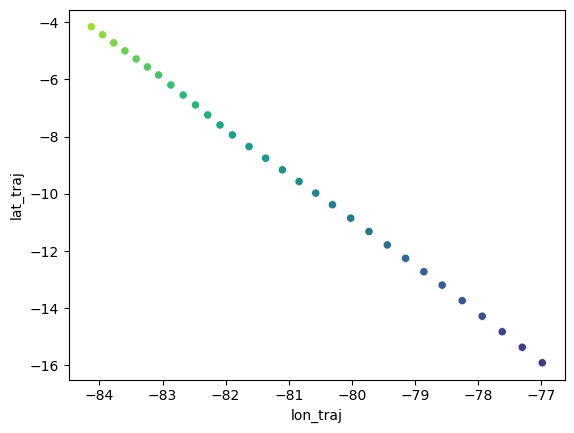

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(data=bt_SEP_hourly.isel(time_startpoint=-250), x='lon_traj', y='lat_traj', hue='datetime_traj', palette='viridis', legend=False)

In [11]:
judge_SEP

,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,cwp_inhomogeneity,cloud_cover,cats,cert,orbit
8076,6713.5,2025-08-01 19:20:13.001890432,-81.134491,-3.123252,-3.594370,-2.553954,0.000000,0.425669,0.655842,0.649048,0,0.996752,06688E
8077,6841.5,2025-08-01 19:20:21.065958016,-81.231903,-3.645530,-4.116602,-3.072109,0.000000,0.667343,0.507543,0.186340,5,0.740059,06688E
8078,6969.5,2025-08-01 19:20:29.130020928,-81.329315,-4.167780,-4.638803,-3.594370,0.000000,2.307270,0.503297,0.023193,5,0.922859,06688E
8079,7097.5,2025-08-01 19:20:37.194084992,-81.426971,-4.690002,-5.160964,-4.116602,0.000000,1.736786,0.573025,0.147766,5,0.671431,06688E
8080,7225.5,2025-08-01 19:20:45.258147968,-81.524803,-5.212184,-5.683081,-4.638803,0.000000,0.787753,0.785876,0.464905,0,0.912918,06688E
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8888,10805.5,2025-08-31 19:42:52.828575872,-88.973877,-19.815862,-20.283984,-19.242703,0.350342,2.052217,0.845203,0.969604,3,0.774081,07155E
8889,10933.5,2025-08-31 19:43:00.892639936,-89.079163,-20.336534,-20.804462,-19.763390,0.338501,2.016538,0.649727,0.996277,0,0.979926,07155E
8890,11061.5,2025-08-31 19:43:08.956703040,-89.184990,-20.857090,-21.324853,-20.283984,0.052551,2.718789,0.867891,0.947083,3,0.544055,07155E
8891,11189.5,2025-08-31 19:43:17.020770496,-89.291214,-21.377560,-21.845175,-20.804462,0.002441,2.368745,1.096538,0.832764,3,0.631883,07155E


# Find crossings with EC

In [70]:
def find_trajectory_crossings(bt_SEP, judge_SEP, time_tolerance='2H', lat_tolerance=0.5, lon_tolerance=0.5):
    """
    Find where backtrajectories cross near other judge_SEP data points.
    
    Parameters:
    -----------
    bt_SEP : xarray.Dataset
        Backtrajectory data with dimensions (time_startpoint, timestep)
    judge_SEP : pandas.DataFrame
        DataFrame with columns 'time_mid', 'lat_mid', 'lon_mid'
    time_tolerance : str
        Time tolerance for matching (e.g., '6H', '1D')
    lat_tolerance : float
        Latitude tolerance in degrees
    lon_tolerance : float
        Longitude tolerance in degrees
    
    Returns:
    --------
    pandas.DataFrame
        DataFrame with crossing information
    """
    crossings = []
    
    # Convert judge_SEP time_mid to datetime
    judge_SEP = judge_SEP.copy()
    judge_SEP['time_mid'] = pd.to_datetime(judge_SEP['time_mid'])
    
    # Iterate through each trajectory startpoint
    for i, startpoint_time in enumerate(bt_SEP.time_startpoint.values):
        traj = bt_SEP.isel(time_startpoint=i)
        info_startpoint = judge_SEP[np.abs(pd.to_datetime(judge_SEP.time_mid) - startpoint_time) < pd.Timedelta('0.001s')]
        if len(info_startpoint) == 0:
            continue
        elif len(info_startpoint) > 1:
            print(f'Warning: Multiple judge_SEP entries found for trajectory startpoint index {i}, time {startpoint_time}')
            continue
        orbit_startpoint = info_startpoint['orbit'].values[0]
        cats_startpoint = info_startpoint['cats'].values[0]

        
        # For each point along this trajectory
        for j, timestep in enumerate(traj.timestep.values):
            traj_time = pd.to_datetime(traj.datetime_traj.values[j])
            traj_lat = float(traj.lat_traj.values[j])
            traj_lon = float(traj.lon_traj.values[j])
            
            # Skip if NaN values
            if pd.isna(traj_time) or pd.isna(traj_lat) or pd.isna(traj_lon):
                continue
            
            # Find judge_SEP points that are close in time, lat, and lon
            time_mask = abs(judge_SEP['time_mid'] - traj_time) <= pd.Timedelta(time_tolerance)
            lat_mask = abs(judge_SEP['lat_mid'] - traj_lat) <= lat_tolerance
            lon_mask = abs(judge_SEP['lon_mid'] - traj_lon) <= lon_tolerance
            
            nearby_points = judge_SEP[time_mask & lat_mask & lon_mask]
            
            # Exclude the original startpoint and surrounding points (if it exists in the data)
            startpoint_time_pd = pd.to_datetime(startpoint_time)
            nearby_points = nearby_points[
                abs(nearby_points['time_mid'] - startpoint_time_pd) > pd.Timedelta('1h')
            ]
            
            # Record crossings
            for idx, row in nearby_points.iterrows():
                crossings.append({
                    'traj_startpoint_idx': i,
                    'traj_startpoint_time': startpoint_time_pd,
                    'traj_timestep': timestep,
                    'traj_time': traj_time,
                    'traj_lat': traj_lat,
                    'traj_lon': traj_lon,
                    'judge_idx': idx,
                    'judge_time': row['time_mid'],
                    'judge_lat': row['lat_mid'],
                    'judge_lon': row['lon_mid'],
                    'time_diff': abs(row['time_mid'] - traj_time),
                    'lat_diff': abs(row['lat_mid'] - traj_lat),
                    'lon_diff': abs(row['lon_mid'] - traj_lon),
                    'orbit_startpoint': orbit_startpoint,
                    'cats_startpoint': cats_startpoint,
                    'orbit_crossing': row['orbit'],
                    'cats_crossing': row['cats']
                })
    
    return pd.DataFrame(crossings)

# Usage example:
crossings = find_trajectory_crossings(bt_SEP_hourly, judge_SEP, 
                                    time_tolerance='2H', 
                                    lat_tolerance=0.5, 
                                    lon_tolerance=0.5)

print(f"Found {len(crossings)} trajectory crossings")
if len(crossings) > 0:
    print(crossings.head())

/tmp/ipykernel_774759/1630461626.py:53: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  time_mask = abs(judge_SEP['time_mid'] - traj_time) <= pd.Timedelta(time_tolerance)
/tmp/ipykernel_774759/1630461626.py:53: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  time_mask = abs(judge_SEP['time_mid'] - traj_time) <= pd.Timedelta(time_tolerance)
/tmp/ipykernel_774759/1630461626.py:53: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  time_mask = abs(judge_SEP['time_mid'] - traj_time) <= pd.Timedelta(time_tolerance)
/tmp/ipykernel_774759/1630461626.py:53: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  time_mask = abs(judge_SEP['time_mid'] - traj_time) <= pd.Timedelta(time_tolerance)
/tmp/ipykernel_774759/1630461626.py:53: FutureWarning: 'H' is deprecated and wil

Found 46 trajectory crossings
   traj_startpoint_idx          traj_startpoint_time  traj_timestep  \
0                   25 2025-08-01 19:23:34.603489984             28   
1                   26 2025-08-01 19:23:42.667553984             28   
2                   27 2025-08-01 19:23:50.731617024             28   
3                  511 2025-08-21 19:06:15.551768960             27   
4                  512 2025-08-21 19:06:23.615832512             27   

            traj_time   traj_lat   traj_lon  judge_idx  \
0 2025-08-02 22:00:00  -9.718029 -92.021710       8125   
1 2025-08-02 22:00:00 -10.453189 -92.280403       8127   
2 2025-08-02 22:00:00 -11.469216 -92.504939       8129   
3 2025-08-22 21:00:00 -12.525370 -88.030123       8608   
4 2025-08-22 21:00:00 -13.440763 -88.095483       8609   

                     judge_time  judge_lat  judge_lon  \
0 2025-08-02 20:02:32.318329920  -9.390472 -92.491165   
1 2025-08-02 20:02:48.446456960 -10.434150 -92.689125   
2 2025-08-02 20:03:04.5

/tmp/ipykernel_774759/1630461626.py:53: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  time_mask = abs(judge_SEP['time_mid'] - traj_time) <= pd.Timedelta(time_tolerance)
/tmp/ipykernel_774759/1630461626.py:53: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  time_mask = abs(judge_SEP['time_mid'] - traj_time) <= pd.Timedelta(time_tolerance)
/tmp/ipykernel_774759/1630461626.py:53: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  time_mask = abs(judge_SEP['time_mid'] - traj_time) <= pd.Timedelta(time_tolerance)
/tmp/ipykernel_774759/1630461626.py:53: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  time_mask = abs(judge_SEP['time_mid'] - traj_time) <= pd.Timedelta(time_tolerance)
/tmp/ipykernel_774759/1630461626.py:53: FutureWarning: 'H' is deprecated and wil

In [72]:
crossings

,traj_startpoint_idx,traj_startpoint_time,traj_timestep,traj_time,traj_lat,traj_lon,judge_idx,judge_time,judge_lat,judge_lon,time_diff,lat_diff,lon_diff,orbit_startpoint,cats_startpoint,orbit_crossing,cats_crossing
0,25,2025-08-01 19:23:34.603489984,28,2025-08-02 22:00:00,-9.718029,-92.021710,8125,2025-08-02 20:02:32.318329920,-9.390472,-92.491165,0 days 01:57:27.681670080,0.327557,0.469456,06688E,5,06704E,2
1,26,2025-08-01 19:23:42.667553984,28,2025-08-02 22:00:00,-10.453189,-92.280403,8127,2025-08-02 20:02:48.446456960,-10.434150,-92.689125,0 days 01:57:11.553543040,0.019039,0.408723,06688E,5,06704E,1
2,27,2025-08-01 19:23:50.731617024,28,2025-08-02 22:00:00,-11.469216,-92.504939,8129,2025-08-02 20:03:04.574584064,-11.477677,-92.887909,0 days 01:56:55.425415936,0.008461,0.382970,06688E,5,06704E,1
3,511,2025-08-21 19:06:15.551768960,27,2025-08-22 21:00:00,-12.525370,-88.030123,8608,2025-08-22 19:44:50.461072000,-12.520886,-88.491951,0 days 01:15:09.538928,0.004484,0.461828,06999E,3,07015E,3
4,512,2025-08-21 19:06:23.615832512,27,2025-08-22 21:00:00,-13.440763,-88.095483,8609,2025-08-22 19:44:58.525135488,-13.042422,-88.592422,0 days 01:15:01.474864512,0.398341,0.496940,06999E,3,07015E,3
5,530,2025-08-22 19:44:34.332945024,-24,2025-08-21 18:00:00,-18.701955,-79.918929,8582,2025-08-21 19:05:35.231451136,-18.254098,-79.427467,0 days 01:05:35.231451136,0.447857,0.491461,07015E,3,06999E,0
6,530,2025-08-22 19:44:34.332945024,-24,2025-08-21 18:00:00,-18.701955,-79.918929,8583,2025-08-21 19:05:43.295514048,-18.774957,-79.531319,0 days 01:05:43.295514048,0.073002,0.387610,07015E,3,06999E,0
7,531,2025-08-22 19:44:42.397008000,-24,2025-08-21 18:00:00,-19.001517,-79.683888,8583,2025-08-21 19:05:43.295514048,-18.774957,-79.531319,0 days 01:05:43.295514048,0.226560,0.152569,07015E,2,06999E,0
8,531,2025-08-22 19:44:42.397008000,-24,2025-08-21 18:00:00,-19.001517,-79.683888,8584,2025-08-21 19:05:51.359577984,-19.295739,-79.635612,0 days 01:05:51.359577984,0.294222,0.048275,07015E,2,06999E,0
9,531,2025-08-22 19:44:42.397008000,-23,2025-08-21 19:00:00,-18.668654,-79.937339,8583,2025-08-21 19:05:43.295514048,-18.774957,-79.531319,0 days 00:05:43.295514048,0.106304,0.406020,07015E,2,06999E,0


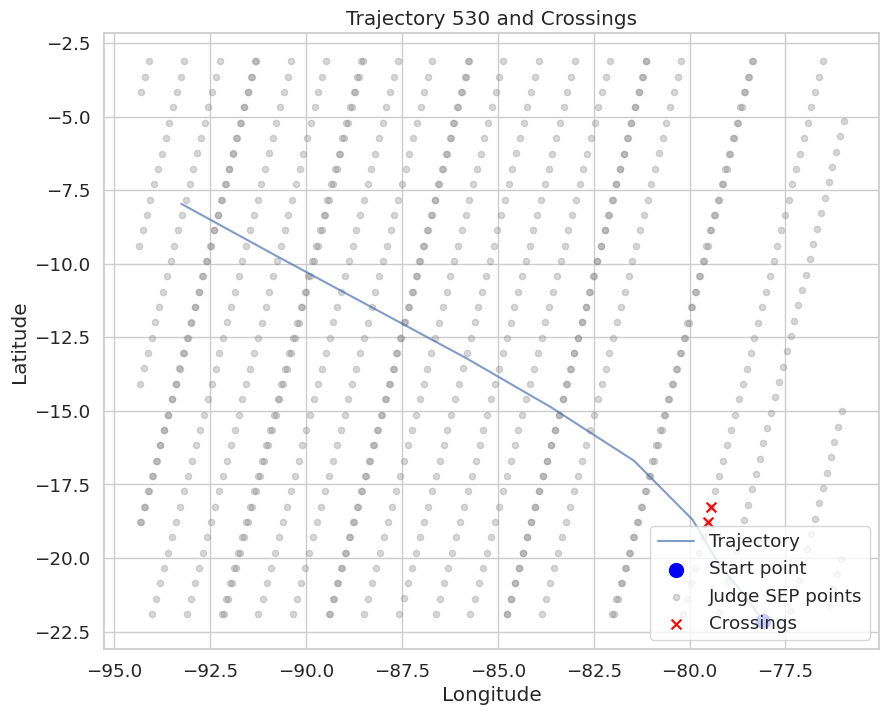

In [55]:
def plot_trajectory_crossings(bt_SEP, judge_SEP, crossings, traj_idx=0):
    """
    Plot a specific trajectory and its crossings with judge_SEP data.
    """
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    
    # Plot the trajectory
    traj = bt_SEP.isel(time_startpoint=traj_idx)
    ax.plot(traj.lon_traj, traj.lat_traj, 'b-', alpha=0.7, label='Trajectory')
    
    # Plot trajectory startpoint
    ax.scatter(traj.lon_traj[0], traj.lat_traj[0], c='blue', s=100, marker='o', label='Start point')
    
    # Plot all judge_SEP points
    ax.scatter(judge_SEP.lon_mid, judge_SEP.lat_mid, c='gray', s=20, alpha=0.3, label='Judge SEP points')
    
    # Highlight crossings for this trajectory
    traj_crossings = crossings[crossings.traj_startpoint_idx == traj_idx]
    if len(traj_crossings) > 0:
        ax.scatter(traj_crossings.judge_lon, traj_crossings.judge_lat, 
                  c='red', s=50, marker='x', label='Crossings')
    
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.legend()
    ax.set_title(f'Trajectory {traj_idx} and Crossings')
    plt.show()

# Example usage:
if len(crossings) > 0:
    plot_trajectory_crossings(bt_SEP, judge_SEP, crossings, traj_idx=530)

# Find crossings with GOES

In [12]:
def add_goes_matches_to_trajectories(bt_SEP, judge_results_goes, time_tolerance_hours=2):
    """
    Add GOES data matches to each trajectory point in bt_SEP.
    First filters by time tolerance, then finds best spatial match.
    
    Parameters:
    -----------
    bt_SEP : xarray.Dataset
        Backtrajectory data
    judge_results_goes : pandas.DataFrame
        GOES data with columns 'datetime', 'lat_mid', 'lon_mid', 'cats'
    time_tolerance_hours : float
        Time tolerance in hours for matching
    
    Returns:
    --------
    xarray.Dataset
        bt_SEP with additional variables for GOES matches
    """
    import numpy as np
    
    # Copy the dataset to avoid modifying the original
    bt_with_goes = bt_SEP.copy()
    
    # Prepare GOES data
    judge_goes = judge_results_goes.copy()
    judge_goes['time_mid'] = pd.to_datetime(judge_goes['datetime'])
    
    # Initialize arrays to store GOES match information
    n_startpoints = len(bt_SEP.time_startpoint)
    n_timesteps = len(bt_SEP.timestep)
    
    goes_lat_match = np.full((n_startpoints, n_timesteps), np.nan)
    goes_lon_match = np.full((n_startpoints, n_timesteps), np.nan)
    goes_time_match = np.full((n_startpoints, n_timesteps), np.datetime64('NaT'), dtype='datetime64[ns]')
    goes_cats_match = np.full((n_startpoints, n_timesteps), np.nan)
    goes_distance = np.full((n_startpoints, n_timesteps), np.nan)
    goes_time_diff = np.full((n_startpoints, n_timesteps), np.timedelta64('NaT'), dtype='timedelta64[ns]')
    
    print(f"Finding GOES matches for each trajectory point (time tolerance: {time_tolerance_hours}h)...")
    
    for i in range(n_startpoints):
        if i % 100 == 0:
            print(f"Processing trajectory {i}/{n_startpoints}")
            
        traj = bt_SEP.isel(time_startpoint=i)
        
        for j, timestep in enumerate(traj.timestep.values):
            traj_time = pd.to_datetime(traj.datetime_traj.values[j])
            traj_lat = float(traj.lat_traj.values[j])
            traj_lon = float(traj.lon_traj.values[j])
            
            # Skip if NaN values
            if pd.isna(traj_time) or pd.isna(traj_lat) or pd.isna(traj_lon):
                continue
            
            # First, filter by time tolerance
            time_diffs = np.abs((judge_goes['time_mid'] - traj_time).dt.total_seconds() / 3600)  # Convert to hours
            time_mask = time_diffs <= time_tolerance_hours
            
            # If no time matches found, leave as NaN and continue
            if not time_mask.any():
                continue
            
            # Get candidates within time tolerance
            candidate_goes = judge_goes[time_mask]
            candidate_time_diffs = time_diffs[time_mask]
            
            # Calculate spatial distances for candidates only
            lat_diffs = np.abs(candidate_goes['lat_mid'].values - traj_lat)
            lon_diffs = np.abs(candidate_goes['lon_mid'].values - traj_lon)
            spatial_dist = np.sqrt(lat_diffs**2 + lon_diffs**2)
            
            # Find the best spatial match among time candidates
            best_spatial_idx = np.argmin(spatial_dist)
            
            # Get the original index in the full judge_goes DataFrame
            best_idx = candidate_goes.index[best_spatial_idx]
            
            # Store the match information
            goes_lat_match[i, j] = judge_goes.iloc[best_idx]['lat_mid']
            goes_lon_match[i, j] = judge_goes.iloc[best_idx]['lon_mid']
            goes_time_match[i, j] = judge_goes.iloc[best_idx]['time_mid'].to_numpy().astype('datetime64[ns]')
            goes_cats_match[i, j] = judge_goes.iloc[best_idx]['cats']
            goes_distance[i, j] = spatial_dist[best_spatial_idx]  # Store only spatial distance
            
            # Store time difference
            time_diff = judge_goes.iloc[best_idx]['time_mid'] - traj_time
            goes_time_diff[i, j] = np.abs(time_diff).to_numpy().astype('timedelta64[ns]')
    
    # Add new variables to the dataset
    bt_with_goes['goes_lat_match'] = (('time_startpoint', 'timestep'), goes_lat_match)
    bt_with_goes['goes_lon_match'] = (('time_startpoint', 'timestep'), goes_lon_match)
    bt_with_goes['goes_time_match'] = (('time_startpoint', 'timestep'), goes_time_match)
    bt_with_goes['goes_cats_match'] = (('time_startpoint', 'timestep'), goes_cats_match)
    bt_with_goes['goes_match_distance'] = (('time_startpoint', 'timestep'), goes_distance)
    bt_with_goes['match_time_diff'] = (('time_startpoint', 'timestep'), goes_time_diff)
    
    # Add attributes for documentation
    bt_with_goes['goes_lat_match'].attrs = {'description': 'Latitude of best matching GOES observation'}
    bt_with_goes['goes_lon_match'].attrs = {'description': 'Longitude of best matching GOES observation'}
    bt_with_goes['goes_time_match'].attrs = {'description': 'Time of best matching GOES observation'}
    bt_with_goes['goes_cats_match'].attrs = {'description': 'CATS value of best matching GOES observation'}
    bt_with_goes['goes_match_distance'].attrs = {'description': 'Spatial distance to best matching GOES observation (degrees)'}
    bt_with_goes['match_time_diff'].attrs = {'description': 'Time difference to best matching GOES observation'}
    
    return bt_with_goes

In [13]:
judge_results_goes = pd.read_csv('/home/jmayer/ACI_research/Code/resources/judge_results_GOES_SEP.csv')
judge_results_goes = judge_results_goes[pd.to_datetime(judge_results_goes['datetime']).dt.hour != 0]
judge_results_goes.reset_index(drop=True, inplace=True)

In [14]:
judge_results_goes

,datetime,y_idx,x_idx,lon_mid,lat_mid,ice_flag,cats,cert
0,2025-08-01 14:00:00,64,64,-94.553077,-2.903803,0.0,0,0.620706
1,2025-08-01 14:00:00,64,192,-93.293226,-2.900151,0.0,5,0.795706
2,2025-08-01 14:00:00,64,320,-92.047694,-2.896772,0.0,3,0.956322
3,2025-08-01 14:00:00,64,448,-90.815169,-2.893655,0.0,3,0.996656
4,2025-08-01 14:00:00,64,576,-89.594434,-2.890793,0.0,3,0.920730
...,...,...,...,...,...,...,...,...
180913,2025-08-30 22:00:00,2304,1856,-78.136248,-24.277994,0.0,5,0.863577
180914,2025-08-30 22:00:00,2304,1920,-77.492139,-24.275638,0.0,5,0.963100
180915,2025-08-30 22:00:00,2304,1984,-76.848549,-24.273823,0.0,5,0.961691
180916,2025-08-30 22:00:00,2304,2048,-76.205346,-24.272546,0.0,5,0.977540


In [15]:
bt_with_goes2 = add_goes_matches_to_trajectories(bt_SEP_hourly, judge_results_goes)

Finding GOES matches for each trajectory point (time tolerance: 2h)...
Processing trajectory 0/817
Processing trajectory 100/817
Processing trajectory 200/817
Processing trajectory 300/817
Processing trajectory 400/817
Processing trajectory 500/817
Processing trajectory 600/817
Processing trajectory 700/817
Processing trajectory 800/817


In [16]:
orbit_startpoints = []
cats_startpoints = []
for i, startpoint_time in enumerate(bt_with_goes2.time_startpoint.values):
    info_startpoint = judge_SEP[np.abs(pd.to_datetime(judge_SEP.time_mid) - startpoint_time) < pd.Timedelta('0.001s')]
    if len(info_startpoint) == 0:
        orbit_startpoint = np.nan
        cats_startpoint = np.nan
    elif len(info_startpoint) > 1:
        print(f'Warning: Multiple judge_SEP entries found for trajectory startpoint index {i}, time {startpoint_time}')
        orbit_startpoint = np.nan
        cats_startpoint = np.nan
    else:
        orbit_startpoint = info_startpoint['orbit'].values[0]
        cats_startpoint = info_startpoint['cats'].values[0]
    orbit_startpoints.append(orbit_startpoint)
    cats_startpoints.append(cats_startpoint)

In [17]:
bt_with_goes2['orbit_startpoint'] = xr.DataArray(orbit_startpoints, dims='time_startpoint', coords={'time_startpoint': bt_with_goes2.time_startpoint.values})
bt_with_goes2['cats_startpoint'] = xr.DataArray(cats_startpoints, dims='time_startpoint', coords={'time_startpoint': bt_with_goes2.time_startpoint.values})

In [18]:
bt_with_goes2

<xarray.Dataset> Size: 6MB
Dimensions:              (time_startpoint: 817, timestep: 85)
Coordinates:
  * time_startpoint      (time_startpoint) datetime64[ns] 7kB 2025-08-01T19:2...
  * timestep             (timestep) int64 680B -42 -41 -40 -39 ... 39 40 41 42
Data variables:
    lat_traj             (time_startpoint, timestep) float64 556kB nan ... nan
    lon_traj             (time_startpoint, timestep) float64 556kB nan ... nan
    plev_traj            (time_startpoint, timestep) float64 556kB nan ... nan
    datetime_traj        (time_startpoint, timestep) datetime64[ns] 556kB NaT...
    goes_lat_match       (time_startpoint, timestep) float64 556kB nan ... nan
    goes_lon_match       (time_startpoint, timestep) float64 556kB nan ... nan
    goes_time_match      (time_startpoint, timestep) datetime64[ns] 556kB NaT...
    goes_cats_match      (time_startpoint, timestep) float64 556kB nan ... nan
    goes_match_distance  (time_startpoint, timestep) float64 556kB nan ... nan
    match_time_diff      (time_startpoint, timestep) timedelta64[ns] 556kB Na...
    orbit_startpoint     (time_startpoint) <U6 20kB '06688E' ... '07155E'
    cats_startpoint      (time_startpoint) int64 7kB 0 5 5 5 0 0 ... 3 3 0 3 3 3

In [19]:
tmp2 = bt_with_goes2.isel(time_startpoint=200)

In [20]:
tmp2

<xarray.Dataset> Size: 8kB
Dimensions:              (timestep: 85)
Coordinates:
    time_startpoint      datetime64[ns] 8B 2025-08-08T19:29:53.193395904
  * timestep             (timestep) int64 680B -42 -41 -40 -39 ... 39 40 41 42
Data variables:
    lat_traj             (timestep) float64 680B -17.85 -17.64 ... -5.431 -5.248
    lon_traj             (timestep) float64 680B -77.69 -77.89 ... -90.12 -90.25
    plev_traj            (timestep) float64 680B 956.8 956.9 ... 997.6 997.3
    datetime_traj        (timestep) datetime64[ns] 680B 2025-08-07 ... 2025-0...
    goes_lat_match       (timestep) float64 680B -17.81 nan nan ... nan -5.235
    goes_lon_match       (timestep) float64 680B -77.98 nan nan ... nan -90.26
    goes_time_match      (timestep) datetime64[ns] 680B 2025-08-06T22:00:00 ....
    goes_cats_match      (timestep) float64 680B 0.0 nan nan nan ... nan nan 3.0
    goes_match_distance  (timestep) float64 680B 0.2909 nan nan ... nan 0.01337
    match_time_diff      (timestep) timedelta64[ns] 680B 02:00:00 ... 02:00:00
    orbit_startpoint     <U6 24B '06797E'
    cats_startpoint      int64 8B 1

Text(0.5, 1.0, '06797E, cat = 1')

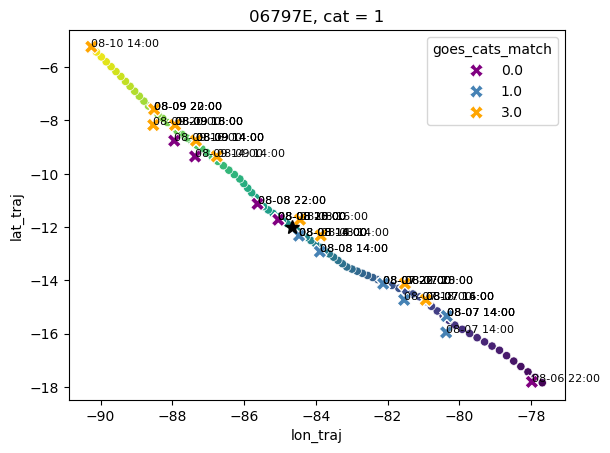

In [21]:
sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='datetime_traj', palette='viridis', legend=False)
plt.plot([tmp2.sel(timestep=0).lon_traj.values], [tmp2.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10)
sns.scatterplot(data=tmp2, x='goes_lon_match', y='goes_lat_match', hue='goes_cats_match', palette=palette_goes_cats, legend=True, s=100, marker='X')
# annotate the goes_time_match values
for i in range(len(tmp2.timestep)):
    if not pd.isna(tmp2.goes_time_match.values[i]):
        plt.text(tmp2.goes_lon_match.values[i], tmp2.goes_lat_match.values[i], 
                 pd.to_datetime(tmp2.goes_time_match.values[i]).strftime('%m-%d %H:%M'), 
                 fontsize=8, color='black')
plt.title(f'{tmp2.orbit_startpoint.values}, cat = {tmp2.cats_startpoint.values}')

In [45]:
bt_C = bt_with_goes2.where(bt_with_goes2.cats_startpoint == 1, drop=True)

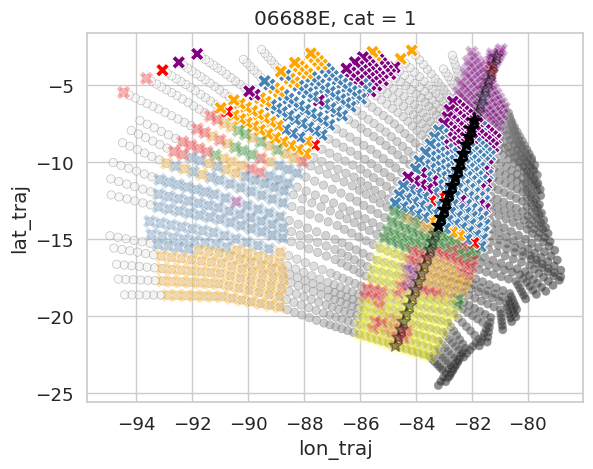

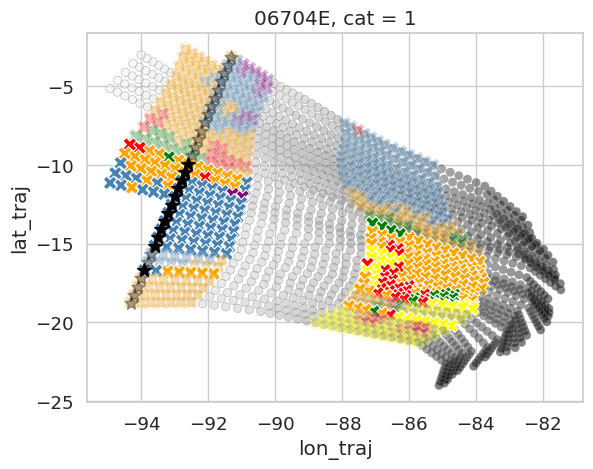

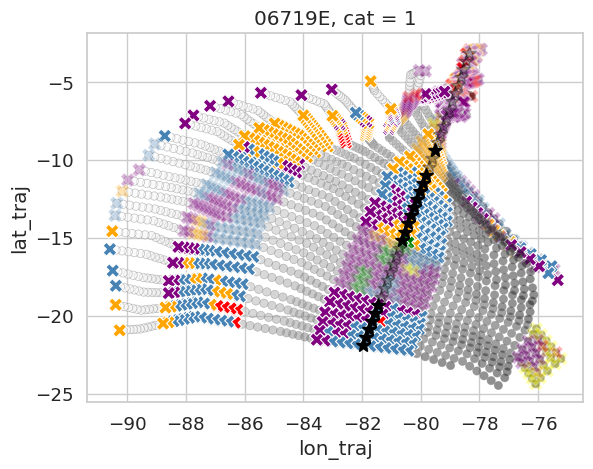

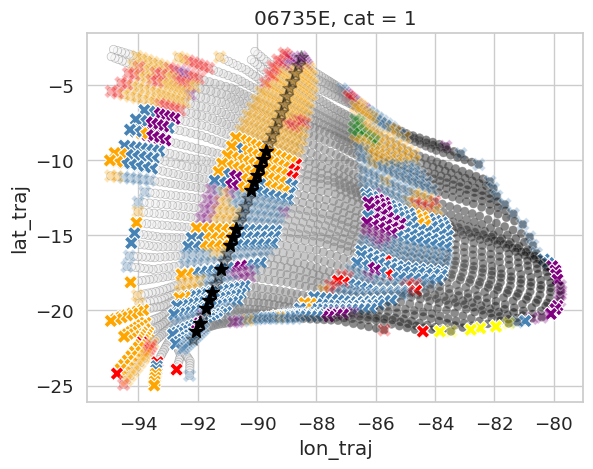

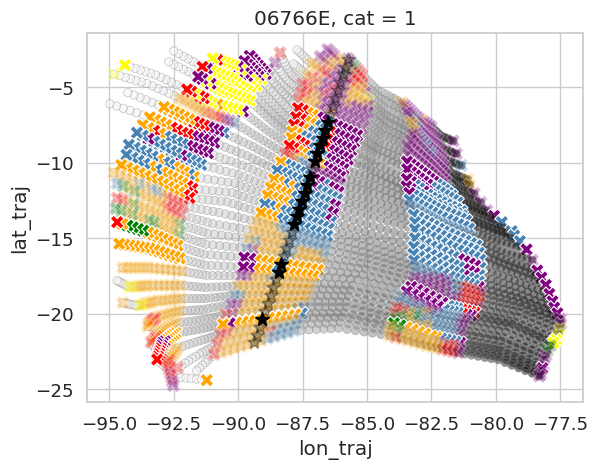

...

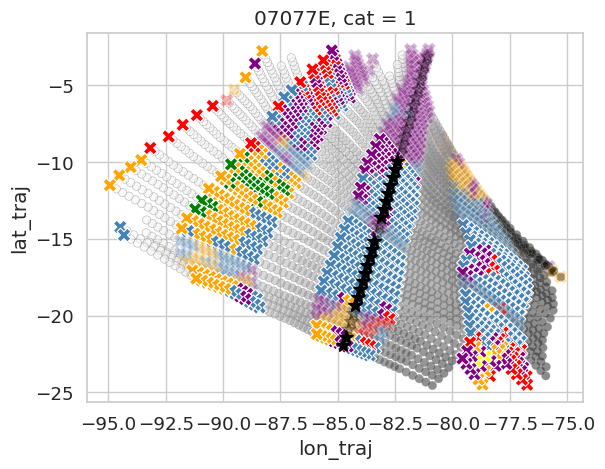

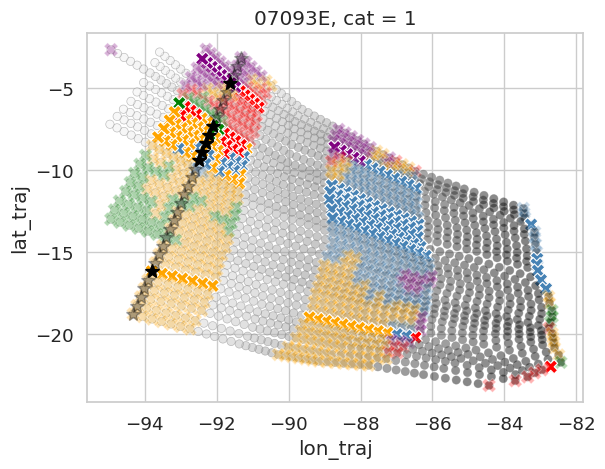

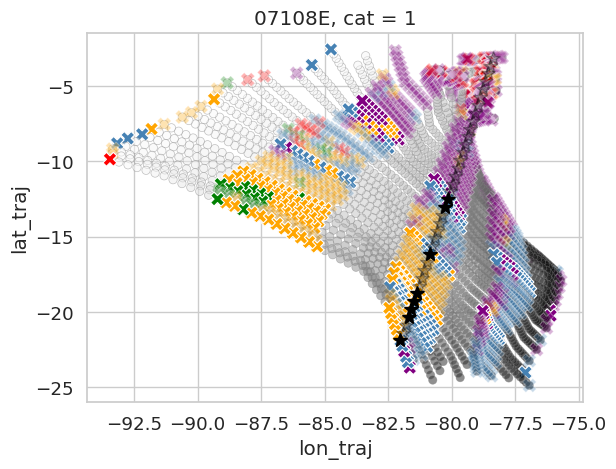

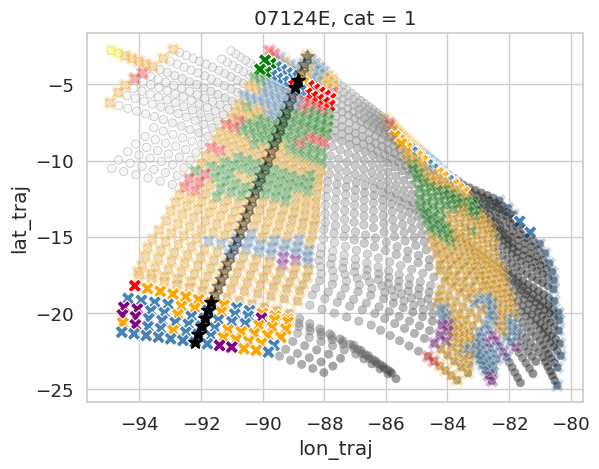

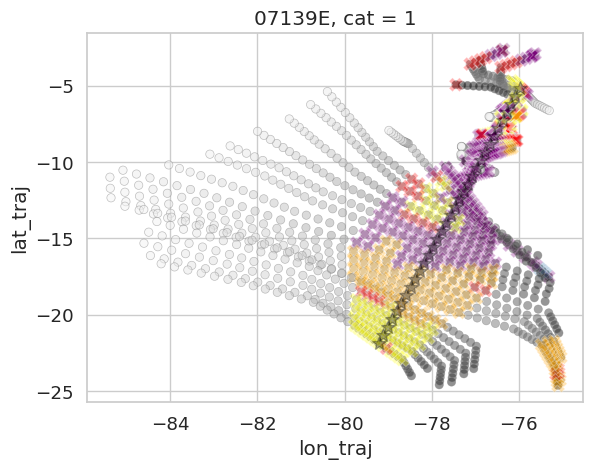

/tmp/ipykernel_3022862/3495319969.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_3022862/3495319969.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_3022862/3495319969.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)


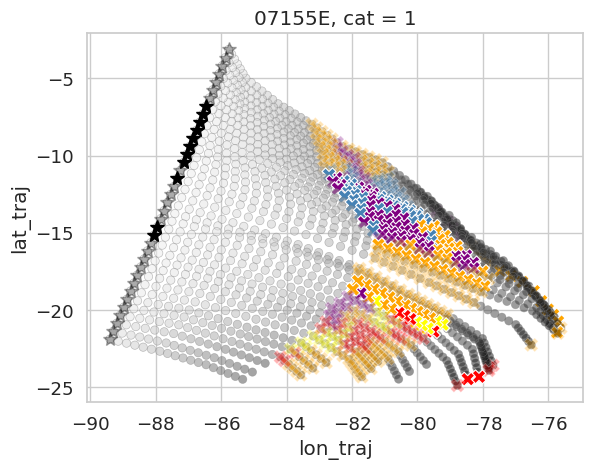

In [46]:
for orbit in np.unique(bt_with_goes2.orbit_startpoint):
    bt_orbit = bt_with_goes2.where(bt_with_goes2.orbit_startpoint == orbit, drop=True)
    for i in range(len(bt_orbit.time_startpoint)):
        tmp2 = bt_orbit.isel(time_startpoint=i)
        if tmp2.cats_startpoint == 1:
            alpha = 1.0
        else:
            alpha = 0.3
        sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='datetime_traj', palette='Greys_r', alpha=0.5, edgecolor='Grey', legend=False)
        plt.plot([tmp2.sel(timestep=0).lon_traj.values], [tmp2.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10, alpha=alpha)
        sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
        plt.title(f'{orbit}, cat = 1')
    plt.show()

In [ ]:
for i in range(len(bt_C.time_startpoint)):
    #tmp2 = bt_C.isel(time_startpoint=i)
    #orbit = tmp2.orbit_startpoint.values
    #if i != 0 and orbit != orbit_previous:
    #    plt.show()
    #sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='datetime_traj', palette='viridis', legend=False)
    #plt.plot([tmp2.sel(timestep=0).lon_traj.values], [tmp2.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10)
    #sns.scatterplot(data=tmp2, x='goes_lon_match', y='goes_lat_match', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=100, marker='X')
    #plt.title(f'{orbit}, cat = {tmp2.cats_startpoint.values}')
    #orbit_previous = orbit

    tmp2 = bt_C.isel(time_startpoint=i)
    orbit = tmp2.orbit_startpoint.values
    if i != 0 and orbit != orbit_previous:
        plt.show()
    sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='datetime_traj', palette='Greys_r', alpha=0.5, edgecolor='Grey', legend=False)
    plt.plot([tmp2.sel(timestep=0).lon_traj.values], [tmp2.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10)
    sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=100, marker='X')
    plt.title(f'{orbit}, cat = {tmp2.cats_startpoint.values}')
    orbit_previous = orbit

In [25]:
bt_O = bt_with_goes2.where(bt_with_goes2.cats_startpoint == 2, drop=True)

In [ ]:
for i in range(len(bt_O.time_startpoint)):
    tmp2 = bt_O.isel(time_startpoint=i)
    orbit = tmp2.orbit_startpoint.values
    if i != 0 and orbit != orbit_previous:
        plt.show()
    sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='datetime_traj', palette='viridis', legend=False)
    plt.plot([tmp2.sel(timestep=0).lon_traj.values], [tmp2.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10)
    sns.scatterplot(data=tmp2, x='goes_lon_match', y='goes_lat_match', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=100, marker='X')
    plt.title(f'{orbit}, cat = {tmp2.cats_startpoint.values}')
    orbit_previous = orbit

In [ ]:
for i in range(len(bt_O.time_startpoint)):
    tmp2 = bt_O.isel(time_startpoint=i)
    orbit = tmp2.orbit_startpoint.values
    if i != 0 and orbit != orbit_previous:
        plt.show()
    sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='datetime_traj', palette='Greys_r', alpha=0.5, edgecolor='Grey', legend=False)
    plt.plot([tmp2.sel(timestep=0).lon_traj.values], [tmp2.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10)
    sns.scatterplot(data=tmp2, x='lon_traj', y='lat_traj', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=100, marker='X')
    plt.title(f'{orbit}, cat = {tmp2.cats_startpoint.values}')
    orbit_previous = orbit

## plot time series of GOES alolng trajectories

In [14]:
from scipy.ndimage import zoom
from functions_for_goes import crop_goes_to_latlon_box, convert_radiance_to_brightness_temp
import seaborn as sns
import matplotlib.pyplot as plt

# SEP region (Southeast Pacific)
lat_bounds = (-22.5, -2.5)
lon_bounds = (-95, -75)

In [ ]:
orbit = '06766E'
include_IR_obs = True

bt_orbit = bt_with_goes2.where(bt_with_goes2.orbit_startpoint == orbit, drop=True)
overpass_date = str(bt_orbit.time_startpoint[0].dt.strftime('%Y%m%d').values)
valid_dates = np.abs(bt_orbit.datetime_traj - bt_orbit.time_startpoint[0]) < np.timedelta64(42, 'h')
bt_orbit = bt_orbit.where(valid_dates)
dates0 = np.unique(bt_orbit.datetime_traj[0].dt.strftime('%Y%m%d').dropna('timestep'))
dates1 = np.unique(bt_orbit.datetime_traj[-1].dt.strftime('%Y%m%d').dropna('timestep'))
dates = np.unique(np.concatenate((dates0, dates1)))


if include_IR_obs:
    goes_times = ['00', '02', '04', '06', '08', '10', '12', '14', '16', '18', '20', '22']
else:
    goes_times = ['14', '16', '18', '20', '22']
overpass_time = '19'
#overpass_time = str(bt_orbit.time_startpoint[0].dt.strftime('%H%M').values)
for date in dates:
    for goes_time in goes_times: # GOES times in UTC hours
        timestep = (pd.to_datetime(date+str(goes_time).zfill(2)+'00') - pd.to_datetime(overpass_date+str(overpass_time).zfill(2)+'00')).total_seconds() / 3600
        print(timestep)
        if timestep < bt_orbit.timestep.min() or timestep > bt_orbit.timestep.max():
            continue

        with xr.open_dataset(f'/home/jmayer/Object_Data/GOES19/goes19_CODF_{date}_{goes_time}00.nc') as ds:
            # Crop to your region
            ds_COD_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

        if include_IR_obs:
            with xr.open_dataset(f'/home/jmayer/Object_Data/GOES19/goes19_C14_RadF_{date}_{goes_time}00.nc') as ds:
                # Convert to brightness temperature
                ds = convert_radiance_to_brightness_temp(ds)
                # Crop to your region
                ds_14_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

        if include_IR_obs:
            fig, axs = plt.subplots(1, 2, figsize=(20, 7))
            plt.suptitle(f'{date} {goes_time} UTC, GOES-19')

            # Store the return value from pcolormesh
            img1 = axs[0].pcolormesh(ds_COD_cropped.longitude, ds_COD_cropped.latitude, ds_COD_cropped['COD'], 
                        vmax=35, cmap='Greys_r', shading='auto')
            # Fix: Use 'mappable' parameter, not 'img'
            plt.colorbar(img1, ax=axs[0], label='Cloud Optical Depth (COD)')

            img2 = axs[1].pcolormesh(ds_14_cropped.longitude, ds_14_cropped.latitude, ds_14_cropped['BT'], 
                        vmin=280, vmax=290, cmap='Greys', shading='auto')
            plt.colorbar(img2, ax=axs[1], label='Band 14 Brightness Temperature (11.19 $\mu$m) / K')

            for ax in axs:
                ax.set_xlabel('Longitude')
                ax.set_ylabel('Latitude')
                ax.set_ylim(lat_bounds)
                ax.set_xlim(lon_bounds)

                bt_startpoint = bt_orbit.sel(timestep=0)
                ax.plot(bt_startpoint.lon_traj.values, bt_startpoint.lat_traj.values, color='red', lw=3)#, label=f'EC track ({orbit})')

                bt_at_sel_timestep = bt_orbit.sel(timestep=timestep)
                ax.scatter(bt_at_sel_timestep.lon_traj.values, bt_at_sel_timestep.lat_traj.values, color='blue', marker='o', alpha=0.7) #, label=f'{timestep}h from EC overpass')
                #sns.scatterplot(x=bt_at_sel_timestep.lon_traj, y=bt_at_sel_timestep.lat_traj, 
                #                hue=bt_at_sel_timestep.goes_cats_match, palette=palette_goes_cats, marker='o', alpha=0.9, legend=False) #, label=f'{timestep}h from EC overpass')

                for i in range(len(bt_orbit.time_startpoint)//5):
                    traj = bt_orbit.isel(time_startpoint=i*5).sortby('timestep')
                    ax.plot(traj.lon_traj.values, traj.lat_traj.values, color='blue', lw=1, alpha=0.7)

                ax.legend(handles=[plt.Line2D([0], [0], color='red', lw=3, label='EC track'),
                    plt.Line2D([0], [0], marker='o', color='w', label=f'$\Delta$t = {timestep}h',
                        markerfacecolor='blue', markersize=10)],
                    loc='upper right')

            os.makedirs(f'/home/jmayer/ACI_research/Code/mesoscale_structure/figures_bt/{orbit}/', exist_ok=True)
            plt.savefig(f'/home/jmayer/ACI_research/Code/mesoscale_structure/figures_bt/{orbit}/bt_{orbit}_{date}_{goes_time}00.png', dpi=300)
            plt.show()

        else:
            plt.figure(figsize=(10, 7))
            plt.pcolormesh(ds_COD_cropped.longitude, ds_COD_cropped.latitude, ds_COD_cropped['COD'], 
                        vmax=35, cmap='Greys_r', shading='auto')
            plt.colorbar(label='Cloud Optical Depth (COD)')
            plt.xlabel('Longitude')
            plt.ylabel('Latitude')
            plt.title(f'{date} {goes_time} UTC, GOES-19')

            bt_startpoint = bt_orbit.sel(timestep=0)
            plt.plot(bt_startpoint.lon_traj.values, bt_startpoint.lat_traj.values, color='red', lw=3)#, label=f'EC track ({orbit})')

            bt_at_sel_timestep = bt_orbit.sel(timestep=timestep)
            #plt.scatter(bt_at_sel_timestep.lon_traj.values, bt_at_sel_timestep.lat_traj.values, color='blue', marker='o', alpha=0.7, label=f'{timestep}h from EC overpass')
            sns.scatterplot(x=bt_at_sel_timestep.lon_traj, y=bt_at_sel_timestep.lat_traj, 
                            hue=bt_at_sel_timestep.goes_cats_match, palette=palette_goes_cats, marker='o', alpha=0.9, legend=False) #, label=f'{timestep}h from EC overpass')

            for i in range(len(bt_orbit.time_startpoint)//5):
                traj = bt_orbit.isel(time_startpoint=i*5).sortby('timestep')
                plt.plot(traj.lon_traj.values, traj.lat_traj.values, color='blue', lw=1, alpha=0.7)

            plt.legend(handles=[plt.Line2D([0], [0], color='red', lw=3, label='EC track'),
                plt.Line2D([0], [0], marker='o', color='w', label=f'{timestep}h from EC overpass',
                    markerfacecolor='grey', markersize=10)],
                loc='upper right')
            plt.ylim(lat_bounds)
            plt.xlim(lon_bounds)
            os.makedirs(f'/home/jmayer/ACI_research/Code/mesoscale_structure/figures_bt/{orbit}/', exist_ok=True)
            plt.savefig(f'/home/jmayer/ACI_research/Code/mesoscale_structure/figures_bt/{orbit}/bt_{orbit}_{date}_{goes_time}00.png', dpi=300)
            plt.show()

## retrieve time to/from transitions

In [19]:
def get_transition_properties(bt_dataset, transition_from_msi_cats=[2], transition_to_goes_cats=[0,1], backward=True):
    """
    Find where trajectories transition from open cell types (3,4) to stratiform types (0,1)
    going backwards in time from timestep=0.
    
    Parameters:
    -----------
    bt_dataset : xarray.Dataset
        Dataset with goes_cats_match, datetime_traj variables
    transition_from_msi_cats : list
        List of MSI categories to transition from (default: [2])
    transition_to_goes_cats : list
        List of GOES categories to transition to (default: [0, 1])
    backward : bool
        Whether to search backwards in time (default: True)

    Returns:
    --------
    xarray.Dataset
        Dataset with added variables:
        - transition_timestep: timestep where transition occurs (first stratiform point)
        - transition_datetime: datetime at transition (mean between last non-stratiform and first stratiform)
        - transition_time_diff: time difference from timestep=0 to transition
        - transition_uncertainty: time uncertainty of transition (half the time difference between last non-stratiform and first stratiform)
    """
    goes_cats_corresponding_to_msi_cats = {
        0: [0, 1],  # Stratiform
        1: [0, 1],  # Stratiform
        2: [2, 3, 4],     # Open cell
        3: [3, 4],  
        4: [4],
        5: [5]
        }  
    
    # Get dimensions
    n_startpoints = len(bt_dataset.time_startpoint)
    
    # Initialize arrays for results
    transition_timestep = np.full(n_startpoints, np.nan)
    transition_datetime = np.full(n_startpoints, np.datetime64('NaT'), dtype='datetime64[ns]')
    transition_time_diff = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    transition_uncertainty = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    
    # Get timesteps sorted from 0 to negative values
    timesteps = bt_dataset.timestep.values
    if backward:
        timesteps_sorted = np.sort(timesteps)[::-1]  # Descending order: 0, -1, -2, ...
    else:
        timesteps_sorted = np.sort(timesteps)  # Ascending order: 0, 1, 2, ...
    
    for i in range(n_startpoints):
        traj = bt_dataset.isel(time_startpoint=i)
        
        # Check if timestep=0 has the correct goes category to start from
        msi_cat_at_zero = float(traj.cats_startpoint.values)
        goes_cat_at_zero = float(traj.sel(timestep=0).goes_cats_match.values)
        if msi_cat_at_zero not in transition_from_msi_cats:
            continue  # Skip if not starting from desired MSI category
        allowed_goes_cats_at_zero = goes_cats_corresponding_to_msi_cats[msi_cat_at_zero]
        if pd.isna(goes_cat_at_zero) or goes_cat_at_zero not in allowed_goes_cats_at_zero:
            continue  # Skip if GOES category at timestep=0 is not matching the desired starting category
        
        # Get the datetime at timestep=0 for reference
        reference_datetime = traj.sel(timestep=0).datetime_traj.values
            
        # Look through timesteps from 0 backwards to find transition
        last_non_stratiform_timestep = None
        last_non_stratiform_datetime = None
        first_stratiform_timestep = None
        first_stratiform_datetime = None
        
        for timestep in timesteps_sorted:
            if backward and timestep > 0:
                continue  # Only look at timestep=0 and negative values
            elif not backward and timestep < 0:
                continue  # Only look at timestep=0 and positive values
                
            try:
                cats_value = float(traj.sel(timestep=timestep).goes_cats_match.values)
                
                # Skip if NaN
                if pd.isna(cats_value):
                    continue
                
                # Check if this is stratiform (0 or 1)
                if cats_value in transition_to_goes_cats:
                    # Found first stratiform point
                    first_stratiform_timestep = timestep
                    first_stratiform_datetime = traj.sel(timestep=timestep).datetime_traj.values
                    break
                else:
                    # This is non-stratiform, update last non-stratiform
                    last_non_stratiform_timestep = timestep
                    last_non_stratiform_datetime = traj.sel(timestep=timestep).datetime_traj.values
                    
            except (KeyError, ValueError):
                continue  # Skip if timestep doesn't exist or other errors
        
        # If we found a transition, calculate the mean time and uncertainty
        if (first_stratiform_timestep is not None and 
            last_non_stratiform_timestep is not None and 
            first_stratiform_datetime is not None and 
            last_non_stratiform_datetime is not None):
            
            # Convert to pandas datetime for easier arithmetic
            first_strat_dt = pd.to_datetime(first_stratiform_datetime)
            last_non_strat_dt = pd.to_datetime(last_non_stratiform_datetime)
            ref_dt = pd.to_datetime(reference_datetime)
            
            # Calculate mean time between last non-stratiform and first stratiform
            mean_transition_time = last_non_strat_dt + (first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate uncertainty (half the time difference between the two points)
            uncertainty = (first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate time difference from timestep=0 to mean transition time
            time_diff_to_transition = ref_dt - mean_transition_time
            
            # Store results
            transition_timestep[i] = first_stratiform_timestep
            transition_datetime[i] = mean_transition_time.to_numpy().astype('datetime64[ns]')
            transition_time_diff[i] = time_diff_to_transition.to_numpy().astype('timedelta64[ns]')
            transition_uncertainty[i] = uncertainty.to_numpy().astype('timedelta64[ns]')
    
    # Add results to dataset
    result = bt_dataset.copy()
    result['transition_timestep'] = xr.DataArray(transition_timestep, dims='time_startpoint')
    result['transition_datetime'] = xr.DataArray(transition_datetime, dims='time_startpoint')
    result['transition_time_diff'] = xr.DataArray(transition_time_diff, dims='time_startpoint')
    result['transition_uncertainty'] = xr.DataArray(transition_uncertainty, dims='time_startpoint')
    result['transition_time_diff'] = result.transition_time_diff.dt.total_seconds() / 3600
    result['transition_uncertainty'] = result.transition_uncertainty.dt.total_seconds() / 3600

    # Add attributes
    result['transition_timestep'].attrs = {'description': 'Timestep where transition from open to stratiform occurs (timestep of first stratiform point)'}
    result['transition_datetime'].attrs = {'description': 'Mean datetime at transition point (mean between last non-stratiform and first stratiform)'}
    result['transition_time_diff'].attrs = {'description': 'Time difference from timestep=0 to mean transition time (positive means transition is earlier)'}
    result['transition_uncertainty'].attrs = {'description': 'Uncertainty in transition time (half the time between last non-stratiform and first stratiform)'}
    
    return result

Transition statistics:
Trajectories with transitions: 60
Total trajectories: 81

Transition time statistics:
Mean age: 0 days 00:00:00.000000019
Median age: 0 days 00:00:00.000000019


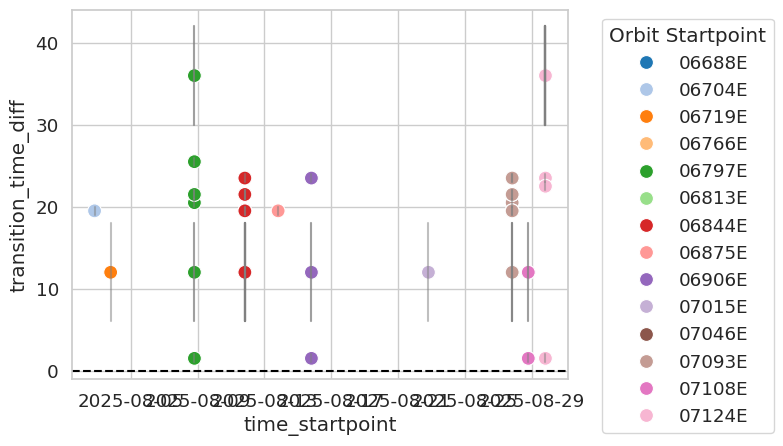

In [20]:
# Apply to your open cell trajectories
bt_O = bt_with_goes2.where(bt_with_goes2.cats_startpoint == 2, drop=True)
bt_co_back_from_o = get_transition_properties(bt_O, transition_from_msi_cats=[2], transition_to_goes_cats=[0,1], backward=True)

# Check results
print("Transition statistics:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co_back_from_o.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co_back_from_o.time_startpoint)}")

# Print statistics about transition times and uncertainties
valid_transitions = ~pd.isna(bt_co_back_from_o.transition_timestep.values)
transition_times = pd.to_timedelta(bt_co_back_from_o.transition_time_diff.values[valid_transitions])
uncertainties = pd.to_timedelta(bt_co_back_from_o.transition_uncertainty.values[valid_transitions])
print(f"\nTransition time statistics:")
print(f"Mean age: {transition_times.mean()}")
print(f"Median age: {transition_times.median()}")

sns.scatterplot(data = bt_co_back_from_o, x='time_startpoint', y='transition_time_diff', hue='orbit_startpoint', palette='tab20', legend=True, s=100)
# add whiskers for uncertainty
for i in range(len(bt_co_back_from_o.time_startpoint)):
    if not pd.isna(bt_co_back_from_o.transition_time_diff.values[i]):
        plt.plot([bt_co_back_from_o.time_startpoint.values[i], bt_co_back_from_o.time_startpoint.values[i]], 
                 [bt_co_back_from_o.transition_time_diff.values[i] - bt_co_back_from_o.transition_uncertainty.values[i],
                  bt_co_back_from_o.transition_time_diff.values[i] + bt_co_back_from_o.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit Startpoint', bbox_to_anchor=(1.05, 1), loc='upper left')

Transition statistics:
Trajectories with transitions: 17
Total trajectories: 81

Transition time statistics:
Mean age: -1 days +23:59:59.999999992
Median age: -1 days +23:59:59.999999996


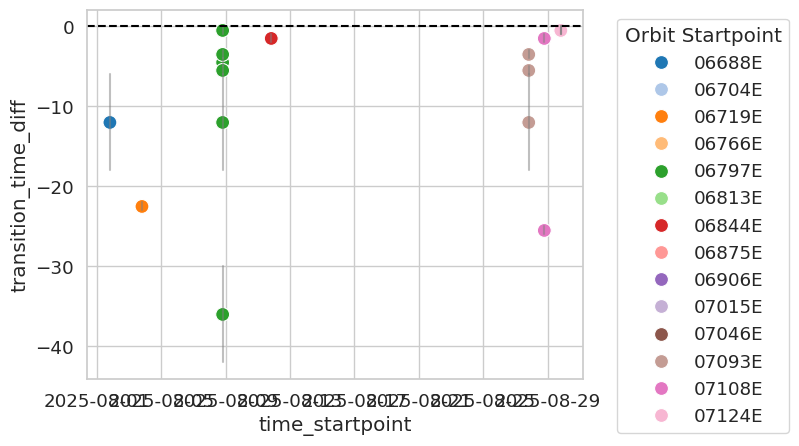

In [16]:
# Apply to your open cell trajectories
bt_oc_forward_from_o = get_transition_properties(bt_O, transition_from_msi_cats=[2], transition_to_goes_cats=[0,1], backward=False)

# Check results
print("Transition statistics:")
print(f"Trajectories with transitions: {(~pd.isna(bt_oc_forward_from_o.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_oc_forward_from_o.time_startpoint)}")

# Print statistics about transition times and uncertainties
valid_transitions = ~pd.isna(bt_oc_forward_from_o.transition_timestep.values)
transition_times = pd.to_timedelta(bt_oc_forward_from_o.transition_time_diff.values[valid_transitions])
uncertainties = pd.to_timedelta(bt_oc_forward_from_o.transition_uncertainty.values[valid_transitions])
print(f"\nTransition time statistics:")
print(f"Mean age: {transition_times.mean()}")
print(f"Median age: {transition_times.median()}")

sns.scatterplot(data = bt_oc_forward_from_o, x='time_startpoint', y='transition_time_diff', hue='orbit_startpoint', palette='tab20', legend=True, s=100)
# add whiskers for uncertainty
for i in range(len(bt_oc_forward_from_o.time_startpoint)):
    if not pd.isna(bt_oc_forward_from_o.transition_time_diff.values[i]):
        plt.plot([bt_oc_forward_from_o.time_startpoint.values[i], bt_oc_forward_from_o.time_startpoint.values[i]], 
                 [bt_oc_forward_from_o.transition_time_diff.values[i] - bt_oc_forward_from_o.transition_uncertainty.values[i],
                  bt_oc_forward_from_o.transition_time_diff.values[i] + bt_oc_forward_from_o.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit Startpoint', bbox_to_anchor=(1.05, 1), loc='upper left')

Transition statistics:
Trajectories with transitions: 103
Total trajectories: 274


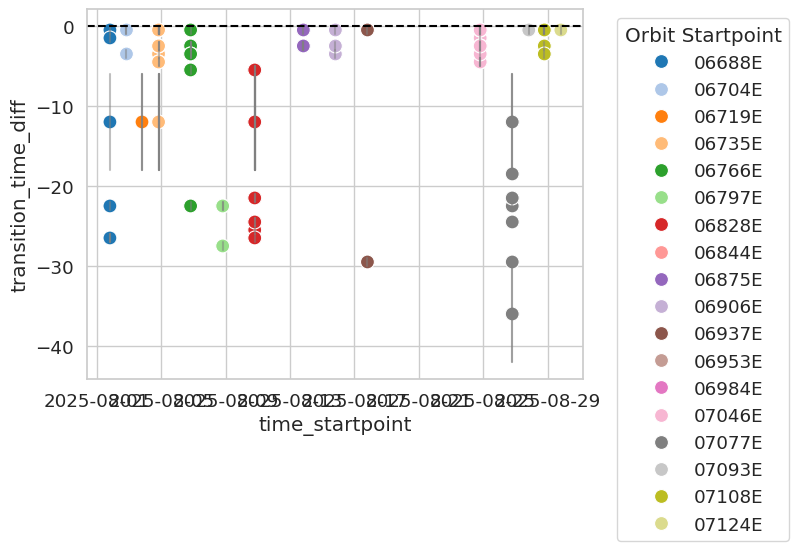

In [21]:
# manually checked which latitude ranges should contain only C-O (or C-C) transitions
co_trans_dict = {
    '06688E': [-14, -8],
    '06704E': [-12, -7.5],
    '06719E': [-17, -12.5], # should all be C-C, but rel. low optical thickness at timestep=0
    '06735E': [-22.5, -8],
    '06766E': [-22.5, -9],
    '06797E': [-19, -13],
    '06828E': [-22.5, -13],
    '06844E': [-19, -11],
    '06875E': [-18, -11.5],
    '06906E': [-16, -7],
    '06937E': [-12, -10],
    '06953E': [-12, -7],
    '06984E': [-13, -10],
    '07046E': [-22.5, -6],
    '07077E': [-16, -6],
    '07093E': [-13,-5],
    '07108E': [-22, -14],
    '07124E': [-15,-5],
}

bt_co_forward_from_c = None
for orbit, lat_range in co_trans_dict.items():
    tmp = bt_with_goes2.where(bt_with_goes2.orbit_startpoint == orbit, drop=True)
    valid_startpoints = tmp.time_startpoint[(tmp.lat_traj.sel(timestep=0) >= lat_range[0]) & (tmp.lat_traj.sel(timestep=0) <= lat_range[1])]
    tmp = tmp.where(tmp.time_startpoint.isin(valid_startpoints), drop=True)
    if bt_co_forward_from_c is None:
        bt_co_forward_from_c = tmp
    else:
        bt_co_forward_from_c = xr.concat([bt_co_forward_from_c, tmp], dim='time_startpoint')

bt_co_forward_from_c = get_transition_properties(bt_co_forward_from_c, transition_from_msi_cats=[0,1], transition_to_goes_cats=[2,3,4], backward=False)

# Check results
print("Transition statistics:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co_forward_from_c.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co_forward_from_c.time_startpoint)}")

bt_tmp = bt_co_forward_from_c
sns.scatterplot(data = bt_tmp, x='time_startpoint', y='transition_time_diff', hue='orbit_startpoint', palette='tab20', legend=True, s=100)
# add whiskers for uncertainty
for i in range(len(bt_tmp.time_startpoint)):
    if not pd.isna(bt_tmp.transition_time_diff.values[i]):
        plt.plot([bt_tmp.time_startpoint.values[i], bt_tmp.time_startpoint.values[i]], 
                 [bt_tmp.transition_time_diff.values[i] - bt_tmp.transition_uncertainty.values[i],
                  bt_tmp.transition_time_diff.values[i] + bt_tmp.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit Startpoint', bbox_to_anchor=(1.05, 1), loc='upper left')

Transition statistics:
Trajectories with transitions: 35
Total trajectories: 84
Transition statistics:
Trajectories with transitions: 16
Total trajectories: 84


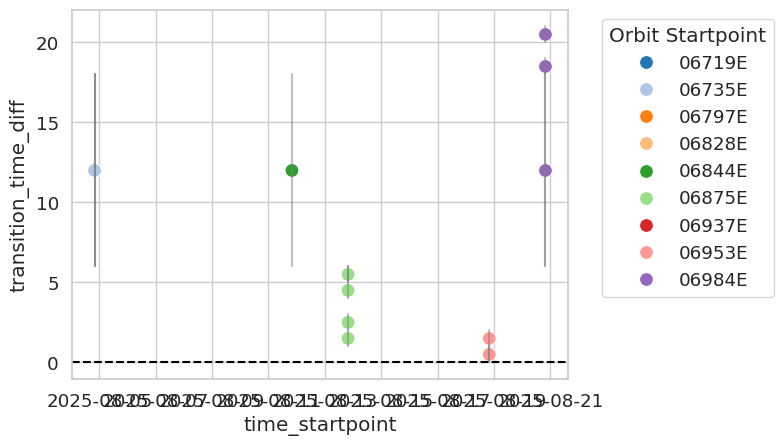

In [18]:
# manually checked which latitude ranges should contain only C-O (or C-C) transitions
#C-D
cd_trans_dict = {
'06719E': [-12.5, -10], # transition after 24h, and maybe some open cells in between during the night
'06735E': [-22.5, -7.5],
'06797E': [-11, -7],
'06828E': [-11.5, -8],
'06844E': [-9, -2.5],
'06875E': [-10, -2.5],
'06937E': [-9, -7.5],
'06953E': [-4.5, -2.5],
'06984E': [-7.5, -5],
}

bt_cd_forward_from_c = None
for orbit, lat_range in cd_trans_dict.items():
    tmp = bt_with_goes2.where(bt_with_goes2.orbit_startpoint == orbit, drop=True)
    valid_startpoints = tmp.time_startpoint[(tmp.lat_traj.sel(timestep=0) >= lat_range[0]) & (tmp.lat_traj.sel(timestep=0) <= lat_range[1])]
    tmp = tmp.where(tmp.time_startpoint.isin(valid_startpoints), drop=True)
    if bt_cd_forward_from_c is None:
        bt_cd_forward_from_c = tmp
    else:
        bt_cd_forward_from_c = xr.concat([bt_cd_forward_from_c, tmp], dim='time_startpoint')

bt_cd_forward_from_c = get_transition_properties(bt_cd_forward_from_c, transition_from_msi_cats=[0,1], transition_to_goes_cats=[3,4], backward=False)
# Check results
print("Transition statistics:")
print(f"Trajectories with transitions: {(~pd.isna(bt_cd_forward_from_c.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_cd_forward_from_c.time_startpoint)}")


cd_trans_dict_back = {
    '06704E': [-6, -2.5], # not sure if this already counts as disorganized; could also be closed MCC,
    '06735E': [-7.5, -2.5],
    '06813E': [-9, -2.5],
    '06844E': [-7.5, -2.5],
    '06953E': [-4.5, -2.5], # also in forward trajectory; directly at border between closed MCC and disorganized MCC,
    '06984E': [-7.5, -2.5] # also in forward trajectory; directly at border between closed MCC and disorganized MCC,
}

bt_cd_back_from_d = None
for orbit, lat_range in cd_trans_dict.items():
    tmp = bt_with_goes2.where(bt_with_goes2.orbit_startpoint == orbit, drop=True)
    valid_startpoints = tmp.time_startpoint[(tmp.lat_traj.sel(timestep=0) >= lat_range[0]) & (tmp.lat_traj.sel(timestep=0) <= lat_range[1])]
    tmp = tmp.where(tmp.time_startpoint.isin(valid_startpoints), drop=True)
    if bt_cd_back_from_d is None:
        bt_cd_back_from_d = tmp
    else:
        bt_cd_back_from_d = xr.concat([bt_cd_back_from_d, tmp], dim='time_startpoint')

bt_cd_back_from_d = get_transition_properties(bt_cd_back_from_d, transition_from_msi_cats=[3,4], transition_to_goes_cats=[0,1], backward=True)
# Check results
print("Transition statistics:")
print(f"Trajectories with transitions: {(~pd.isna(bt_cd_back_from_d.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_cd_back_from_d.time_startpoint)}")

bt_tmp = bt_cd_back_from_d
sns.scatterplot(data = bt_tmp, x='time_startpoint', y='transition_time_diff', hue='orbit_startpoint', palette='tab20', legend=True, s=100)
# add whiskers for uncertainty
for i in range(len(bt_tmp.time_startpoint)):
    if not pd.isna(bt_tmp.transition_time_diff.values[i]):
        plt.plot([bt_tmp.time_startpoint.values[i], bt_tmp.time_startpoint.values[i]], 
                 [bt_tmp.transition_time_diff.values[i] - bt_tmp.transition_uncertainty.values[i],
                  bt_tmp.transition_time_diff.values[i] + bt_tmp.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit Startpoint', bbox_to_anchor=(1.05, 1), loc='upper left')

In [28]:
# find the cells that do not transition
bt_cr_forward_from_c = get_transition_properties(bt_with_goes2, transition_from_msi_cats=[0,1], transition_to_goes_cats=[2,3,4,5], backward=False)

# Check results
print("Transition statistics:")
print(f"Trajectories with transitions: {(~pd.isna(bt_cr_forward_from_c.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_cr_forward_from_c.time_startpoint)}")

bt_cc_forward_from_c = bt_cr_forward_from_c.where(np.isnan(bt_cr_forward_from_c.transition_time_diff), drop=True)

Transition statistics:
Trajectories with transitions: 195
Total trajectories: 817


## add ACMCAP information

In [ ]:
acmcap_dataset_filename = '/home/jmayer/ACI_research/Code/resources/ACMCAP_XMET_judge_StCu_Jun-Aug.h5'
acmcap = pd.read_hdf(acmcap_dataset_filename, key='StCu')

In [17]:
acmcap.head()

,along_track,time,latitude,longitude,stratus_region_index,lwp,ER,ER_passive_perspective,Nd,lwp_error,...,ice_flag_0,ice_flag_1,scene_id_0,scene_id_1,MCOP_cloud_cover_judge_0,MCOP_cloud_cover_judge_1,MCOP_cwp_skew_judge_0,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1
0,2981,2025-06-01 13:26:02.599795968,-5.001905,7.111185,0,0.000051,8.760879e-07,8.760849e-07,54752600.0,0.478148,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1,2982,2025-06-01 13:26:02.736145920,-5.010733,7.109528,0,0.007185,4.358948e-06,4.684363e-06,55660160.0,0.330290,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
2,2983,2025-06-01 13:26:02.872495872,-5.019562,7.107870,0,0.000300,1.552164e-06,1.558314e-06,57090188.0,0.479258,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
3,2984,2025-06-01 13:26:03.008845952,-5.028391,7.106212,0,0.011196,4.916011e-06,5.970363e-06,62343752.0,0.341860,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
4,2985,2025-06-01 13:26:03.190764032,-5.040170,7.104001,0,0.025249,6.399618e-06,6.650821e-06,65047464.0,0.376912,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0


In [18]:
def add_acmcap_info_to_bt(bt_dataset, acmcap, transition_from_msi_cats, peek_at_acmcap_clouds = False):
    """
    For each trajectory startpoint in bt_dataset, find the corresponding ACMCAP scene(s)
    based on orbit and time, and extract rain rate and other properties if the CATS
    match the specified transition_from_msi_cats.

    Parameters:
    -----------
    bt_dataset : xarray.Dataset
        Dataset with orbit_startpoint and time_startpoint variables
    acmcap : pandas.DataFrame
        ACMCAP dataset with orbit, time, scene_id, cats, rain_rate_cbh, etc.
    transition_from_msi_cats : list
        List of MSI categories to match (default: [2])

    Returns:
    --------
    xarray.Dataset
        Dataset with added variables for rain rate and other properties
    """
    # get rain water path for ACMCAP judge scenes, matching the time_startpoints in bt_O_orbit
    rr_array = []
    std_rr_array = []
    max_rr_array = []
    rwp_array = []
    rwp_given_cloud_array = []
    std_rwp_array = []
    lwp_array = []
    cth_m_array = []
    max_cth_m_array = []
    cbh_m_array = []
    cbh_minus_lcl_array = []
    mcop_cc_array = []
    sst_array = []
    lts_array = []
    lat_min_array = []
    lat_max_array = []
    scene_id_0_array = []
    scene_id_1_array = []

    for t_ in bt_dataset.time_startpoint.values:
        print(t_)
        orbit = bt_dataset.sel(time_startpoint=t_).orbit_startpoint.values
        acmcap_orbit = acmcap[acmcap.orbit == orbit]
        acmcap_time_startpoint = acmcap_orbit[np.abs(pd.to_datetime(acmcap_orbit.time) - pd.to_datetime(t_)) < pd.Timedelta('0.1s')]
        # check
        scene_0_matches = False
        scene_1_matches = False
        scene_id_0 = np.nan
        scene_id_1 = np.nan
        if np.isin(np.unique(acmcap_time_startpoint.cats_0), transition_from_msi_cats):
            print(f'CATS_0 = {transition_from_msi_cats} match confirmed')
            scene_0_matches = True
            scene_id_0 = np.unique(acmcap_time_startpoint.scene_id_0)[0]
            rr = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].rain_rate_cbh.mean()
            if np.isnan(rr):
                rr = 0
            std_rr = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].rain_rate_cbh.std()
            max_rr = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].rain_rate_cbh.max()
            rwp = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].rwp.mean()
            rwp_given_cloud = acmcap_orbit[(acmcap_orbit.scene_id_0 == scene_id_0) & (acmcap_orbit.lwp > 0)].rwp.mean()
            std_rwp = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].rwp.std()
            lwp = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].lwp.mean()
            cth_m = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].cth_m.mean()
            max_cth_m = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].cth_m.max()
            cbh_m = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].cbh_m.mean()
            cbh_minus_lcl = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].cbh_minus_lcl.mean()
            mcop_cc = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].MCOP_cloud_cover_judge_0.mean()
            sst = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].sea_surface_temperature.mean()
            lts = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].lower_tropospheric_stability.mean()
            lat_min = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].latitude.min()
            lat_max = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0].latitude.max()

        if np.isin(np.unique(acmcap_time_startpoint.cats_1), transition_from_msi_cats):
            print(f'CATS_1 = {transition_from_msi_cats} match confirmed')
            scene_1_matches = True
            scene_id_1 = np.unique(acmcap_time_startpoint.scene_id_1)[0]
            rr1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].rain_rate_cbh.mean()
            if np.isnan(rr1):
                rr1 = 0
            std_rr1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].rain_rate_cbh.std()
            max_rr1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].rain_rate_cbh.max()
            rwp1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].rwp.mean()
            rwp_given_cloud1 = acmcap_orbit[(acmcap_orbit.scene_id_1 == scene_id_1) & (acmcap_orbit.lwp > 0)].rwp.mean()
            std_rwp1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].rwp.std()
            lwp1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].lwp.mean()
            cth_m1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].cth_m.mean()
            max_cth_m1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].cth_m.max()
            cbh_m1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].cbh_m.mean()
            cbh_minus_lcl1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].cbh_minus_lcl.mean()
            mcop_cc1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].MCOP_cloud_cover_judge_1.mean()
            sst1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].sea_surface_temperature.mean()
            lts1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].lower_tropospheric_stability.mean()
            lat_min1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].latitude.min()
            lat_max1 = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1].latitude.max()
            if scene_0_matches:
                rr = (rr + rr1) / 2
                std_rr = (std_rr + std_rr1) / 2
                max_rr = (max_rr + max_rr1) / 2
                rwp = (rwp + rwp1) / 2
                rwp_given_cloud = (rwp_given_cloud + rwp_given_cloud1) / 2
                std_rwp = (std_rwp + std_rwp1) / 2
                lwp = (lwp + lwp1) / 2
                cth_m = (cth_m + cth_m1) / 2
                max_cth_m = (max_cth_m + max_cth_m1) / 2
                cbh_m = (cbh_m + cbh_m1) / 2
                cbh_minus_lcl = (cbh_minus_lcl + cbh_minus_lcl1) / 2
                mcop_cc = (mcop_cc + mcop_cc1) / 2
                sst = (sst + sst1) / 2
                lts = (lts + lts1) / 2
                lat_min = (lat_min + lat_min1) / 2
                lat_max = (lat_max + lat_max1) / 2
            else:
                rr = rr1
                std_rr = std_rr1
                max_rr = max_rr1
                rwp = rwp1
                rwp_given_cloud = rwp_given_cloud1
                std_rwp = std_rwp1
                lwp = lwp1
                cth_m = cth_m1
                max_cth_m = max_cth_m1
                cbh_m = cbh_m1
                cbh_minus_lcl = cbh_minus_lcl1
                mcop_cc = mcop_cc1
                sst = sst1
                lts = lts1
                lat_min = lat_min1
                lat_max = lat_max1
        if not scene_0_matches and not scene_1_matches:
            print(f'No CATS = {transition_from_msi_cats} match found')
            rr = np.nan
            std_rr = np.nan
            max_rr = np.nan
            rwp = np.nan
            rwp_given_cloud = np.nan
            std_rwp = np.nan
            lwp = np.nan
            cth_m = np.nan
            max_cth_m = np.nan
            cbh_m = np.nan
            cbh_minus_lcl = np.nan
            mcop_cc = np.nan
            sst = np.nan
            lts = np.nan
            lat_min = np.nan
            lat_max = np.nan
            
        rr_array.append(rr)
        std_rr_array.append(std_rr)
        max_rr_array.append(max_rr)
        rwp_array.append(rwp)
        rwp_given_cloud_array.append(rwp_given_cloud)
        std_rwp_array.append(std_rwp)
        lwp_array.append(lwp)
        cth_m_array.append(cth_m)
        max_cth_m_array.append(max_cth_m)
        cbh_m_array.append(cbh_m)
        cbh_minus_lcl_array.append(cbh_minus_lcl)
        mcop_cc_array.append(mcop_cc)
        sst_array.append(sst)
        lts_array.append(lts)
        lat_min_array.append(lat_min)
        lat_max_array.append(lat_max)
        scene_id_0_array.append(scene_id_0)
        scene_id_1_array.append(scene_id_1)

        if peek_at_acmcap_clouds:
            time_to_trans = bt_dataset.sel(time_startpoint=t_).transition_time_diff.values
            if pd.isna(time_to_trans):
                continue

            if scene_0_matches and scene_1_matches:
                acmcap_orbit_0 = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0]
                tmp_latmax, tmp_latmin = acmcap_orbit_0.latitude.max(), acmcap_orbit_0.latitude.min()
                acmcap_orbit_1 = acmcap_orbit[(acmcap_orbit.scene_id_1 == scene_id_1) & ((acmcap_orbit.latitude > tmp_latmax) | (acmcap_orbit.latitude < tmp_latmin))]  # remove overlapping latitudes
                tmp_scene = pd.concat([acmcap_orbit_0, acmcap_orbit_1])
                tmp_scene = tmp_scene.sort_values(by='latitude')
                scene_id = f'{scene_id_0} & {scene_id_1}'
            elif scene_0_matches:
                tmp_scene = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0]
                scene_id = f'{scene_id_0}'
            elif scene_1_matches:
                tmp_scene = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1]
                scene_id = f'{scene_id_1}'
            else:
                continue  # Skip plotting if no matches

            def add_profile(profile_arr, cbh_m, cth_m):
                # between dfex.cbh_m and dfex.cth_m (both arrays of size 113), the profile_arr should be filled with 1
                for i in range(len(cth_m)):
                    cbh = cbh_m.values[i]
                    cth = cth_m.values[i]
                    if np.isnan(cbh) or np.isnan(cth):
                        continue
                    cbh_idx = int(cbh // 100)
                    cth_idx = int(cth // 100)
                    # Ensure indices are within bounds
                    cbh_idx = max(0, min(cbh_idx, profile_arr.shape[1] - 1))
                    cth_idx = max(0, min(cth_idx, profile_arr.shape[1] - 1))
                    profile_arr[i, cbh_idx:cth_idx+1] += 1
                return profile_arr
            
            x_length = len(tmp_scene.latitude)
            profile_arr = xr.DataArray(np.zeros((x_length, 25)), dims=['latitude', 'height'], coords={'latitude': tmp_scene.latitude.values, 'height': np.arange(25)*100})
            profile_arr = add_profile(profile_arr, tmp_scene.cbh_m, tmp_scene.cth_m)
            sns.set_style('white')
            sns.set_context('talk', font_scale=0.8)
            fig, axs = plt.subplots(2, 1, figsize=(x_length/100*5, 4))
            ax=axs[0]
            im1 = ax.imshow(profile_arr.T, origin='lower', aspect='auto', extent=[0,x_length,0,2500], cmap='Blues_r')
            im2 = ax.imshow((profile_arr * tmp_scene.rain_rate_cbh.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2500], cmap='chiljet2', norm=LogNorm(1e-7, 1e-4))
            plt.colorbar(im2, ax=ax, label='RR / kg m$^{-2}$ s$^{-1}$')
            ax.set_xticks(ticks=np.linspace(0, x_length, 3), labels=[f'{lat:.2f}' for lat in np.linspace(tmp_scene.latitude.values[0], tmp_scene.latitude.values[-1], 3)])
            ax.set_title(f'{orbit}, $\Delta$t={time_to_trans}, Scene ID {scene_id}')
            ax = axs[1]
            im3 = ax.imshow(profile_arr.T, origin='lower', aspect='auto', extent=[0,x_length,0,2500], cmap='Blues_r')
            im4 = ax.imshow((profile_arr * tmp_scene.lwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2500], cmap='chiljet2', norm=LogNorm(1e-4, 1e0))
            plt.colorbar(im4, ax=ax, label='LWP / kg m$^{-2}$')
            ax.set_xticks(ticks=np.linspace(0, x_length, 3), labels=[f'{lat:.2f}' for lat in np.linspace(tmp_scene.latitude.min(), tmp_scene.latitude.max(), 3)])
            fig.tight_layout()
            plt.show()

            #plt.figure(figsize=(9, 2.5))
            #ax = plt.gca()
            ## Use pandas plotting instead of seaborn to avoid coordinate issues
            #ax.plot(tmp_scene.latitude, tmp_scene.cth_m, color='blue')
            #ax.plot(tmp_scene.latitude, tmp_scene.cbh_m, color='blue')
            #ax2 = ax.twinx()
            #ax2.plot(tmp_scene.latitude, tmp_scene.rain_rate_cbh, color='red')
            #ax.set_xlabel('Latitude')
            #ax.set_ylabel('Height (m)')
            #ax.set_ylim(0, 1500)
            #plt.title(f'Orbit {orbit}, time to trans. {time_to_trans} Scene ID {scene_id}')
            #plt.show()

    bt_dataset['rain_rate_cbh'] = xr.DataArray(rr_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['std_rain_rate_cbh'] = xr.DataArray(std_rr_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['max_rain_rate_cbh'] = xr.DataArray(max_rr_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['rwp'] = xr.DataArray(rwp_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['rwp_given_cloud'] = xr.DataArray(rwp_given_cloud_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['std_rwp'] = xr.DataArray(std_rwp_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['lwp'] = xr.DataArray(lwp_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['cth_m'] = xr.DataArray(cth_m_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['max_cth_m'] = xr.DataArray(max_cth_m_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['cbh_m'] = xr.DataArray(cbh_m_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['H'] = bt_dataset.cth_m - bt_dataset.cbh_m
    bt_dataset['cbh_minus_lcl'] = xr.DataArray(cbh_minus_lcl_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['mcop_cc'] = xr.DataArray(mcop_cc_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['sst'] = xr.DataArray(sst_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['lts'] = xr.DataArray(lts_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['lat_min_acmcap'] = xr.DataArray(lat_min_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['lat_max_acmcap'] = xr.DataArray(lat_max_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['scene_id_0'] = xr.DataArray(scene_id_0_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['scene_id_1'] = xr.DataArray(scene_id_1_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})

    return bt_dataset

<>:215: SyntaxWarning: invalid escape sequence '\D'
<>:215: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_3885943/3274169015.py:215: SyntaxWarning: invalid escape sequence '\D'
  ax.set_title(f'{orbit}, $\Delta$t={time_to_trans}, Scene ID {scene_id}')


### CO transitions

In [22]:
bt_co_forward_from_c = add_acmcap_info_to_bt(bt_co_forward_from_c, acmcap, transition_from_msi_cats=[0,1])

bt_co_back_from_o = add_acmcap_info_to_bt(bt_co_back_from_o, acmcap, transition_from_msi_cats=[2])

2025-08-01T19:21:33.642530048
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:41.706593024
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:49.770657024
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:57.834720448
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:05.898784000
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:13.962847936
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:22.026914496
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:30.090981056
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:38.155044992
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:46.219108544
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:54.283171968
CATS_0 = [0, 1] match confirme

#### ACMCAP profiles of CO transitioning clouds

2025-08-01T19:22:30.090981056
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:38.155044992
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:46.219108544
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:54.283171968
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-02T20:02:56.510521024
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-02T20:03:04.574584064
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-02T20:03:12.638648000
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-03T19:11:29.252185024
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-03T19:11:37.316248000
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-03T19:11:45.380312064
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-03T19:11:53.444374912
CATS_0 = [0, 1] match confirme

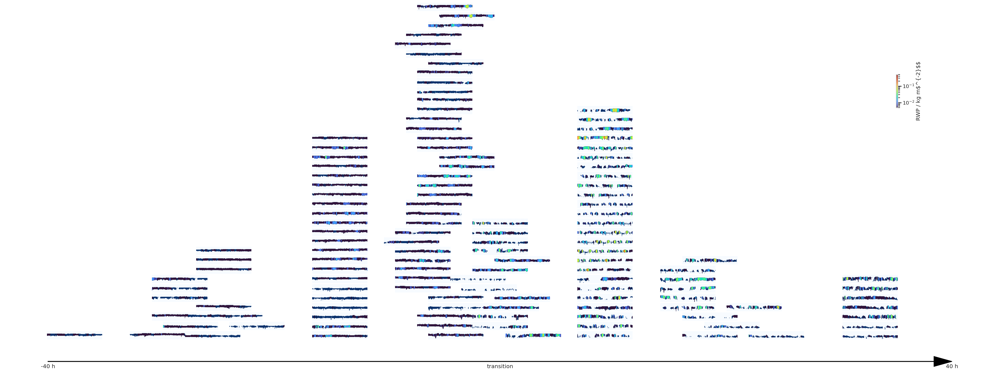

In [ ]:
# create a big figure with many small subplots (like peek_at_acmcap) to compare the different trajectory sets
# the subplots are at x-positions determined by the transition_time_diff values, and y-positions determined s.t. plots dont overlap
hue_variable = 'rwp'  # can be 'rain_rate_cbh', 'lwp'

fig = plt.figure(figsize=(40, 20))
# Track occupied positions to avoid overlaps
occupied_positions = []  # List of (left, right, bottom, top) rectangles
subplot_width = 0.05
subplot_height = 0.015

#transition_times = bt_dataset.transition_time_diff.values
#valid_times = transition_times[~np.isnan(transition_times)]
#time_min, time_max = valid_times.min(), valid_times.max()
time_min, time_max = -40, 40

sns.set_context('talk', font_scale=0.8)

for bt_dataset, transition_from_msi_cats in [
    (bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True), [0, 1]),
    (bt_co_back_from_o.where(~np.isnan(bt_co_back_from_o.transition_time_diff), drop=True), [2])
    ]:


    for i, t_ in enumerate(bt_dataset.time_startpoint.values):
        print(t_)
        orbit = bt_dataset.sel(time_startpoint=t_).orbit_startpoint.values
        acmcap_orbit = acmcap[acmcap.orbit == orbit]
        acmcap_time_startpoint = acmcap_orbit[np.abs(pd.to_datetime(acmcap_orbit.time) - pd.to_datetime(t_)) < pd.Timedelta('0.1s')]
        # check
        scene_0_matches = False
        scene_1_matches = False
        if np.isin(np.unique(acmcap_time_startpoint.cats_0), transition_from_msi_cats):
            print(f'CATS_0 = {transition_from_msi_cats} match confirmed')
            scene_0_matches = True
            scene_id_0 = np.unique(acmcap_time_startpoint.scene_id_0)
        if np.isin(np.unique(acmcap_time_startpoint.cats_1), transition_from_msi_cats):
            print(f'CATS_1 = {transition_from_msi_cats} match confirmed')
            scene_1_matches = True
            scene_id_1 = np.unique(acmcap_time_startpoint.scene_id_1)

        time_to_trans = bt_dataset.sel(time_startpoint=t_).transition_time_diff.values
        if pd.isna(time_to_trans):
            continue

        if scene_0_matches and scene_1_matches:
            acmcap_orbit_0 = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0[0]]
            tmp_latmax, tmp_latmin = acmcap_orbit_0.latitude.max(), acmcap_orbit_0.latitude.min()
            acmcap_orbit_1 = acmcap_orbit[(acmcap_orbit.scene_id_1 == scene_id_1[0]) & ((acmcap_orbit.latitude > tmp_latmax) | (acmcap_orbit.latitude < tmp_latmin))]  # remove overlapping latitudes
            tmp_scene = pd.concat([acmcap_orbit_0, acmcap_orbit_1])
            tmp_scene = tmp_scene.sort_values(by='latitude')
            scene_id = f'{scene_id_0[0]} & {scene_id_1[0]}'
        elif scene_0_matches:
            tmp_scene = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0[0]]
            scene_id = f'{scene_id_0[0]}'
        elif scene_1_matches:
            tmp_scene = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1[0]]
            scene_id = f'{scene_id_1[0]}'
        else:
            continue  # Skip plotting if no matches

        def add_profile(profile_arr, cbh_m, cth_m):
            # between dfex.cbh_m and dfex.cth_m (both arrays of size 113), the profile_arr should be filled with 1
            for i in range(len(cth_m)):
                cbh = cbh_m.values[i]
                cth = cth_m.values[i]
                if np.isnan(cbh) or np.isnan(cth):
                    continue
                cbh_idx = int(cbh // 100)
                cth_idx = int(cth // 100)
                # Ensure indices are within bounds
                cbh_idx = max(0, min(cbh_idx, profile_arr.shape[1] - 1))
                cth_idx = max(0, min(cth_idx, profile_arr.shape[1] - 1))
                profile_arr[i, cbh_idx:cth_idx+1] += 1
            return profile_arr
        
        x_length = len(tmp_scene.latitude)
        profile_arr = xr.DataArray(np.zeros((x_length, 20)), dims=['latitude', 'height'], coords={'latitude': tmp_scene.latitude.values, 'height': np.arange(20)*100})
        profile_arr = add_profile(profile_arr, tmp_scene.cbh_m, tmp_scene.cth_m)


        # add axes to the big figure at the correct position
        # Calculate normalized position
        #norm_x = (time_to_trans - time_min) / (time_max - time_min)
        ## Position the subplot
        #left = 0.1 + norm_x * 0.8  # Use 80% of figure width
        #bottom = 0.1 + (i % 5) * 0.15  # Stack multiple rows if needed
        #width = 0.15
        #height = 0.05
        #ax = fig.add_axes([left, bottom, width, height])
        
        # Calculate normalized x position
        norm_x = (time_to_trans - time_min) / (time_max - time_min)
        left = 0.1 + norm_x * 0.8  # Use 80% of figure width
        right = left + subplot_width
        
        # Find available vertical position
        bottom = 0.1  # Start from bottom
        found_position = False
        
        while not found_position:
            top = bottom + subplot_height
            
            # Check if this position overlaps with any existing subplot
            overlaps = False
            for occupied in occupied_positions:
                occ_left, occ_right, occ_bottom, occ_top = occupied
                
                # Check for overlap
                if (left < occ_right and right > occ_left and 
                    bottom < occ_top and top > occ_bottom):
                    overlaps = True
                    break
            
            if not overlaps:
                found_position = True
            else:
                bottom += subplot_height + 0.002  # Move up with small gap
        
        # Record this position as occupied
        occupied_positions.append((left, right, bottom, top))
        
        # Create the subplot
        ax = fig.add_axes([left, bottom, subplot_width, subplot_height])
        
        im1 = ax.imshow(profile_arr.T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='Blues')
        if hue_variable == 'rwp':
            im2 = ax.imshow((profile_arr * tmp_scene.rwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='turbo', norm=LogNorm(5e-3, 5e-1))
            #plt.colorbar(im2, ax=ax, label='RR / kg m$^{-2}$ s$^{-1}$')
        elif hue_variable == 'lwp':
            im2 = ax.imshow((profile_arr * tmp_scene.lwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='viridis', norm=LogNorm(1e-4, 5e-1))
            #plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
        #ax.set_xticks(ticks=np.linspace(0, x_length, 3), labels=[f'{lat:.2f}' for lat in np.linspace(tmp_scene.latitude.values[0], tmp_scene.latitude.values[-1], 3)])
        #ax.set_title(f'{orbit}, $\Delta$t={time_to_trans}, Scene ID {scene_id}')
        ax.set_axis_off()  # Turn off axis for small plots

#max_y_position = np.max([occupied_positions[i][1] for i in range(len(occupied_positions))])
ax = fig.add_axes([0.9, 0.5, 0.01, 0.1])  # Position for colorbar
if hue_variable == 'rwp':
    plt.colorbar(im2, ax=ax, label='RWP / kg m$^{-2}$')
elif hue_variable == 'lwp':
    plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
ax.set_axis_off()

# plot one big time arrow at the bottom to indicate time axis
ax = fig.add_axes([0.1, 0.05, 0.9, 0.02])  # Position for time axis
ax.arrow(0, 0.5, 1, 0, head_width=0.03, head_length=0.02, length_includes_head=True, fc='black', ec='black')
ax.text(0, 0.48, f'{time_min} h', ha='center')
ax.text(1, 0.48, f'{time_max} h', ha='center')
ax.text(0.5, 0.48, f'transition', ha='center')
ax.set_axis_off()

In [ ]:
# look at example profiles
tmp = bt_co_forward_from_c.isel(time_startpoint=slice(0,20))
tmp = bt_co_back_from_o.where(~np.isnan(bt_co_back_from_o.transition_time_diff), drop=True)#.isel(time_startpoint=slice(0,5))
tmp = bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True).isel(time_startpoint=slice(0,20))
add_acmcap_info_to_bt(tmp, acmcap, transition_from_msi_cats=[0,1], peek_at_acmcap_clouds=True)

#### ACMCAP variables as function of time-to-transition

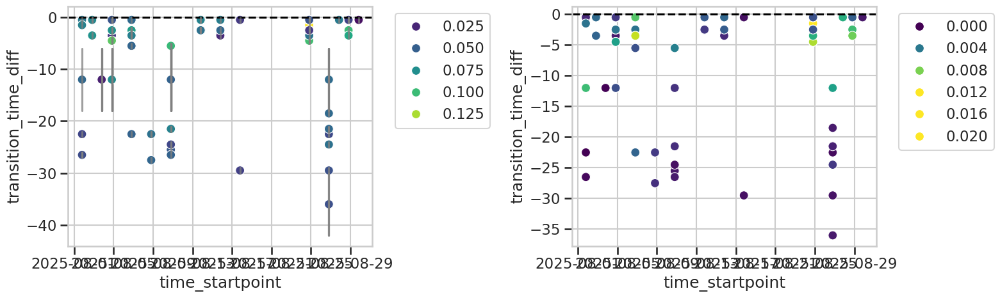

In [101]:
bt_tmp = bt_co_forward_from_c
fig, axs = plt.subplots(1,2, figsize=(16,5))
sns.scatterplot(ax=axs[0], data = bt_tmp, x='time_startpoint', y='transition_time_diff', hue='lwp', palette='viridis', legend=True, s=100)
sns.scatterplot(ax=axs[1], data = bt_tmp, x='time_startpoint', y='transition_time_diff', hue='rwp', palette='viridis', hue_norm=(1e-6,1e-2), legend=True, s=100)

# add whiskers for uncertainty
for ax in axs:
    for i in range(len(bt_tmp.time_startpoint)):
        if not pd.isna(bt_tmp.transition_time_diff.values[i]):
            axs[0].plot([bt_tmp.time_startpoint.values[i], bt_tmp.time_startpoint.values[i]], 
                    [bt_tmp.transition_time_diff.values[i] - bt_tmp.transition_uncertainty.values[i],
                    bt_tmp.transition_time_diff.values[i] + bt_tmp.transition_uncertainty.values[i]], 
                    color='gray', alpha=0.5)
    ax.axhline(0, color='black', linestyle='--')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
fig.tight_layout()

(-42.0, 42.0)

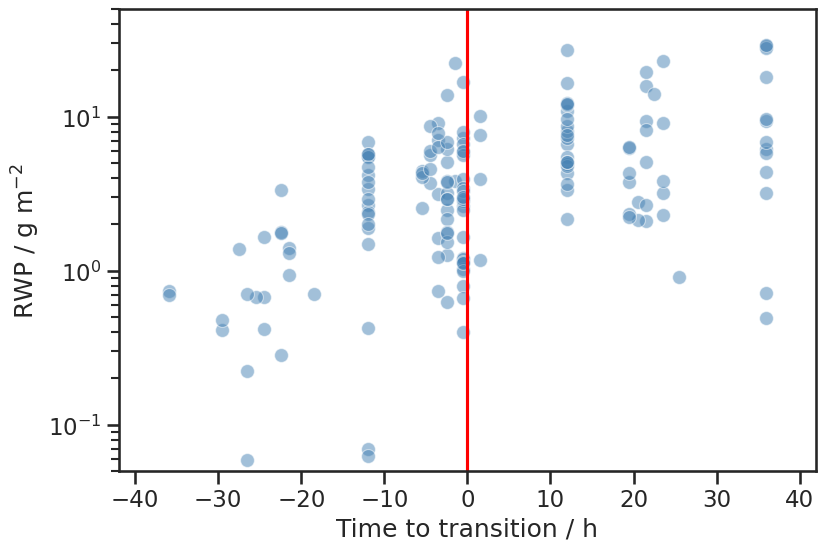

In [31]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

plt.figure(figsize=(9, 6))
sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y=bt_co_forward_from_c['rwp_given_cloud']*1e3, color='steelblue', alpha=0.5, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y=bt_co_back_from_o['rwp_given_cloud']*1e3, color='steelblue', alpha=0.5, s=100)
plt.yscale('log')
plt.ylim(5e-2, 5e1)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')
#median_non_transitioning_clouds = bt_co_forward_from_c.rwp.where(np.isnan(bt_co_forward_from_c.transition_time_diff)).median().values
#plt.axhline(median_non_transitioning_clouds, color='black', linestyle=':', label='Median RWP non-transitioning clouds')
#mean_rwp_closed_cells = acmcap[(acmcap.cats_0 == 1) & (acmcap.cats_1 == 1)].rwp.mean()
#plt.axhline(mean_rwp_closed_cells, color='black', linestyle=':', label='Mean RWP closed-cell clouds (CATS=1)')

# add uncertainty bars for the time to transition
#for bt_tmp in [bt_co_forward_from_c, bt_co_back_from_o]:
#    for i in range(len(bt_tmp.time_startpoint)):
#        if not pd.isna(bt_tmp.transition_time_diff.values[i]):
#            plt.plot( 
#                    [bt_tmp.transition_time_diff.values[i] - bt_tmp.transition_uncertainty.values[i],
#                    bt_tmp.transition_time_diff.values[i] + bt_tmp.transition_uncertainty.values[i]], 
#                    [bt_tmp.rwp_given_cloud.values[i]*1e3, bt_tmp.rwp_given_cloud.values[i]*1e3],
#                    color='gray', alpha=0.3)
plt.xlim(-42, 42)

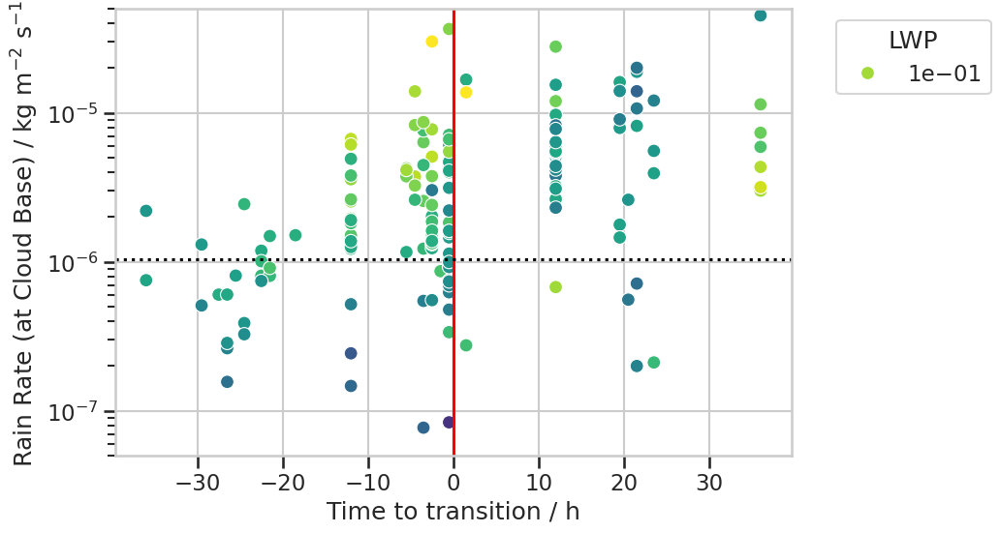

In [104]:
sns.set_context('talk', font_scale=1.)
sns.set_style('whitegrid')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

plt.figure(figsize=(9, 6))
sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
plt.yscale('log')
plt.ylim(5e-8, 5e-5)
plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left', )
plt.xlabel('Time to transition / h')
plt.ylabel('Rain Rate (at Cloud Base) / kg m$^{-2}$ s$^{-1}$')
plt.axvline(0, color='red', linestyle='-')

# add uncertainty bars for the time to transition
#for bt_tmp in [bt_co_forward_from_c, bt_co_back_from_o]:
#    for i in range(len(bt_tmp.time_startpoint)):
#        if not pd.isna(bt_tmp.transition_time_diff.values[i]):
#            plt.plot( 
#                    [bt_tmp.transition_time_diff.values[i] - bt_tmp.transition_uncertainty.values[i],
#                    bt_tmp.transition_time_diff.values[i] + bt_tmp.transition_uncertainty.values[i]], 
#                    [bt_tmp.rain_rate_cbh.values[i], bt_tmp.rain_rate_cbh.values[i]],
#                    color='gray', alpha=0.3)

median_non_transitioning_clouds = bt_co_forward_from_c.rain_rate_cbh.where(np.isnan(bt_co_forward_from_c.transition_time_diff) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1]))).median().values
plt.axhline(median_non_transitioning_clouds, color='black', linestyle=':', label='Median RR non-transitioning clouds')

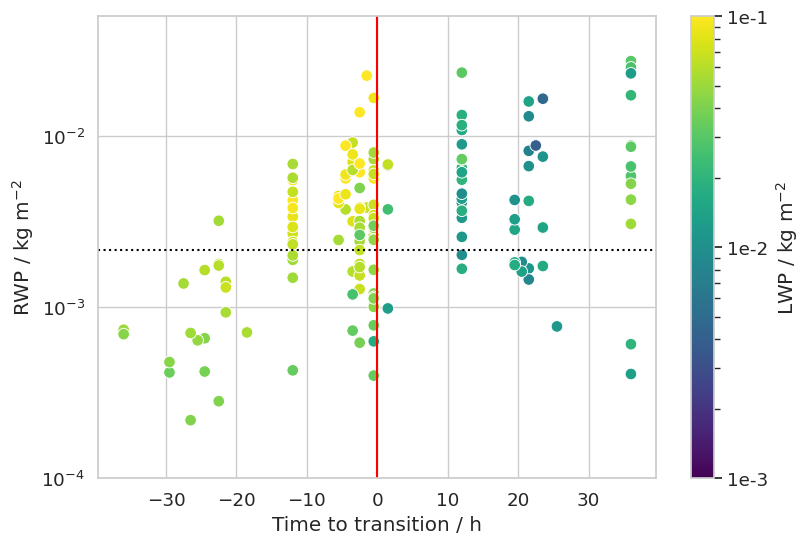

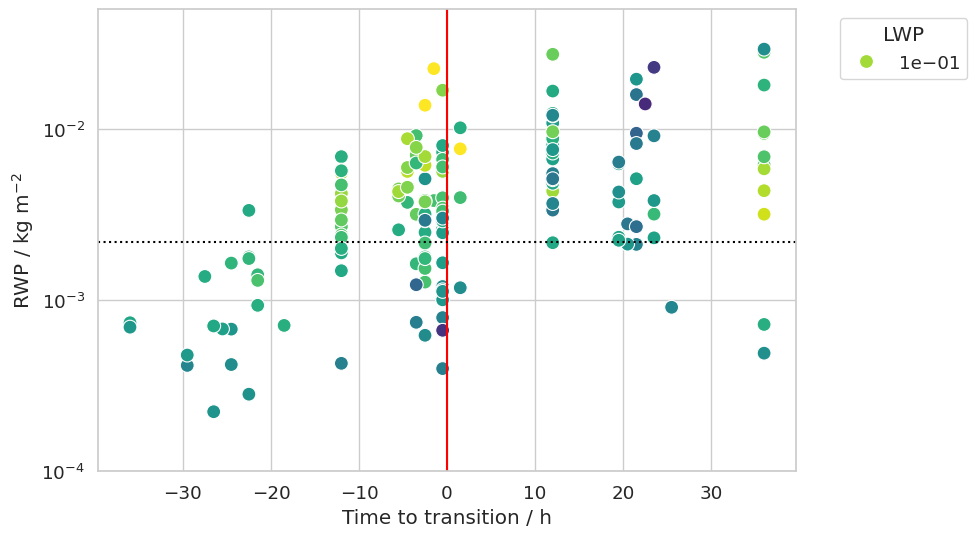

In [24]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='rwp', hue='lwp', hue_norm=LogNorm(vmin=1e-3, vmax=1e-1), palette='viridis', legend=False, s=70)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='rwp', hue='lwp', hue_norm=LogNorm(vmin=1e-3, vmax=1e-1), palette='viridis', legend=False, s=70)
plt.yscale('log')
plt.ylim(1e-4, 5e-2)
# Force colorbar with specific ticks
sm = plt.cm.ScalarMappable(cmap='viridis', norm=LogNorm(vmin=1e-3, vmax=1e-1))
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label('LWP / kg m$^{-2}$')
cbar.set_ticks([1e-3, 1e-2, 1e-1])
cbar.set_ticklabels(['1e-3', '1e-2', '1e-1'])

plt.xlabel('Time to transition / h')
plt.ylabel('RWP / kg m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')

median_non_transitioning_clouds = bt_co_forward_from_c.rwp.where(np.isnan(bt_co_forward_from_c.transition_time_diff) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1]))).median().values
plt.axhline(median_non_transitioning_clouds, color='black', linestyle=':', label='Median RWP non-transitioning clouds')

# --------------------------------------------
plt.figure(figsize=(9, 6))
sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='rwp_given_cloud', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='rwp_given_cloud', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
plt.yscale('log')
plt.ylim(1e-4, 5e-2)
plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left', )
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / kg m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')
median_non_transitioning_clouds = bt_co_forward_from_c.rwp_given_cloud.where(np.isnan(bt_co_forward_from_c.transition_time_diff) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1]))).median().values
plt.axhline(median_non_transitioning_clouds, color='black', linestyle=':', label='Median RWP non-transitioning clouds')


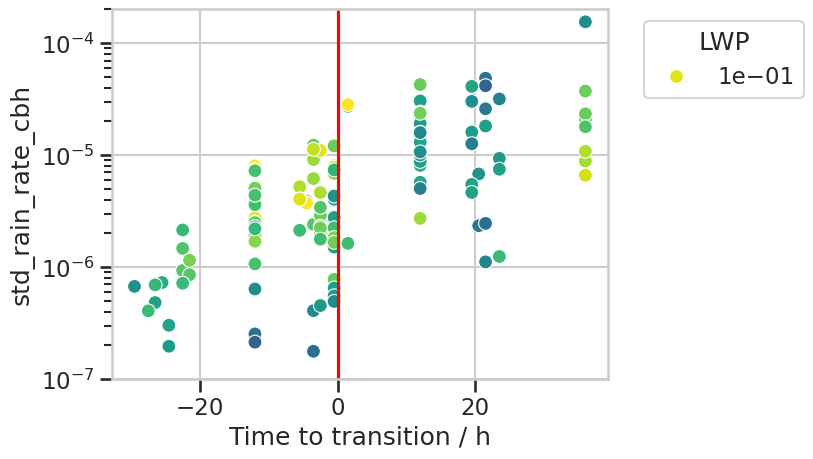

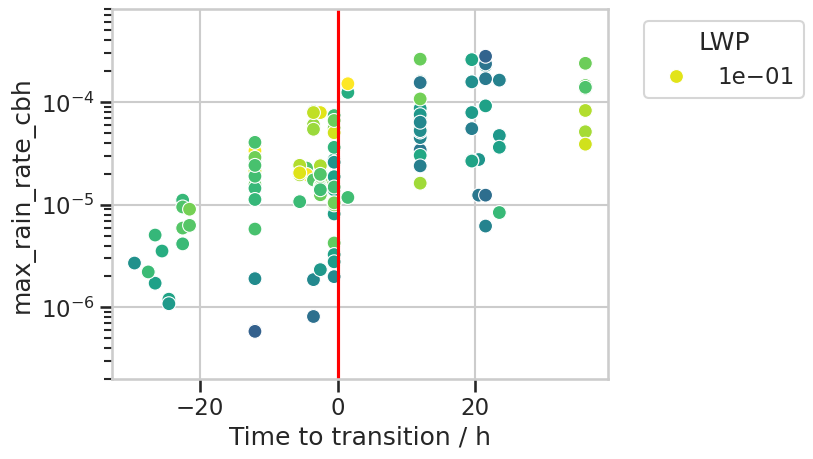

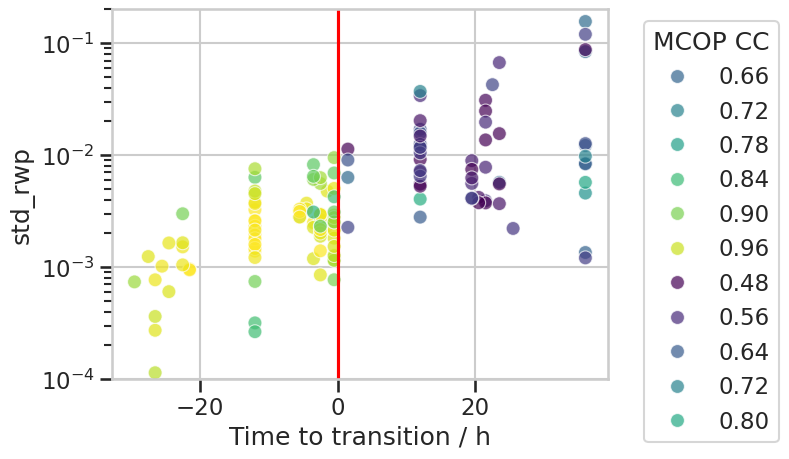

In [62]:
sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='std_rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='std_rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
plt.yscale('log')
plt.ylim(1e-7, 2e-4)
plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='max_rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='max_rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
plt.yscale('log')
plt.ylim(2e-7, 8e-4)
plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='std_rwp', hue='mcop_cc', hue_norm=(0.5, 1), palette='viridis', alpha=0.7, legend=True, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='std_rwp', hue='mcop_cc', hue_norm=(0.5, 1), palette='viridis', alpha=0.7,legend=True, s=100)
plt.yscale('log')
plt.ylim(1e-4, 2e-1)
plt.legend(title='MCOP CC', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

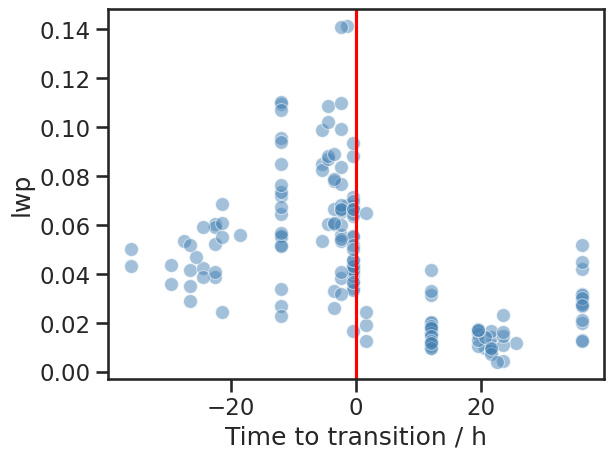

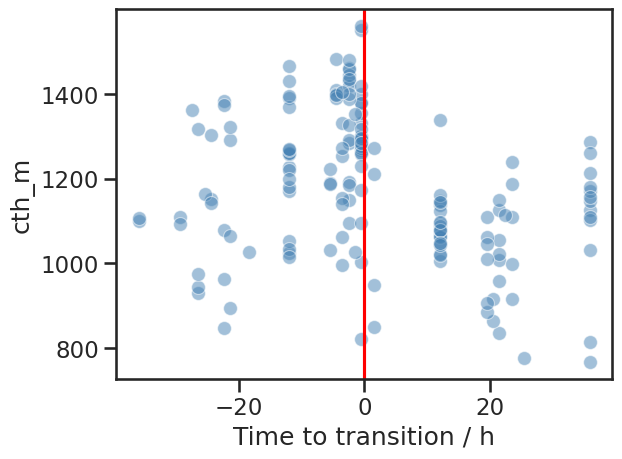

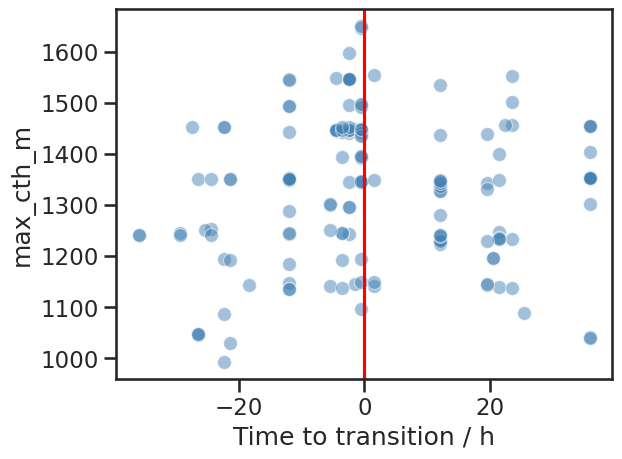

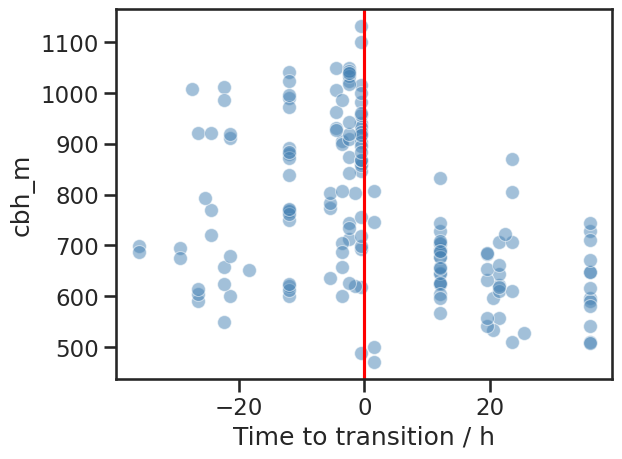

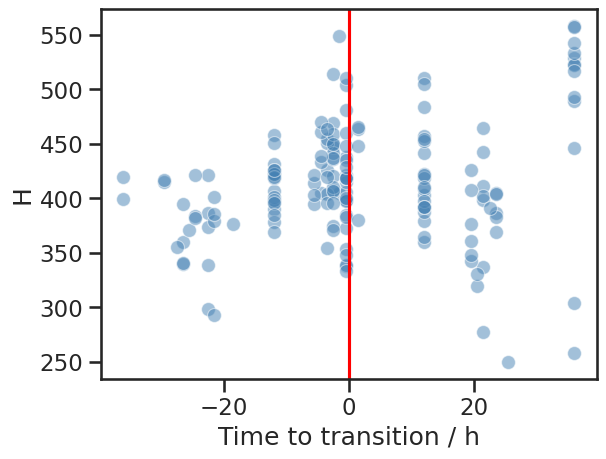

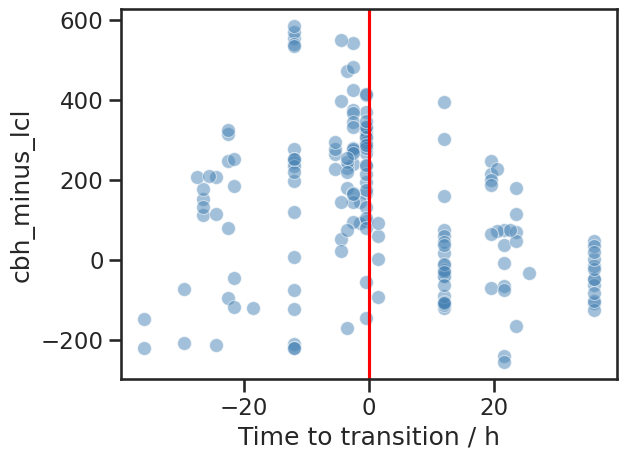

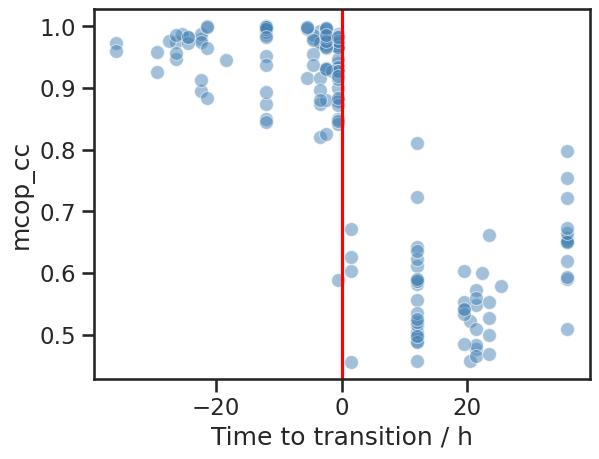

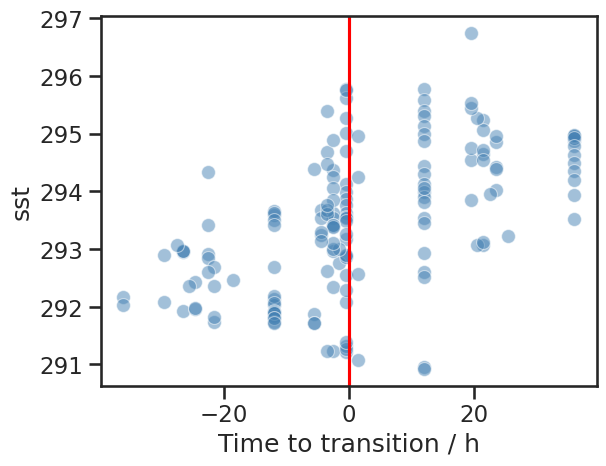

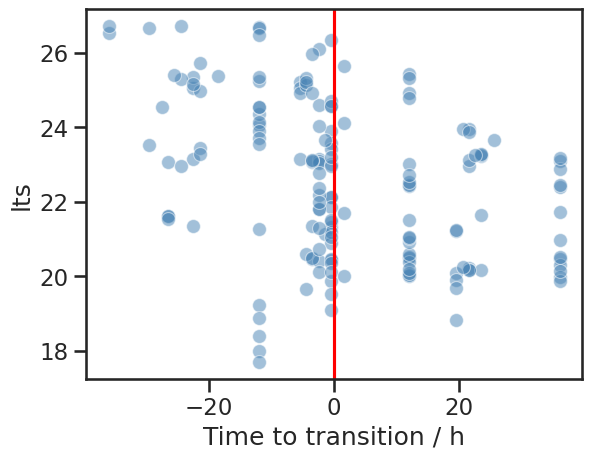

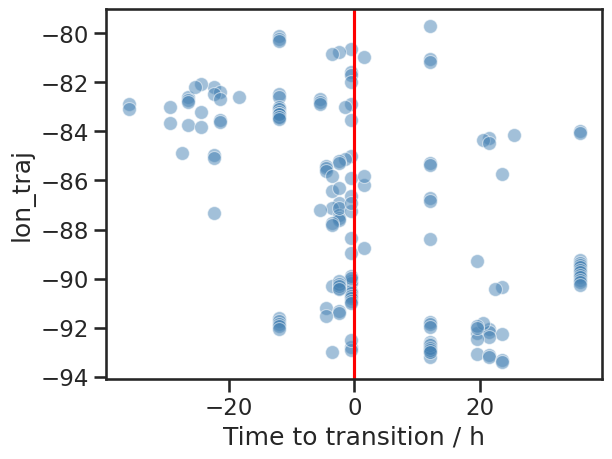

In [35]:
for var in ['lwp', 'cth_m', 'max_cth_m', 'cbh_m', 'H', 'cbh_minus_lcl', 'mcop_cc', 'sst', 'lts', 'lon_traj']:
    #sns.scatterplot(data = bt_co_forward_from_c.sel(timestep = 0), x='transition_time_diff', y=var, hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
    #sns.scatterplot(data = bt_co_back_from_o.sel(timestep = 0), x='transition_time_diff', y=var, hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
    #plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')

    sns.scatterplot(data = bt_co_forward_from_c.sel(timestep = 0), x='transition_time_diff', y=var, legend=False, color='steelblue', alpha=0.5, s=100)
    sns.scatterplot(data = bt_co_back_from_o.sel(timestep = 0), x='transition_time_diff', y=var, legend=False, color='steelblue', alpha=0.5, s=100)
    plt.axvline(0, color='red', linestyle='-')
    plt.xlabel('Time to transition / h')
    plt.show()

In [45]:
bt_co_concat = xr.concat([bt_co_forward_from_c.sel(timestep = 0), bt_co_back_from_o.sel(timestep = 0)], dim='time_startpoint')

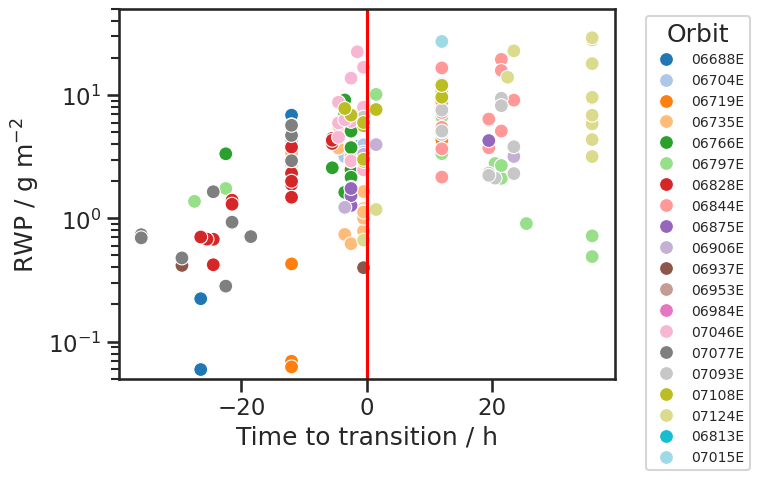

In [49]:
sns.scatterplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp_given_cloud']*1e3, hue='orbit_startpoint', palette='tab20', legend=True, s=100)
plt.yscale('log')
plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.ylim(5e-2, 5e1)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')

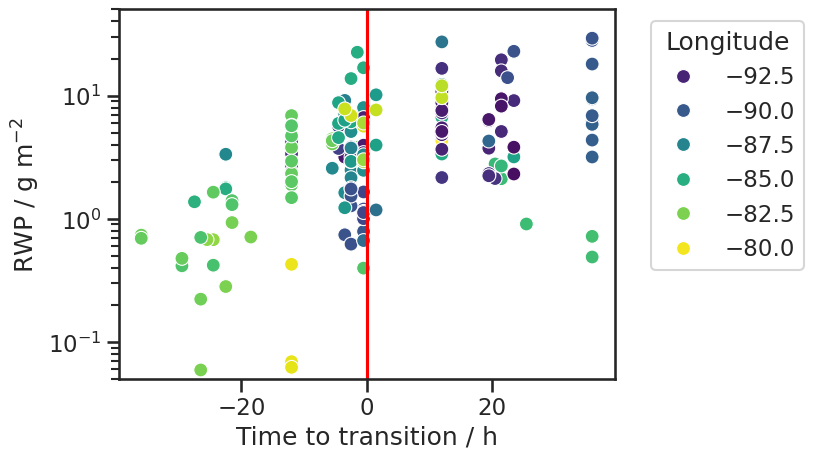

In [53]:
from matplotlib.colors import LogNorm
sns.scatterplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp_given_cloud']*1e3, hue='lon_traj', palette='viridis', legend=True, s=100)
plt.yscale('log')
plt.legend(title='Longitude', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylim(5e-2, 5e1)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')

/tmp/ipykernel_1879336/1193837884.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


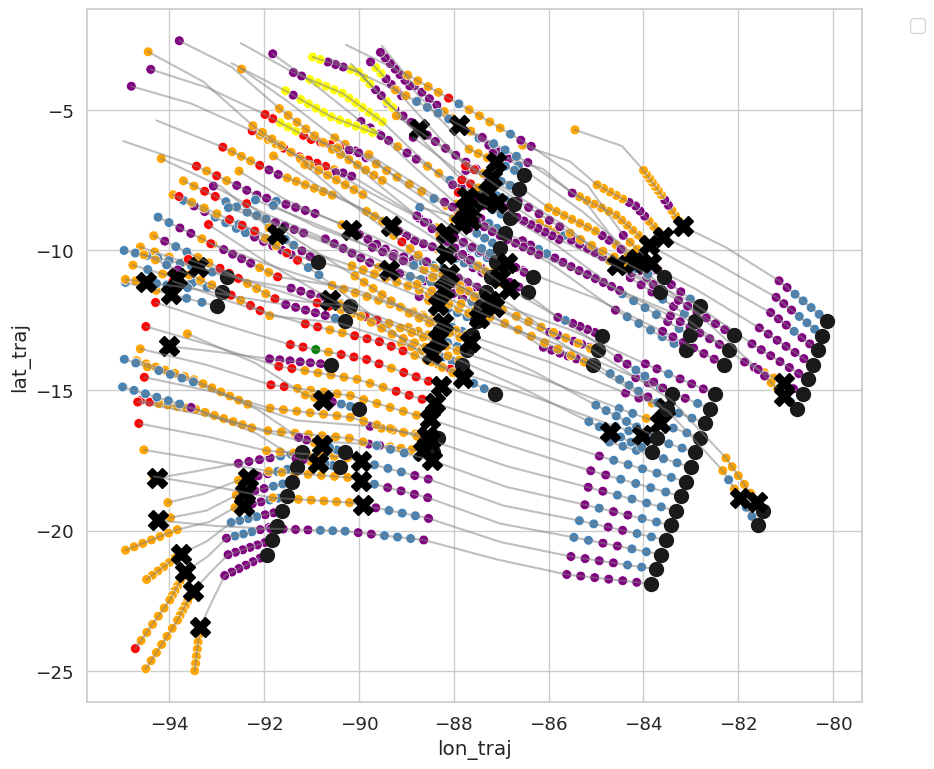

/tmp/ipykernel_1879336/1193837884.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


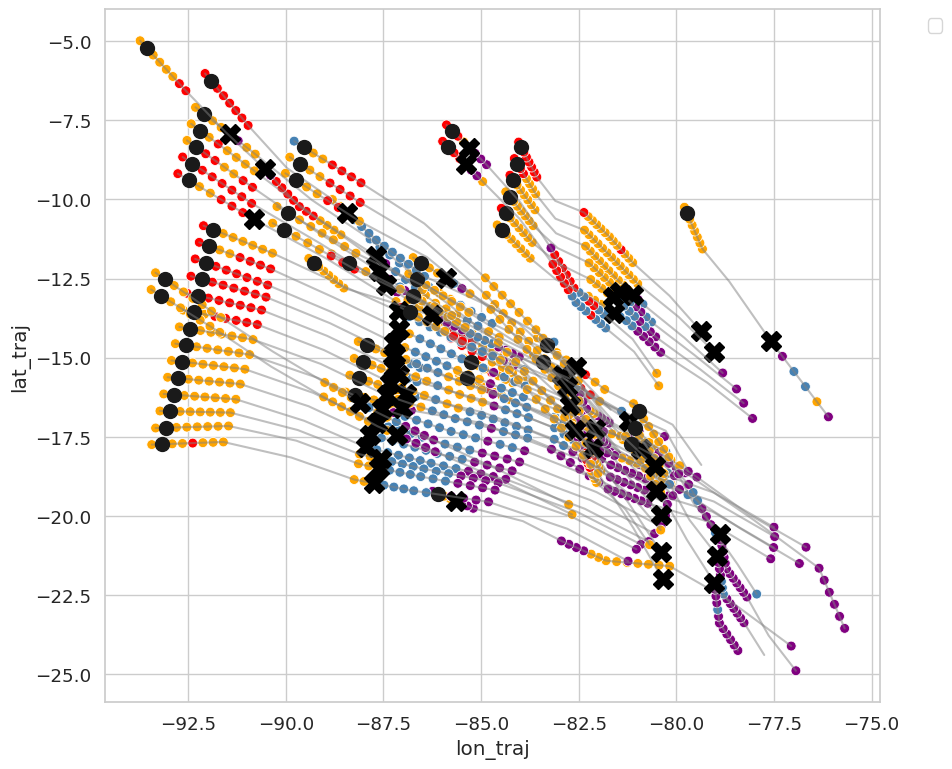

In [115]:

plt.figure(figsize=(10, 9))
bt_co_forward_from_c_with_trans = bt_co_forward_from_c.where(~ np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True)
for startpoint in bt_co_forward_from_c_with_trans.time_startpoint.values:
    tmp = bt_co_forward_from_c_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(0,50)).sortby('timestep')
    orbit = tmp.orbit_startpoint.values
    sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=10)
    transition_timestep = tmp.transition_timestep.values
    plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=15, color='black')
    sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=50, marker='o')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

plt.figure(figsize=(10, 9))
bt_co_back_from_o_with_trans = bt_co_back_from_o.where(~ np.isnan(bt_co_back_from_o.transition_time_diff) & ~np.isnan(bt_co_back_from_o.lwp), drop=True)
for startpoint in bt_co_back_from_o_with_trans.time_startpoint.values:
    tmp = bt_co_back_from_o_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(-50,1)).sortby('timestep')
    orbit = tmp.orbit_startpoint.values
    sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=10)
    transition_timestep = tmp.transition_timestep.values
    plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=15, color='black')
    sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=50, marker='o')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

#### compare CO clouds with non-transitioning clouds

In [29]:
bt_cc_forward_from_c = add_acmcap_info_to_bt(bt_cc_forward_from_c, acmcap, transition_from_msi_cats=[0,1])
bt_cc_forward_from_c = bt_cc_forward_from_c.where(bt_cc_forward_from_c.cats_startpoint.isin([0,1]), drop=True)

2025-08-01T19:20:13.001890432
CATS_0 = [0, 1] match confirmed
2025-08-01T19:20:21.065958016
No CATS = [0, 1] match found
2025-08-01T19:20:29.130020928
No CATS = [0, 1] match found
2025-08-01T19:20:37.194084992
CATS_0 = [0, 1] match confirmed
2025-08-01T19:20:45.258147968
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:20:53.322211968
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:01.386274944
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:09.450338944
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:33.642530048
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:49.770657024
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:57.834720448
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:05.898784000
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-0

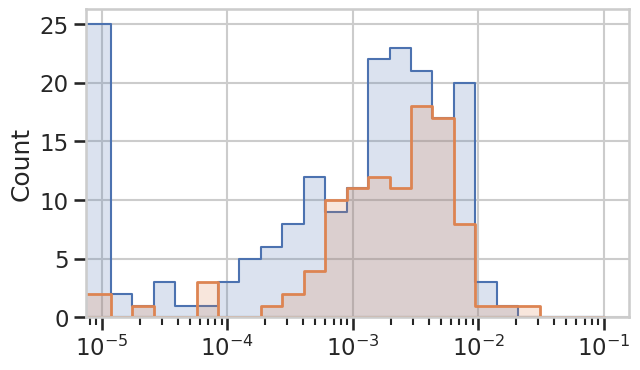

In [30]:
bins = np.logspace(-5.1, -1, 25)
bins[0] = 0
plt.figure(figsize=(7, 4))
sns.histplot(bt_cc_forward_from_c.rwp, bins=bins, alpha=0.2, element='step')

bt_co_forward_from_c_transitioning = bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True)
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

In [31]:
bt_cc_forward_from_c.cats_startpoint

<xarray.DataArray 'cats_startpoint' (time_startpoint: 194)> Size: 2kB
array([0., 0., 0., 0., 0., 1., 1., 1., 1., 0., 1., 1., 1., 1., 1., 1., 1.,
       1., 0., 0., 1., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0.,
       0., 0., 0., 1., 1., 1., 1., 0., 1., 1., 1., 1., 1., 1., 0., 1., 1.,
       1., 1., 1., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 0.,
       0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 1., 1.,
       1., 1., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 1., 1., 1., 1., 1., 0.,
       0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 0., 0., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 1., 1., 1., 1., 1., 1., 0.,
       0., 0., 1., 1., 1., 1., 1., 1., 0., 0., 0., 1., 1., 1., 1., 1., 1.,
       1., 1., 0., 1., 1., 1., 0.])
Coordinates:
  * time_startpoint  (time_startpoint) datetime64[ns] 2kB 2025-08-01T19:20:13...

In [32]:
bt_cc_forward_from_c['flag_neighboring_transitioning'] = xr.DataArray(np.zeros(len(bt_cc_forward_from_c.time_startpoint), dtype=bool), dims='time_startpoint', coords={'time_startpoint': bt_cc_forward_from_c.time_startpoint.values})
for i in range(len(bt_cc_forward_from_c.time_startpoint)):
    time_diff_to_transitioning_traj = np.abs(bt_cc_forward_from_c.time_startpoint.values[i] - bt_co_forward_from_c_transitioning.time_startpoint.values).min() / np.timedelta64(1, 's')
    if time_diff_to_transitioning_traj <= 15:  # within 15 seconds
        bt_cc_forward_from_c['flag_neighboring_transitioning'].values[i] = True

bt_cc_forward_from_c['flag_non_existing_forward_trajectory'] = (~np.isnan(bt_cc_forward_from_c.sel(timestep=slice(1,42)).goes_cats_match)).sum(dim='timestep') < 5

bt_cc_forward_from_c['flag_neighboring_open_cells'] = xr.DataArray(np.zeros(len(bt_cc_forward_from_c.time_startpoint), dtype=bool), dims='time_startpoint', coords={'time_startpoint': bt_cc_forward_from_c.time_startpoint.values})
for i in range(len(bt_cc_forward_from_c.time_startpoint)):
    t_ = bt_cc_forward_from_c.time_startpoint.values[i] 
    cats_in_neighborhood = judge_SEP[np.abs(pd.to_datetime(judge_SEP.time_mid) - t_) < pd.Timedelta('10s')]['cats']
    if 2 in cats_in_neighborhood.values:
        bt_cc_forward_from_c['flag_neighboring_open_cells'].values[i] = True

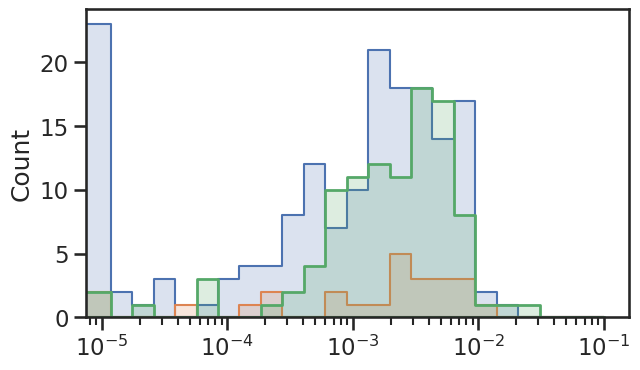

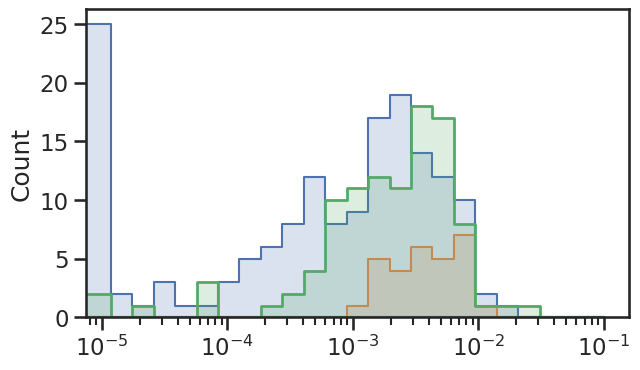

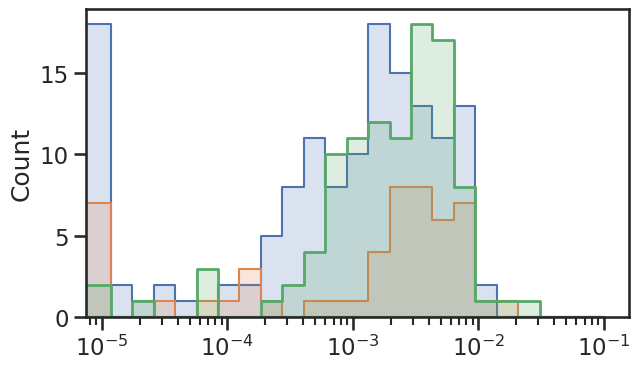

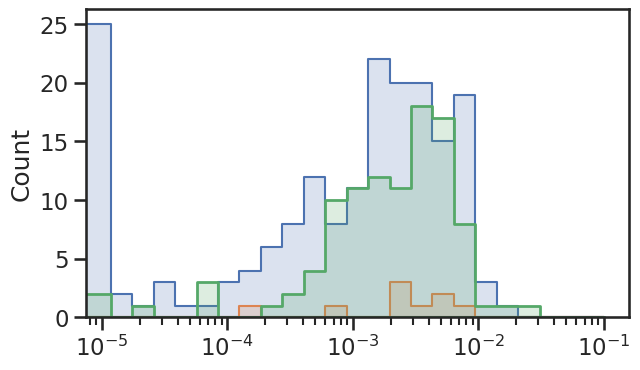

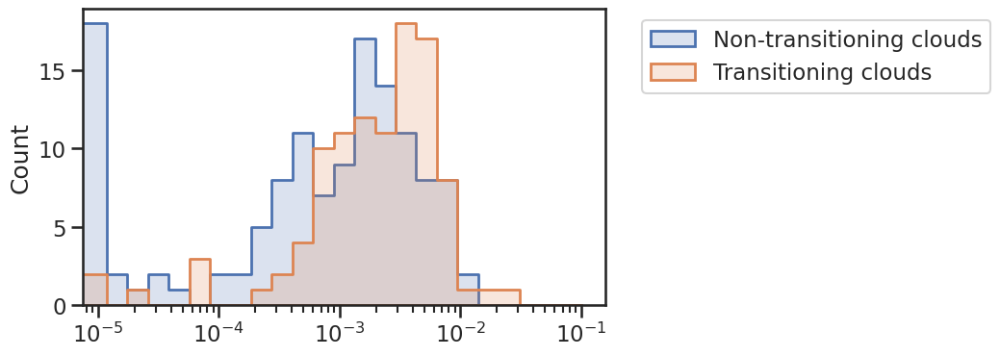

In [61]:
bins = np.logspace(-5.1, -1, 25)
bins[0] = 0

plt.figure(figsize=(7, 4))
#sns.histplot(bt_cc_forward_from_c.rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(~bt_cc_forward_from_c.flag_neighboring_transitioning).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(bt_cc_forward_from_c.flag_neighboring_transitioning).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

plt.figure(figsize=(7, 4))
#sns.histplot(bt_cc_forward_from_c.rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(bt_cc_forward_from_c.lon_traj.sel(timestep=0) > -92).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(bt_cc_forward_from_c.lon_traj.sel(timestep=0) <= -92).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

plt.figure(figsize=(7, 4))
#sns.histplot(bt_cc_forward_from_c.rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(~bt_cc_forward_from_c.flag_non_existing_forward_trajectory).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(bt_cc_forward_from_c.flag_non_existing_forward_trajectory).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

plt.figure(figsize=(7, 4))
#sns.histplot(bt_cc_forward_from_c.rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(~bt_cc_forward_from_c.flag_neighboring_open_cells).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(bt_cc_forward_from_c.flag_neighboring_open_cells).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

plt.figure(figsize=(7, 4))
bt_cc_forward_from_c_filtered = bt_cc_forward_from_c.where((
                                            #(~bt_cc_forward_from_c.flag_neighboring_transitioning) &
                                            (bt_cc_forward_from_c.lon_traj.sel(timestep=0) > -92) &
                                            (~bt_cc_forward_from_c.flag_non_existing_forward_trajectory) 
                                            #& (~bt_cc_forward_from_c.flag_neighboring_open_cells)
                                                           ))
sns.histplot(bt_cc_forward_from_c_filtered.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Non-transitioning clouds')
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

In [506]:
bt_cc_forward_from_c_filtered.rwp.median()

<xarray.DataArray 'rwp' ()> Size: 8B
array(0.00090893)

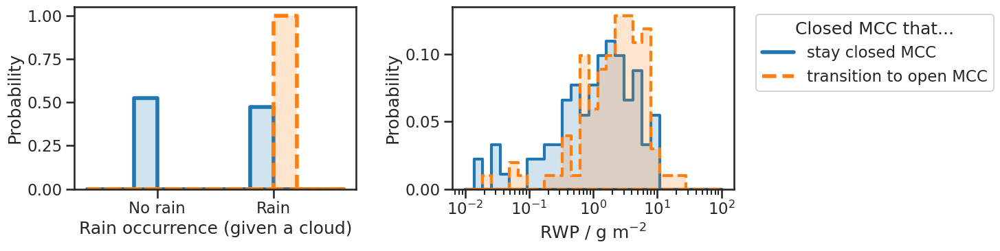

In [34]:
bt_cc_forward_from_c_filtered_0 = bt_cc_forward_from_c.where((
                                            #(~bt_cc_forward_from_c.flag_neighboring_transitioning) &
                                            (bt_cc_forward_from_c.lon_traj.sel(timestep=0) > -90) &
                                            (~bt_cc_forward_from_c.flag_non_existing_forward_trajectory) 
                                            #& (~bt_cc_forward_from_c.flag_neighboring_open_cells)
                                                           ))
bt_cc_forward_from_c_filtered_1 = bt_cc_forward_from_c.where((
                                            (bt_cc_forward_from_c.flag_neighboring_transitioning) &
                                            (bt_cc_forward_from_c.lon_traj.sel(timestep=0) > -92) &
                                            (~bt_cc_forward_from_c.flag_non_existing_forward_trajectory) 
                                            #& (~bt_cc_forward_from_c.flag_neighboring_open_cells)
                                                           ))

line_styles = ['-', '--', '-.']
colors = sns.color_palette('tab10')
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

fig, ax = plt.subplots(1,2, figsize=(11, 4))
for j,dffil in enumerate([bt_cc_forward_from_c_filtered_0, bt_co_forward_from_c_transitioning]): #6
    sns.histplot(ax=ax[0], x=(dffil['rwp_given_cloud'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                 element='step', alpha=0.2, stat='probability', lw=4, color=colors[j], ls=line_styles[j])
    sns.histplot(
        ax=ax[1], x=dffil['rwp_given_cloud']*1e3, bins=np.logspace(-2,2,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])


ax[1].set_xscale('log')
ax[1].set_xlabel('RWP / g m$^{-2}$')

ax[0].set_xticks([0.1,1.1])
ax[0].set_xticklabels(['No rain', 'Rain'])
ax[0].set_xlabel('Rain occurrence (given a cloud)')
fig.tight_layout()

legend_handles = [
    plt.Line2D([0], [0], color=colors[0], lw=4, ls=line_styles[0], label='stay closed MCC'),
    plt.Line2D([0], [0], color=colors[1], lw=4, ls=line_styles[1], label='transition to open MCC')
]
ax[1].legend(title='Closed MCC that...', handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left')

In [ ]:
'06844E' # not closed cells but disorg
'06906E' # on the edge of becomming open cell
'06937E' # on the edge of becoming open cell
'07015E' # only few timesteps after EC

'06844E'

In [82]:
# high RWP non-transitioning clouds
bt_cc_forward_from_c_filtered_0.where((bt_cc_forward_from_c_filtered_0.rwp_given_cloud > 5e-3), drop=True)[['rwp_given_cloud', 'orbit_startpoint', 'time_startpoint', 'mcop_cc']].to_dataframe()

,rwp_given_cloud,orbit_startpoint,mcop_cc
time_startpoint,,,
2025-08-06 19:39:57.834131008,0.007888,06766E,0.912750
2025-08-06 19:40:05.898194048,0.006571,06766E,0.884949
2025-08-06 19:42:14.923219008,0.006707,06766E,0.928528
2025-08-06 19:42:22.987286080,0.005336,06766E,0.929077
2025-08-17 19:25:31.347787136,0.010685,06937E,0.844940
2025-08-17 19:25:39.411851136,0.008819,06937E,0.813293
2025-08-22 19:43:45.948557056,0.005356,07015E,0.936890
2025-08-24 19:33:41.622588992,0.007804,07046E,0.923737
2025-08-28 19:13:05.064712960,0.008488,07108E,0.890472


In [402]:
rwp_thresh = 3e-3
n_trans_smaller_thresh = bt_co_forward_from_c_transitioning.where(bt_co_forward_from_c_transitioning.rwp < rwp_thresh, drop=True).rwp.count()
n_trans_greater_thresh = bt_co_forward_from_c_transitioning.where(bt_co_forward_from_c_transitioning.rwp >= rwp_thresh, drop=True).rwp.count()
n_non_trans_smaller_thresh = bt_cc_forward_from_c.where(bt_cc_forward_from_c.rwp < rwp_thresh, drop=True).rwp.count()
n_non_trans_greater_thresh = bt_cc_forward_from_c.where(bt_cc_forward_from_c.rwp >= rwp_thresh, drop=True).rwp.count()

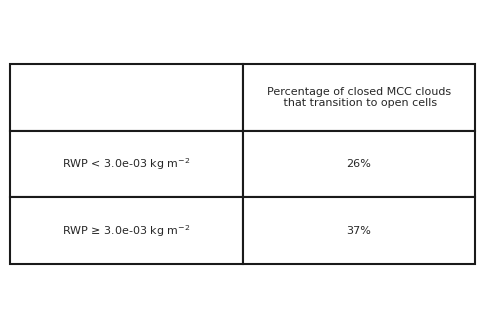

In [403]:
percent_of_transitioning_clouds_for_rwp_smaller_thresh = n_trans_smaller_thresh / (n_trans_smaller_thresh + n_non_trans_smaller_thresh)
percent_of_transitioning_clouds_for_rwp_greater_thresh = n_trans_greater_thresh / (n_trans_greater_thresh + n_non_trans_greater_thresh)

# plot a table
plt.figure(figsize=(6, 4))
table_data = [
    ['RWP < {:.1e} kg m$^{{-2}}$'.format(rwp_thresh), f'{percent_of_transitioning_clouds_for_rwp_smaller_thresh:.0%}'],
    ['RWP ≥ {:.1e} kg m$^{{-2}}$'.format(rwp_thresh), f'{percent_of_transitioning_clouds_for_rwp_greater_thresh:.0%}']
]
columns = ['', 'Percentage of closed MCC clouds\n that transition to open cells']
table = plt.table(cellText=table_data, colLabels=columns, cellLoc='center', loc='center', colWidths=[0.5, 0.5])
plt.axis('off')
table.set_fontsize(12)
table.scale(1, 4)  # Scale width=1, height=2

Text(0.5, 0, 'RWP / kg m$^{-2}$')

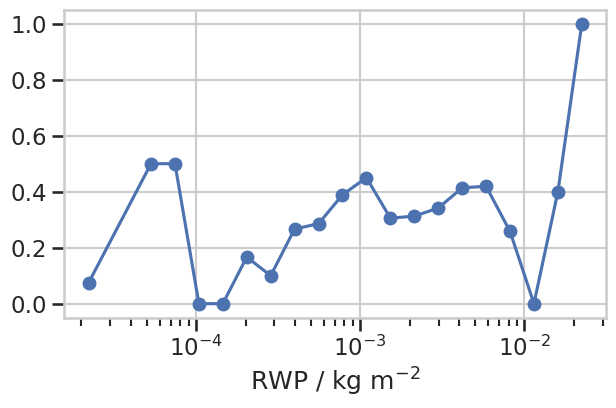

In [404]:
# plot probability that cloud will transition vs RWP
bins = np.logspace(-4.5, -1, 25)
bins[0] = 0
rwp_bin_centers = (bins[:-1] + bins[1:]) / 2
rwp_hist_trans = np.histogram(bt_co_forward_from_c_transitioning.rwp, bins=bins)[0]
rwp_hist_non_trans = np.histogram(bt_cc_forward_from_c.rwp, bins=bins)[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rwp_bin_centers, rwp_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('RWP / kg m$^{-2}$')

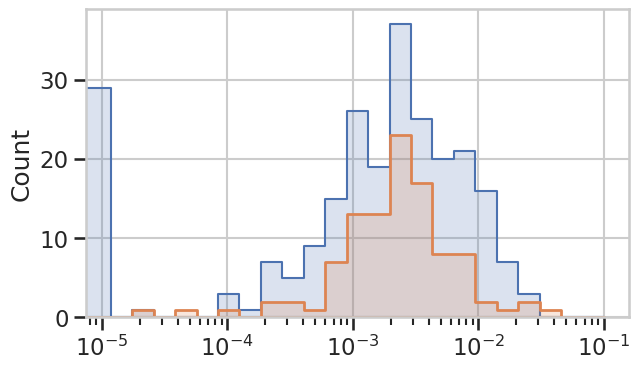

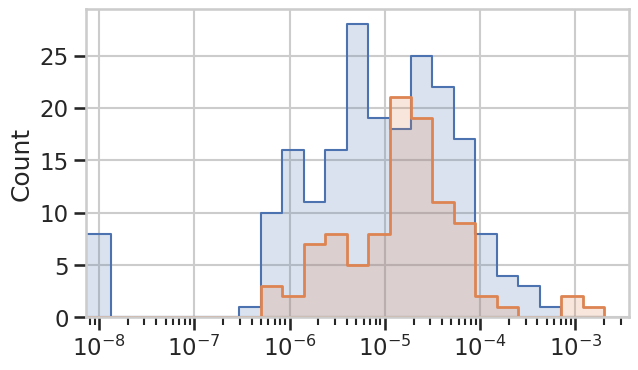

In [408]:
bins = np.logspace(-5.1, -1, 25)
bins[0] = 0
plt.figure(figsize=(7, 4))
sns.histplot(bt_cc_forward_from_c.std_rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.std_rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

bins = np.logspace(-8.1, -2.7, 25)
bins[0] = 0
plt.figure(figsize=(7, 4))
sns.histplot(bt_cc_forward_from_c.max_rain_rate_cbh, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.max_rain_rate_cbh, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')
plt.show()

---
using all ACMCAP data (but maybe this is unnecessarily complicated): 

In [ ]:
variables = ['rwp', 'orbit', 'time', 'stratus_region_index', 'latitude', 'longitude']

# handle the overlapping scene classification
acmcap_0 = acmcap[
    (acmcap.scene_id_0 != -1) &
    (acmcap.ice_flag_0 == 0) &
    (acmcap.cert_0 > 0.75) & 
    (acmcap.MCOP_cloud_cover_judge_0 >= 0.1)
              ][variables + ['cats_0', 'cert_0', 'ice_flag_0', 'scene_id_0', 'MCOP_cloud_cover_judge_0']]
acmcap_1 = acmcap[
    (acmcap.scene_id_1 != -1) &
    (acmcap.ice_flag_1 == 0) &
    (acmcap.cert_1 > 0.75) & 
    (acmcap.MCOP_cloud_cover_judge_1 >= 0.1)
              ][variables + ['cats_1', 'cert_1', 'ice_flag_1', 'scene_id_1', 'MCOP_cloud_cover_judge_1']]
acmcap_0.rename(columns={col: col.replace('_0','') for col in acmcap_0.columns if col.endswith('_0') and col != 'scene_id_0'}, inplace=True)
acmcap_1.rename(columns={col: col.replace('_1','') for col in acmcap_1.columns if col.endswith('_1') and col != 'scene_id_1'}, inplace=True)
acmcap_tmp = pd.concat([acmcap_0, acmcap_1], axis=0, ignore_index=True)
acmcap_tmp['scene_id'] = np.where(~np.isnan(acmcap_tmp.scene_id_0), acmcap_tmp.scene_id_0, acmcap_tmp.scene_id_1 + acmcap_tmp.scene_id_0.max() + acmcap_tmp.scene_id_1.min())

# only use scenes in August 2025, in stratus region 2, and closed-cell scenes (cats == 1)
acmcap_tmp = acmcap_tmp[(
    ((pd.to_datetime(acmcap_tmp['time']) >= pd.to_datetime('2025-08-01')) 
    & (acmcap_tmp.stratus_region_index == 2) 
    & (acmcap_tmp.cats.isin([0,1]))
    & (acmcap_tmp.longitude >= -92)  # if clouds are too close to longitude boundary we can not see transitions
    ) 
    #| ((acmcap_tmp.stratus_region_index == 0) & (acmcap_tmp.cats.isin([0,1])))
)]
acmcap_per_scene = acmcap_tmp.groupby(['orbit', 'scene_id']).mean()
acmcap_per_scene['max_rwp'] = acmcap_tmp.groupby(['orbit', 'scene_id']).max()['rwp']
acmcap_per_scene['std_rwp'] = acmcap_tmp.groupby(['orbit', 'scene_id']).std()['rwp']
acmcap_per_scene['inhomog_rwp'] = acmcap_per_scene['std_rwp'] / acmcap_per_scene['rwp']

In [ ]:
co_from_c_scene_id_0 = np.unique(bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1])), drop=True).scene_id_0.values)
co_from_c_scene_id_1 = np.unique(bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1])), drop=True).scene_id_1.values)
co_from_c_time = np.unique(bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1])), drop=True).time_startpoint.values)

co_from_c_15h_scene_id_0 = np.unique(bt_co_forward_from_c.where((bt_co_forward_from_c.transition_time_diff > -15) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1])), drop=True).scene_id_0.values)
co_from_c_15h_scene_id_1 = np.unique(bt_co_forward_from_c.where((bt_co_forward_from_c.transition_time_diff > -15) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1])), drop=True).scene_id_1.values)

In [ ]:
# if there is too few timesteps (< 5) after the EC overpass, discard the scene_ids
bt_to_exclude = bt_co_forward_from_c.where((~np.isnan(bt_co_forward_from_c.sel(timestep=slice(1,42)).goes_cats_match)).sum(dim='timestep') < 5, drop=True)

In [ ]:
non_trans_scene_id_0 = [acmcap_per_scene.scene_id_0.values[i] for i in range(len(acmcap_per_scene.scene_id_0.values)) if (acmcap_per_scene.scene_id_0.values[i] not in list(co_from_c_scene_id_0)) & (~np.isnan(acmcap_per_scene.scene_id_0.values[i]))]
non_trans_scene_id_1 = [acmcap_per_scene.scene_id_1.values[i] for i in range(len(acmcap_per_scene.scene_id_1.values)) if (acmcap_per_scene.scene_id_1.values[i] not in list(co_from_c_scene_id_1)) & (~np.isnan(acmcap_per_scene.scene_id_1.values[i]))]
acmcap_non_trans_scenes = acmcap_per_scene[(acmcap_per_scene.scene_id_0.isin(non_trans_scene_id_0) | acmcap_per_scene.scene_id_1.isin(non_trans_scene_id_1)) & (~acmcap_per_scene.scene_id_0.isin(bt_to_exclude.scene_id_0) & ~acmcap_per_scene.scene_id_1.isin(bt_to_exclude.scene_id_1))]

#neightbor_traj_to_trans_scene_id_0 = [acmcap_per_scene.scene_id_0.values[i] for i in range(len(acmcap_per_scene.scene_id_0.values)) if (np.abs(acmcap_per_scene.time.values[i] - co_from_c_time).min() / np.timedelta64(1, 's') <= 15)]
#neightbor_traj_to_trans_scene_id_1 = [acmcap_per_scene.scene_id_1.values[i] for i in range(len(acmcap_per_scene.scene_id_1.values)) if (np.abs(acmcap_per_scene.time.values[i] - co_from_c_time).min() / np.timedelta64(1, 's') <= 15)]
#acmcap_non_trans_non_neighbor_scenes = acmcap_per_scene[(acmcap_per_scene.scene_id_0.isin(non_trans_scene_id_0) | acmcap_per_scene.scene_id_1.isin(non_trans_scene_id_1)) 
#                                           & (~acmcap_per_scene.scene_id_0.isin(bt_to_exclude.scene_id_0) & ~acmcap_per_scene.scene_id_1.isin(bt_to_exclude.scene_id_1))
#                                           & (~acmcap_per_scene.scene_id_0.isin(neightbor_traj_to_trans_scene_id_0) & ~acmcap_per_scene.scene_id_1.isin(neightbor_traj_to_trans_scene_id_1))]
#acmcap_non_trans_neighbor_scenes = acmcap_per_scene[(acmcap_per_scene.scene_id_0.isin(non_trans_scene_id_0) | acmcap_per_scene.scene_id_1.isin(non_trans_scene_id_1)) 
#                                           & (~acmcap_per_scene.scene_id_0.isin(bt_to_exclude.scene_id_0) & ~acmcap_per_scene.scene_id_1.isin(bt_to_exclude.scene_id_1))
#                                           & (acmcap_per_scene.scene_id_0.isin(neightbor_traj_to_trans_scene_id_0) | acmcap_per_scene.scene_id_1.isin(neightbor_traj_to_trans_scene_id_1))]

acmcap_trans_scenes = acmcap_per_scene[(acmcap_per_scene.scene_id_0.isin(list(co_from_c_scene_id_0)) | acmcap_per_scene.scene_id_1.isin(list(co_from_c_scene_id_1)))]
acmcap_trans_scenes_15h_before_trans = acmcap_per_scene[(acmcap_per_scene.scene_id_0.isin(list(co_from_c_15h_scene_id_0)) | acmcap_per_scene.scene_id_1.isin(list(co_from_c_15h_scene_id_1)))]

([<matplotlib.axis.XTick at 0x7f43ef25b390>,
 [Text(1e-05, 0, '0-1e-5'),
  Text(0.0001, 0, '1e-4'),
  Text(0.001, 0, '1e-3'),
  Text(0.01, 0, '1e-2'),
  Text(0.1, 0, '1e-1')])

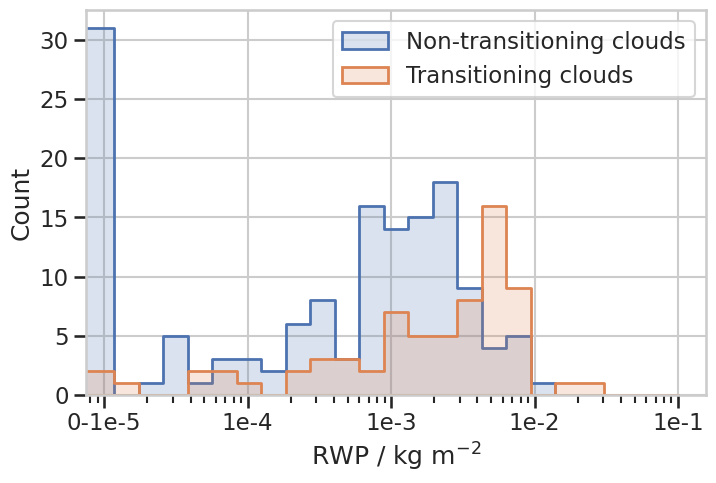

In [ ]:
bins = np.logspace(-5.1, -1, 25)
bins[0] = 0

plt.figure(figsize=(8, 5))
#sns.histplot(data=acmcap_mean, x='rwp', bins=np.logspace(-4.5, -1, 30), alpha=0.2, linewidth=2, element='step')
sns.histplot(acmcap_non_trans_scenes, x='rwp', bins=bins, alpha=0.2, linewidth=2, element='step', label='Non-transitioning clouds')
#sns.histplot(acmcap_non_trans_non_neighbor_scenes, x='rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
#sns.histplot(acmcap_non_trans_neighbor_scenes, x='rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
sns.histplot(acmcap_trans_scenes, x='rwp', bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
#sns.histplot(acmcap_mean_trans_scenes_15h_before_trans, x='rwp', bins=np.logspace(-4.5, -1, 30), alpha=0.2, linewidth=2, element='step')
plt.legend()
plt.xscale('log')
#plt.yscale('log')
plt.xlabel('RWP / kg m$^{-2}$')
plt.xticks([1e-5, 1e-4, 1e-3, 1e-2, 1e-1], labels=['0-1e-5', '1e-4', '1e-3', '1e-2', '1e-1'])

In [ ]:
rwp_thresh = 3e-3
n_trans_smaller_thresh = acmcap_trans_scenes[acmcap_trans_scenes.rwp < rwp_thresh].rwp.count()
n_trans_greater_thresh = acmcap_trans_scenes[acmcap_trans_scenes.rwp >= rwp_thresh].rwp.count()
n_non_trans_smaller_thresh = acmcap_non_trans_scenes[acmcap_non_trans_scenes.rwp < rwp_thresh].rwp.count()
n_non_trans_greater_thresh = acmcap_non_trans_scenes[acmcap_non_trans_scenes.rwp >= rwp_thresh].rwp.count()

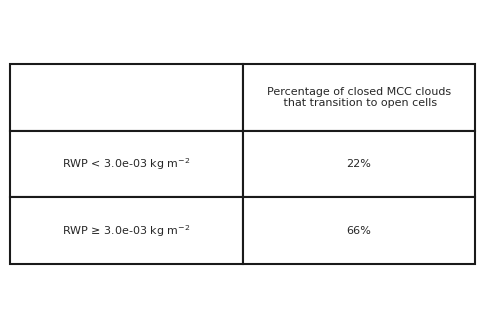

In [ ]:
percent_of_transitioning_clouds_for_rwp_smaller_thresh = n_trans_smaller_thresh / (n_trans_smaller_thresh + n_non_trans_smaller_thresh)
percent_of_transitioning_clouds_for_rwp_greater_thresh = n_trans_greater_thresh / (n_trans_greater_thresh + n_non_trans_greater_thresh)

# plot a table
plt.figure(figsize=(6, 4))
table_data = [
    ['RWP < {:.1e} kg m$^{{-2}}$'.format(rwp_thresh), f'{percent_of_transitioning_clouds_for_rwp_smaller_thresh:.0%}'],
    ['RWP ≥ {:.1e} kg m$^{{-2}}$'.format(rwp_thresh), f'{percent_of_transitioning_clouds_for_rwp_greater_thresh:.0%}']
]
columns = ['', 'Percentage of closed MCC clouds\n that transition to open cells']
table = plt.table(cellText=table_data, colLabels=columns, cellLoc='center', loc='center', colWidths=[0.5, 0.5])
plt.axis('off')
table.set_fontsize(12)
table.scale(1, 4)  # Scale width=1, height=2

Text(0.5, 0, 'RWP / kg m$^{-2}$')

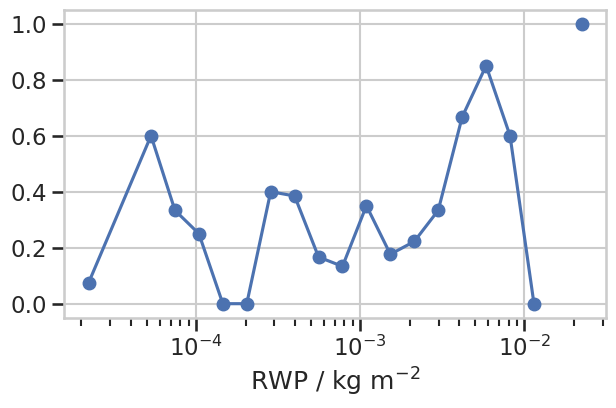

In [ ]:
# plot probability that cloud will transition vs RWP
bins = np.logspace(-4.5, -1, 25)
bins[0] = 0
rwp_bin_centers = (bins[:-1] + bins[1:]) / 2
rwp_hist_trans = np.histogram(acmcap_trans_scenes.rwp, bins=bins)[0]
rwp_hist_non_trans = np.histogram(acmcap_non_trans_scenes.rwp, bins=bins)[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rwp_bin_centers, rwp_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('RWP / kg m$^{-2}$')

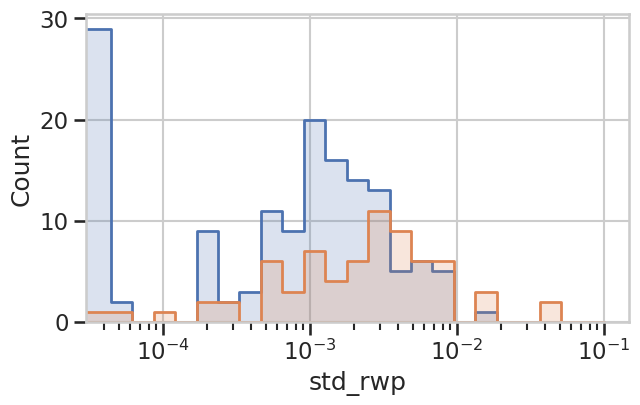

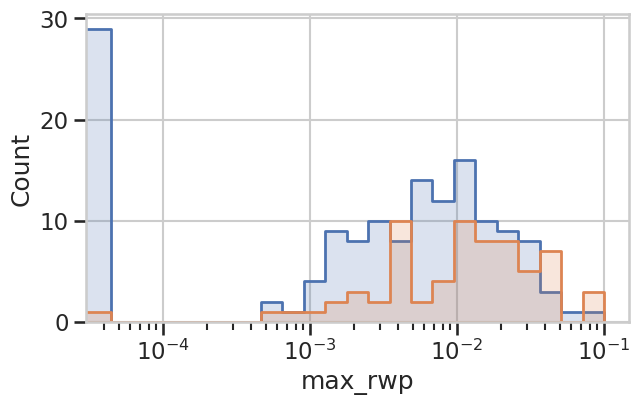

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(acmcap_non_trans_scenes, x='std_rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
sns.histplot(acmcap_trans_scenes, x='std_rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
plt.xscale('log')
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(acmcap_non_trans_scenes, x='max_rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
sns.histplot(acmcap_trans_scenes, x='max_rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
plt.xscale('log')
plt.show()

In [ ]:
acmcap_non_trans_scenes[acmcap_non_trans_scenes.rwp > 4e-3]

rwp                          time  stratus_region_index  \
orbit  scene_id                                                                 
06766E 6250.0    0.008094 2025-08-06 19:39:57.009383168                   2.0   
       14849.0   0.007275 2025-08-06 19:40:05.009664768                   2.0   
06906E 6468.0    0.005552 2025-08-15 19:38:30.397530624                   2.0   
07015E 6616.0    0.004509 2025-08-22 19:42:56.616665088                   2.0   
07030E 6655.0    0.005970 2025-08-23 18:54:26.420296192                   2.0   
07046E 6685.0    0.004227 2025-08-24 19:34:13.032254720                   2.0   
07108E 6783.0    0.007177 2025-08-28 19:10:39.000881664                   2.0   
       15380.0   0.007838 2025-08-28 19:10:31.000596736                   2.0   
       15400.0   0.011019 2025-08-28 19:13:12.221208832                   2.0   
07155E 6888.0    0.006407 2025-08-31 19:39:54.547473664                   2.0   
       15485.0   0.004662 2025-08-31 19:39:46.475539456                   2.0   

                  latitude  longitude  cats      cert  ice_flag  scene_id_0  \
orbit  scene_id                                                               
06766E 6250.0    -8.297562 -86.902600   1.0  0.999479       0.0      6250.0   
       14849.0   -8.815333 -87.000709   1.0  0.999453       0.0         NaN   
06906E 6468.0   -16.641816 -87.628643   1.0  0.855254       0.0      6468.0   
07015E 6616.0    -5.159353 -87.284779   1.0  0.972031       0.0      6616.0   
07030E 6655.0   -18.091561 -76.819246   1.0  0.979732       0.0      6655.0   
07046E 6685.0   -14.554765 -86.293550   1.0  0.906895       0.0      6685.0   
07108E 6783.0    -9.337134 -79.737531   0.0  0.895437       0.0      6783.0   
       15380.0   -8.819410 -79.639043   0.0  0.918662       0.0         NaN   
       15400.0  -19.242447 -81.672351   1.0  0.994667       0.0         NaN   
07155E 6888.0    -8.294692 -86.925218   1.0  0.839952       0.0      6888.0   
       15485.0   -7.772162 -86.826442   1.0  0.857917       0.0         NaN   

                 MCOP_cloud_cover_judge  scene_id_1   max_rwp   std_rwp  \
orbit  scene_id                                                           
06766E 6250.0                  0.946960         NaN  0.031703  0.007576   
       14849.0                 0.878540      6251.0  0.031703  0.007435   
06906E 6468.0                  0.827393         NaN  0.021904  0.005039   
07015E 6616.0                  0.984314         NaN  0.033879  0.005987   
07030E 6655.0                  0.850769         NaN  0.024780  0.006289   
07046E 6685.0                  0.846741         NaN  0.037469  0.006444   
07108E 6783.0                  0.978149         NaN  0.040749  0.007634   
       15380.0                 0.956543      6782.0  0.040749  0.007488   
       15400.0                 0.962341      6802.0  0.084557  0.015587   
07155E 6888.0                  0.990784         NaN  0.027170  0.006083   
       15485.0                 0.931885      6887.0  0.027170  0.006763   

                 inhomog_rwp  
orbit  scene_id               
06766E 6250.0       0.936027  
       14849.0      1.022069  
06906E 6468.0       0.907530  
07015E 6616.0       1.327759  
07030E 6655.0       1.053405  
07046E 6685.0       1.524578  
07108E 6783.0       1.063572  
       15380.0      0.955386  
       15400.0      1.414560  
07155E 6888.0       0.949495  
       15485.0      1.450693

#### ACMCAP frames for CO transitions

In [23]:
sys.path.append('./../../../ectools/')
from ectools import ecio
from ectools import ecplot as ecplt

In [ ]:
bt_co_c = bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True)
bt_co_o = bt_co_back_from_o.where(~np.isnan(bt_co_back_from_o.transition_time_diff), drop=True)

orbits_c = np.unique(bt_co_c.orbit_startpoint)
orbits_o = np.unique(bt_co_o.orbit_startpoint)
orbits = np.unique(np.concatenate((orbits_c, orbits_o)))
#orbit = orbits[0]
month = '08'

for orbit in orbits: # ['06766E']: '06704E'
    print(f'Plotting orbit {orbit}')

    bt_co_c_orbit = bt_co_c.where(bt_co_c.orbit_startpoint == orbit, drop=True)
    bt_co_o_orbit = bt_co_o.where(bt_co_o.orbit_startpoint == orbit, drop=True)

    # load ACMCAP
    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/{month}/*/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
    lat_range = (-22.5, -2.5)
    lon_range = (-95, -75)
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_range[0]) & (ACMCAP.latitude < lat_range[1]) & (ACMCAP.longitude > lon_range[0]) & (ACMCAP.longitude < lon_range[1]), drop=True)
    ACMCAP.encoding = encoding.copy()

    # load MCOP
    try:
        filename = glob.glob(f'/home/jmayer/Object_Data/MSI_COP_2A/2025/{month}/*/*_{orbit}.h5')[0]
        MCOP = ecio.load_MCOP(filename)
        MCOP = MCOP.assign_coords(
            {
            'along_track': (
                ["along_track"],
                MCOP['along_track'].data,
                MCOP['along_track'].attrs
                ),
            'across_track': (
                ['across_track'],
                MCOP['across_track'].data,
                MCOP['across_track'].attrs
                )
            })
        MCOP2 = MCOP.where((MCOP.latitude > lat_range[0]) & (MCOP.latitude < lat_range[1]) & (MCOP.longitude > lon_range[0]) & (MCOP.longitude < lon_range[1]), drop=True)
        MCOP2 = MCOP2[['latitude','longitude','cloud_water_path','cloud_optical_thickness','cloud_effective_radius']]
        MCOP2['time'] = MCOP['time'].sel(along_track=MCOP2.along_track)
        MCOP2 = MCOP2.assign_coords(
            {
            'time': (
                ['along_track'],
                MCOP2.time.data,
                MCOP2.time.attrs
                )
            })
        MCOP2 = MCOP2.swap_dims({'along_track': 'time'})
    except:
        print(f'No MCOP data for {orbit}')
        MCOP2 = None

    # plot
    fig, axs = plt.subplots(3,1, figsize=(35,15), gridspec_kw={'height_ratios': [1, 1, 1]})

    # highlight scenes for which transitions were found
    for ax in axs[0:2]:
        for i in range(len(bt_co_c_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='yellow', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_c_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            ax.annotate(bt_co_c_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    for ax in axs[0:2]:
        for i in range(len(bt_co_o_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='deeppink', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_o_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            ax.annotate(bt_co_o_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    ax = axs[0]
    ecplt.plot_EC_2D(ax, ACMCAP, 'liquid_water_content', "$L$", units="kg m$^{-3}$", plot_scale='log', plot_range=[1e-6,1e-3], cmap='chiljet2', hmax=4000)

    ax = axs[1]
    ecplt.plot_EC_2D(ax, ACMCAP, 'rain_water_content', "$R$", hmax=4000)

    if MCOP2 is not None:
        ax = axs[2]
        ax.sharex(axs[0])
        (np.log(MCOP2.cloud_water_path*1000)).T.plot(ax=ax, cmap='viridis', vmax=7, vmin=2.5, add_colorbar=False)
        ax.axhline(284, color='k', linestyle='--', lw=2)
        ax.set_title('MCOP liquid water path')
        # add cbar to the right
        cbar_ax = fig.add_axes([0.99, 0.09, 0.009, 0.18])  # [left, bottom, width, height]
        cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
        cbar.set_label('log(LWP) [g m$^{-2}$]')
        cbar.set_ticks([3,4,5,6])
    fig.tight_layout()
    plt.show()

<Axes: xlabel='lon_traj', ylabel='lat_traj'>

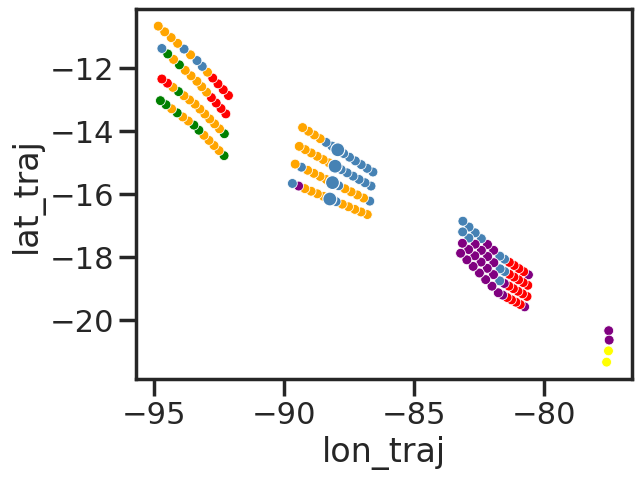

In [82]:
orbit = '06766E'
tmp = bt_co_back_from_o.where(bt_co_back_from_o.orbit_startpoint == orbit, drop=True)
for i in range(len(tmp.timestep)):
    sns.scatterplot(data = tmp.isel(timestep=i), x='lon_traj', y='lat_traj', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=50)

sns.scatterplot(data = tmp.sel(timestep=0), x='lon_traj', y='lat_traj', hue='goes_cats_match', palette=palette_goes_cats, legend=False, s=100)

#### example for presentation

IndexError: index 1 is out of bounds for axis 0 with size 0

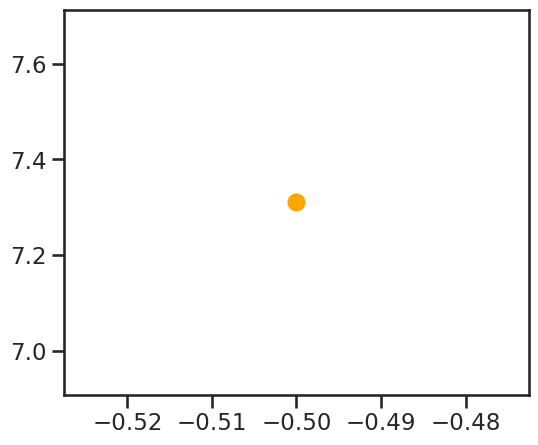

In [33]:
sns.set_context('talk', font_scale=1)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

bt_co_forward_from_c.where(bt_co_forward_from_c.orbit_startpoint == '06766E', drop=True)

plt.figure(figsize=(6, 5))
tmp_c = bt_co_forward_from_c.where(bt_co_forward_from_c.orbit_startpoint == '06766E', drop=True)
#sns.scatterplot(data = tmp_c, x='transition_time_diff', y='rain_rate_cbh', hue='lwp', hue_norm=LogNorm(1e-2, 1e-1), palette='viridis', legend=False, s=100)
tmp_c_sel = tmp_c.where(~np.isnan(tmp_c.transition_time_diff), drop=True).isel(time_startpoint=[9])
plt.plot([tmp_c_sel.transition_time_diff.values], [tmp_c_sel.rwp.values*1e3], 'o', color='orange', markersize=12)

tmp_o = bt_co_back_from_o.where(bt_co_back_from_o.orbit_startpoint == '06766E', drop=True)
#sns.scatterplot(data = tmp_o, x='transition_time_diff', y='rain_rate_cbh', hue='lwp', hue_norm=LogNorm(1e-2, 1e-1), palette='viridis', legend=False, s=100)
tmp_o_sel = tmp_o.where(~np.isnan(tmp_o.transition_time_diff), drop=True).isel(time_startpoint=[1])
plt.plot([tmp_o_sel.transition_time_diff.values], [tmp_o_sel.rwp.values*1e3], 'o', color='deeppink', markersize=12)

plt.yscale('log')
plt.ylim(2e-4, 5e-2)
plt.xlim(-5, 5)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / kg m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')

#sm = plt.cm.ScalarMappable(cmap='viridis', norm=LogNorm(1e-2, 1e-1))
#sm.set_array([])
#cbar = plt.colorbar(sm, ax=plt.gca(), fraction=0.025)
#cbar.set_label('LWP/ kg m$^{-2}$')

1.0
Original shape: FrozenMappingWarningOnValuesAccess({'y': 2712, 'x': 2712, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 548, 'x': 557, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Lat range: -23.19 to -2.12
Lon range: -97.63 to -74.62


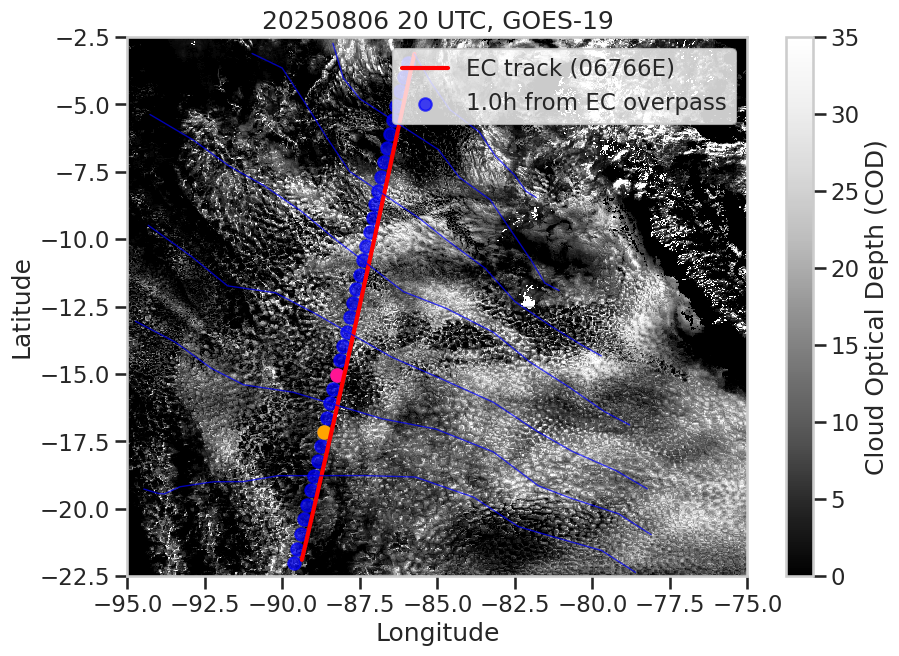

In [64]:
orbit = '06766E'
bt_orbit = bt_with_goes2.where(bt_with_goes2.orbit_startpoint == orbit, drop=True)
overpass_date = str(bt_orbit.time_startpoint[0].dt.strftime('%Y%m%d').values)
valid_dates = np.abs(bt_orbit.datetime_traj - bt_orbit.time_startpoint[0]) < np.timedelta64(42, 'h')
bt_orbit = bt_orbit.where(valid_dates)

goes_time = 20
overpass_time = 19
date = overpass_date

timestep = (pd.to_datetime(date+str(goes_time).zfill(2)+'00') - pd.to_datetime(overpass_date+str(overpass_time).zfill(2)+'00')).total_seconds() / 3600
print(timestep)

with xr.open_dataset(f'/home/jmayer/Object_Data/GOES19/goes19_CODF_{date}_{goes_time}00.nc') as ds:
    # Crop to your region
    ds_COD_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

plt.figure(figsize=(10, 7))
plt.pcolormesh(ds_COD_cropped.longitude, ds_COD_cropped.latitude, ds_COD_cropped['COD'], 
            vmax=35, cmap='Greys_r', shading='auto')
plt.colorbar(label='Cloud Optical Depth (COD)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title(f'{date} {goes_time} UTC, GOES-19')

bt_startpoint = bt_orbit.sel(timestep=0)
plt.plot(bt_startpoint.lon_traj.values, bt_startpoint.lat_traj.values, color='red', lw=3, label=f'EC track ({orbit})')

bt_at_sel_timestep = bt_orbit.sel(timestep=timestep)
plt.scatter(bt_at_sel_timestep.lon_traj.values, bt_at_sel_timestep.lat_traj.values, color='blue', marker='o', alpha=0.7, label=f'{timestep}h from EC overpass')

tmp_at_sel_timestep = tmp_c.where(~np.isnan(tmp_c.transition_time_diff), drop=True).sel(timestep=timestep).isel(time_startpoint=[11])
plt.scatter(tmp_at_sel_timestep.lon_traj.values, tmp_at_sel_timestep.lat_traj.values, color='orange', marker='o', alpha=1)

tmp_at_sel_timestep = tmp_o.where(~np.isnan(tmp_o.transition_time_diff), drop=True).sel(timestep=timestep).isel(time_startpoint=[1])
plt.scatter(tmp_at_sel_timestep.lon_traj.values, tmp_at_sel_timestep.lat_traj.values, color='deeppink', marker='o', alpha=1)


for i in range(len(bt_orbit.time_startpoint)//5):
    traj = bt_orbit.isel(time_startpoint=i*5).sortby('timestep')
    plt.plot(traj.lon_traj.values, traj.lat_traj.values, color='blue', lw=1, alpha=0.7)

plt.legend()
plt.ylim(lat_bounds)
plt.xlim(lon_bounds)
plt.show()

Plotting orbit 06766E


Selecting frame from 9 to 4877
Selecting frame from 443 to 11483


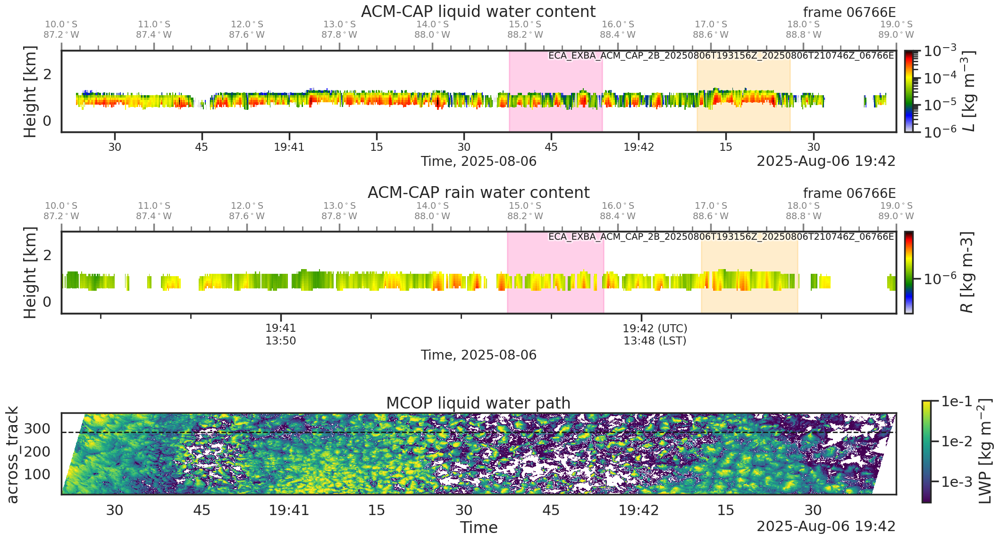

In [67]:
sns.set_style('white')
month = '08'

for orbit in ['06766E']:
    print(f'Plotting orbit {orbit}')

    bt_co_c_orbit = bt_co_c.where(bt_co_c.orbit_startpoint == orbit, drop=True)
    bt_co_o_orbit = bt_co_o.where(bt_co_o.orbit_startpoint == orbit, drop=True)
    bt_co_c_orbit = bt_co_c_orbit.where(~np.isnan(bt_co_c_orbit.transition_time_diff), drop=True).isel(time_startpoint=[11])
    bt_co_o_orbit = bt_co_o_orbit.where(~np.isnan(bt_co_o_orbit.transition_time_diff), drop=True).isel(time_startpoint=[1])

    # load ACMCAP
    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/{month}/*/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
    lat_range = (-19, -10)
    lon_range = (-95, -75)
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_range[0]) & (ACMCAP.latitude < lat_range[1]) & (ACMCAP.longitude > lon_range[0]) & (ACMCAP.longitude < lon_range[1]), drop=True)
    ACMCAP.encoding = encoding.copy()

    # load MCOP
    try:
        filename = glob.glob(f'/home/jmayer/Object_Data/MSI_COP_2A/2025/{month}/*/*_{orbit}.h5')[0]
        MCOP = ecio.load_MCOP(filename)
        MCOP = MCOP.assign_coords(
            {
            'along_track': (
                ["along_track"],
                MCOP['along_track'].data,
                MCOP['along_track'].attrs
                ),
            'across_track': (
                ['across_track'],
                MCOP['across_track'].data,
                MCOP['across_track'].attrs
                )
            })
        MCOP2 = MCOP.where((MCOP.latitude > lat_range[0]) & (MCOP.latitude < lat_range[1]) & (MCOP.longitude > lon_range[0]) & (MCOP.longitude < lon_range[1]), drop=True)
        MCOP2 = MCOP2[['latitude','longitude','cloud_water_path','cloud_optical_thickness','cloud_effective_radius']]
        MCOP2['time'] = MCOP['time'].sel(along_track=MCOP2.along_track)
        MCOP2 = MCOP2.assign_coords(
            {
            'time': (
                ['along_track'],
                MCOP2.time.data,
                MCOP2.time.attrs
                )
            })
        MCOP2 = MCOP2.swap_dims({'along_track': 'time'})
    except:
        print(f'No MCOP data for {orbit}')
        MCOP2 = None

    # plot
    fig, axs = plt.subplots(3,1, figsize=(20,12), gridspec_kw={'height_ratios': [1, 1, 1]})

    # highlight scenes for which transitions were found
    for ax in axs[0:2]:
        for i in range(len(bt_co_c_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='orange', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_c_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            #ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            #ax.annotate(bt_co_c_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    for ax in axs[0:2]:
        for i in range(len(bt_co_o_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='deeppink', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_o_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            #ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            #ax.annotate(bt_co_o_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    ax = axs[0]
    ecplt.plot_EC_2D(ax, ACMCAP, 'liquid_water_content', "$L$", units="kg m$^{-3}$", plot_scale='log', plot_range=[1e-6,1e-3], cmap='chiljet2', hmax=3000)

    ax = axs[1]
    ecplt.plot_EC_2D(ax, ACMCAP, 'rain_water_content', "$R$", hmax=3000)

    if MCOP2 is not None:
        ax = axs[2]
        ax.sharex(axs[0])
        (np.log(MCOP2.cloud_water_path)).T.plot(ax=ax, cmap='viridis', vmax=-3.2, vmin=-1, add_colorbar=False)
        ax.axhline(284, color='k', linestyle='--', lw=2)
        ax.set_title('MCOP liquid water path')
        # add cbar to the right
        cbar_ax = fig.add_axes([0.99, 0.09, 0.009, 0.18])  # [left, bottom, width, height]
        cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
        cbar.set_label('LWP [kg m$^{-2}$]')
        cbar.set_ticks([-3,-2,-1])
        cbar.set_ticklabels(['1e-3', '1e-2', '1e-1'])
    fig.tight_layout()
    plt.show()

Plotting orbit 06704E
Selecting frame from 6 to 4874
Selecting frame from 433 to 11472


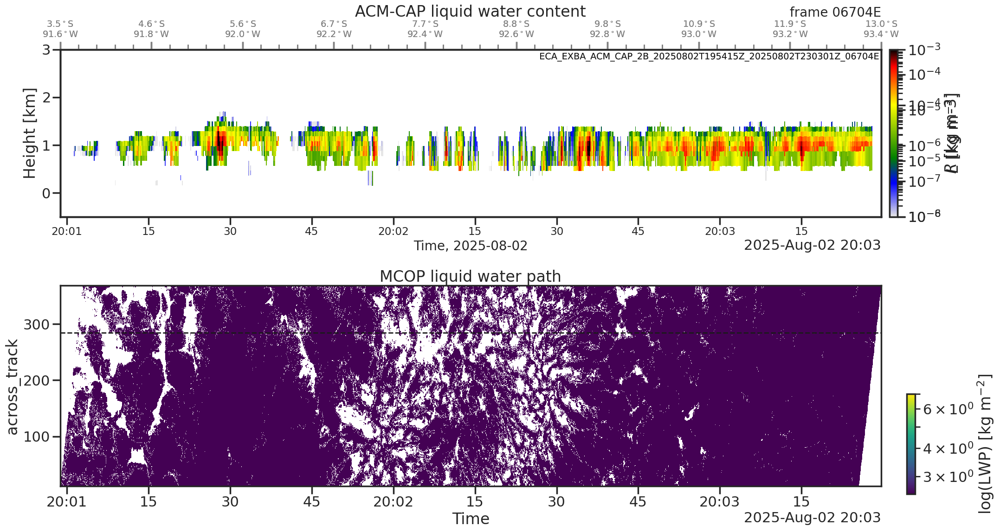

In [ ]:
bt_co_c = bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True)
bt_co_o = bt_co_back_from_o.where(~np.isnan(bt_co_back_from_o.transition_time_diff), drop=True)

orbits_c = np.unique(bt_co_c.orbit_startpoint)
orbits_o = np.unique(bt_co_o.orbit_startpoint)
orbits = np.unique(np.concatenate((orbits_c, orbits_o)))
#orbit = orbits[0]
month = '08'

for orbit in ['06704E']: # ['06766E']: 
    print(f'Plotting orbit {orbit}')

    # load ACMCAP
    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/{month}/*/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
    lat_range = (-13, -3.5)
    lon_range = (-95, -75)
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_range[0]) & (ACMCAP.latitude < lat_range[1]) & (ACMCAP.longitude > lon_range[0]) & (ACMCAP.longitude < lon_range[1]), drop=True)
    ACMCAP.encoding = encoding.copy()

    # load MCOP
    try:
        filename = glob.glob(f'/home/jmayer/Object_Data/MSI_COP_2A/2025/{month}/*/*_{orbit}.h5')[0]
        MCOP = ecio.load_MCOP(filename)
        MCOP = MCOP.assign_coords(
            {
            'along_track': (
                ["along_track"],
                MCOP['along_track'].data,
                MCOP['along_track'].attrs
                ),
            'across_track': (
                ['across_track'],
                MCOP['across_track'].data,
                MCOP['across_track'].attrs
                )
            })
        MCOP2 = MCOP.where((MCOP.latitude > lat_range[0]) & (MCOP.latitude < lat_range[1]) & (MCOP.longitude > lon_range[0]) & (MCOP.longitude < lon_range[1]), drop=True)
        MCOP2 = MCOP2[['latitude','longitude','cloud_water_path','cloud_optical_thickness','cloud_effective_radius']]
        MCOP2['time'] = MCOP['time'].sel(along_track=MCOP2.along_track)
        MCOP2 = MCOP2.assign_coords(
            {
            'time': (
                ['along_track'],
                MCOP2.time.data,
                MCOP2.time.attrs
                )
            })
        MCOP2 = MCOP2.swap_dims({'along_track': 'time'})
    except:
        print(f'No MCOP data for {orbit}')
        MCOP2 = None

    # plot
    fig, axs = plt.subplots(2,1, figsize=(20,10), gridspec_kw={'height_ratios': [1, 1]})

    ax = axs[0]
    ecplt.plot_EC_2D(ax, ACMCAP, 'rain_water_content', "$R$", cmap='Blues', plot_range=[1e-6,1e-3], hmax=3000)
    ax.collections[0].colorbar.remove()
    ecplt.plot_EC_2D(ax, ACMCAP, 'liquid_water_content', "$L$", units="kg m$^{-3}$", plot_scale='log', plot_range=[1e-6,1e-3], cmap='chiljet2', hmax=3000)

    lcl = acmcap[(acmcap.orbit == orbit) & (acmcap.latitude > -13) & (acmcap.latitude < -3.5)].lcl.values
    time = acmcap[(acmcap.orbit == orbit) & (acmcap.latitude > -13) & (acmcap.latitude < -3.5)].time.values
    plt.plot(time, lcl, color='black', lw=1, label='LCL')

    if MCOP2 is not None:
        ax = axs[1]
        ax.sharex(axs[0])
        MCOP2.cloud_water_path.T.plot(ax=ax, cmap='viridis', norm=LogNorm(vmin=1e-2, vmax=1e0), add_colorbar=False)
        ax.axhline(284, color='k', linestyle='--', lw=2)
        ax.set_title('MCOP liquid water path')
        # add cbar to the right
        cbar_ax = fig.add_axes([0.99, 0.12, 0.009, 0.3])  # [left, bottom, width, height]
        cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
        cbar.set_label('LWP [kg m$^{-2}$]')
    fig.tight_layout()
    plt.show()

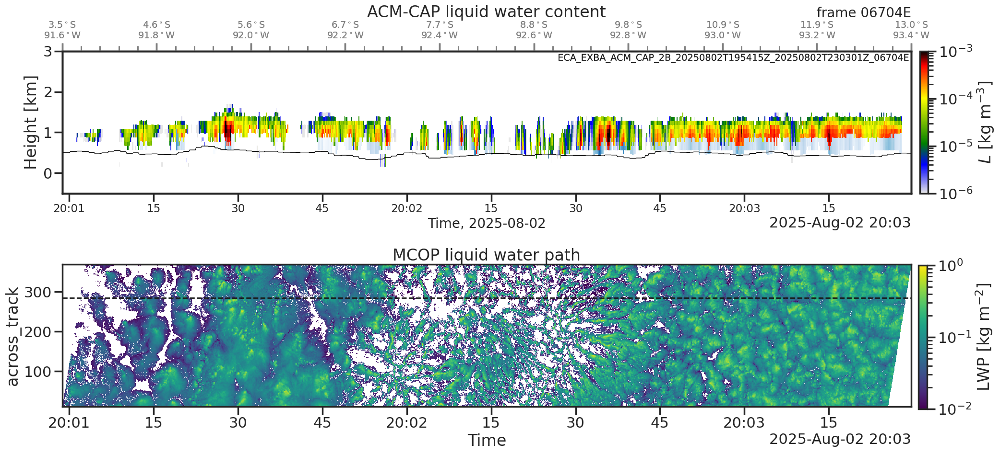

In [42]:
fig, axs = plt.subplots(2,1, figsize=(20,10), gridspec_kw={'height_ratios': [1, 1]})

ax = axs[0]
ecplt.plot_EC_2D(ax, ACMCAP, 'rain_water_content', "$R$", cmap='Blues', plot_range=[1e-6,1e-3], hmax=3000)
ax.collections[0].colorbar.remove()
ecplt.plot_EC_2D(ax, ACMCAP, 'liquid_water_content', "$L$", units="kg m$^{-3}$", plot_scale='log', plot_range=[1e-6,1e-3], cmap='chiljet2', hmax=3000)

lcl = acmcap[(acmcap.orbit == orbit) & (acmcap.latitude > -13) & (acmcap.latitude < -3.5)].lcl.values
time = acmcap[(acmcap.orbit == orbit) & (acmcap.latitude > -13) & (acmcap.latitude < -3.5)].time.values
plt.plot(time, lcl, color='black', lw=1, label='LCL')

if MCOP2 is not None:
    ax = axs[1]
    ax.sharex(axs[0])
    MCOP2.cloud_water_path.T.plot(ax=ax, cmap='viridis', norm=LogNorm(vmin=1e-2, vmax=1e0), add_colorbar=False)
    ax.axhline(284, color='k', linestyle='--', lw=2)
    ax.set_title('MCOP liquid water path')
    # add cbar to the right
    cbar_ax = fig.add_axes([0.97, 0.12, 0.009, 0.3])  # [left, bottom, width, height]
    cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
    cbar.set_label('LWP [kg m$^{-2}$]')
fig.tight_layout()
plt.show()

### OC transitions

In [87]:
bt_oc_forward_from_o = add_acmcap_info_to_bt(bt_oc_forward_from_o, acmcap, transition_from_msi_cats=[2])

2025-08-01T19:23:10.411299136
CATS_0 = [2] match confirmed
CATS_1 = [2] match confirmed
2025-08-01T19:23:18.475363072
CATS_1 = [2] match confirmed
2025-08-02T20:02:00.062075968
CATS_0 = [2] match confirmed
CATS_1 = [2] match confirmed
2025-08-02T20:02:08.126139968
CATS_0 = [2] match confirmed
CATS_1 = [2] match confirmed
2025-08-02T20:02:16.190203008
CATS_0 = [2] match confirmed
CATS_1 = [2] match confirmed
2025-08-02T20:02:24.254266880
CATS_0 = [2] match confirmed
CATS_1 = [2] match confirmed
2025-08-02T20:02:32.318329920
CATS_0 = [2] match confirmed
2025-08-03T19:10:56.995927488
CATS_0 = [2] match confirmed
2025-08-03T19:12:49.892819456
CATS_0 = [2] match confirmed
CATS_1 = [2] match confirmed
2025-08-03T19:12:57.956883008
CATS_0 = [2] match confirmed
CATS_1 = [2] match confirmed
2025-08-03T19:13:06.020949440
CATS_0 = [2] match confirmed
2025-08-06T19:41:34.602900928
CATS_0 = [2] match confirmed
CATS_1 = [2] match confirmed
2025-08-06T19:41:42.666965120
CATS_0 = [2] match confirmed
C

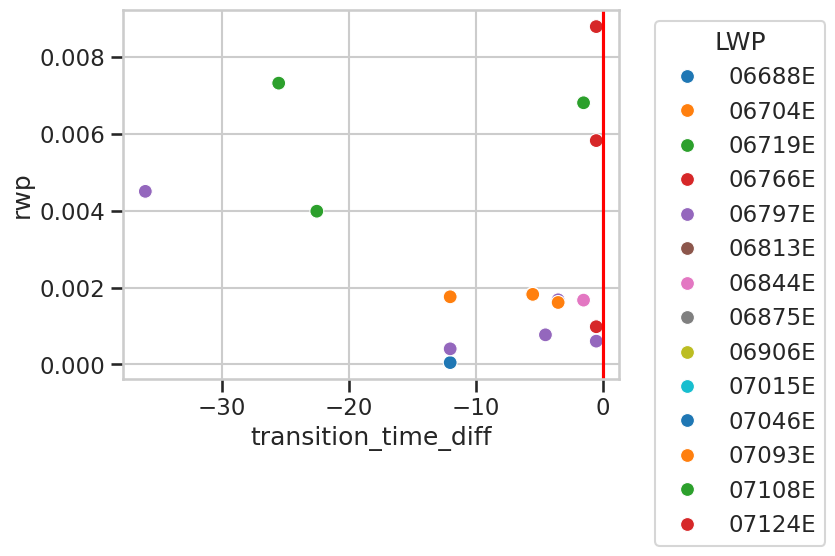

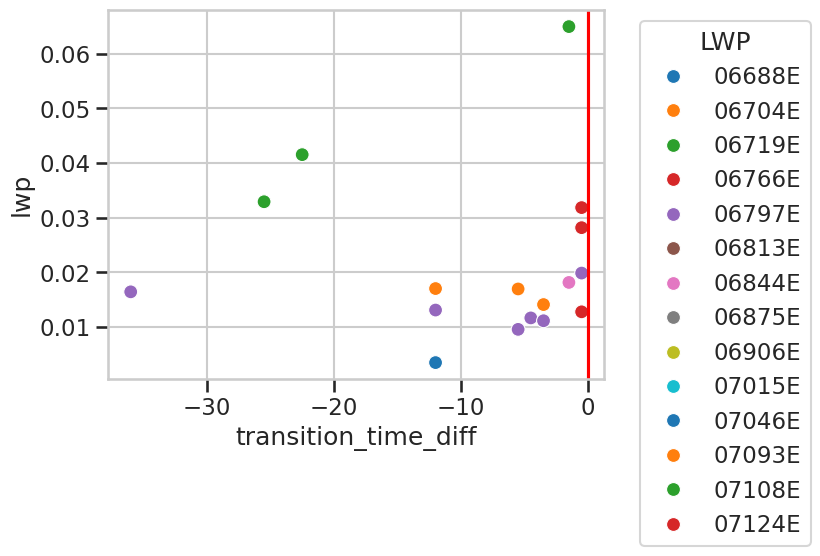

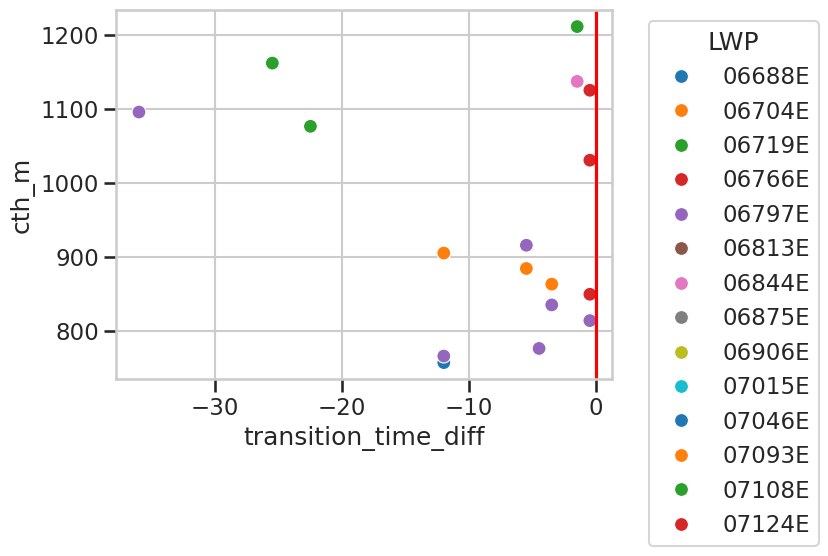

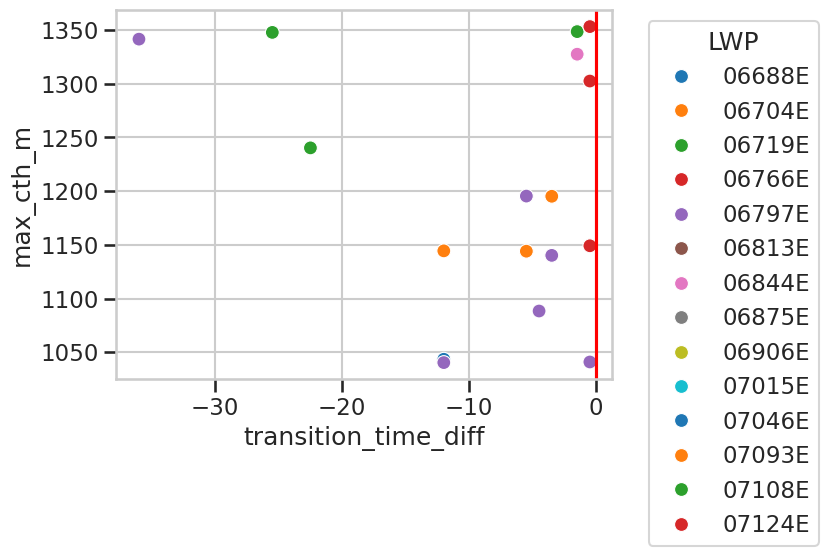

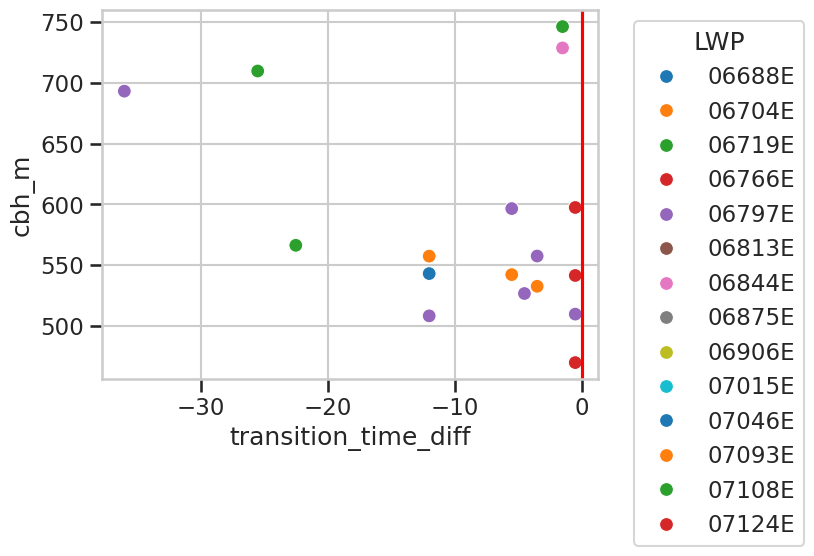

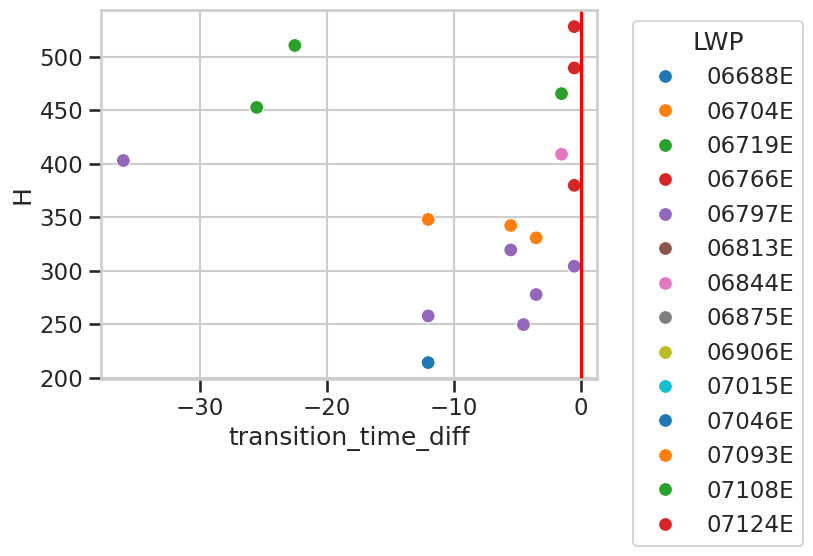

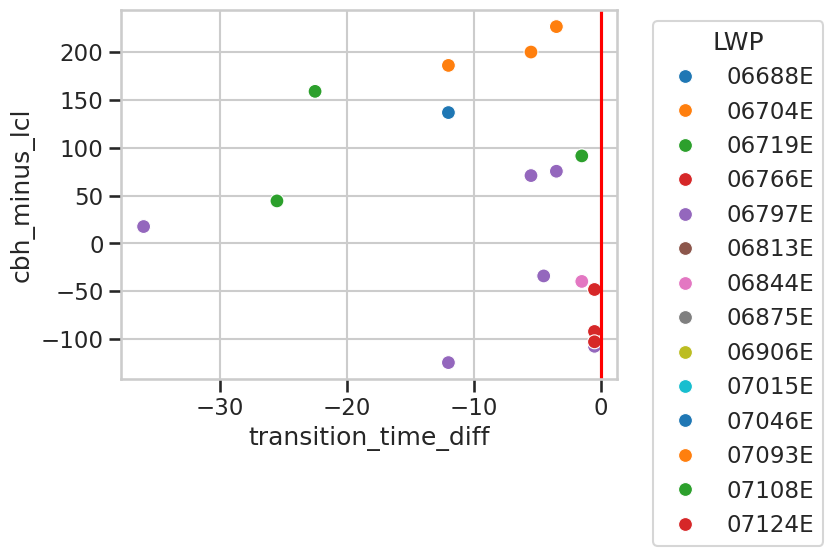

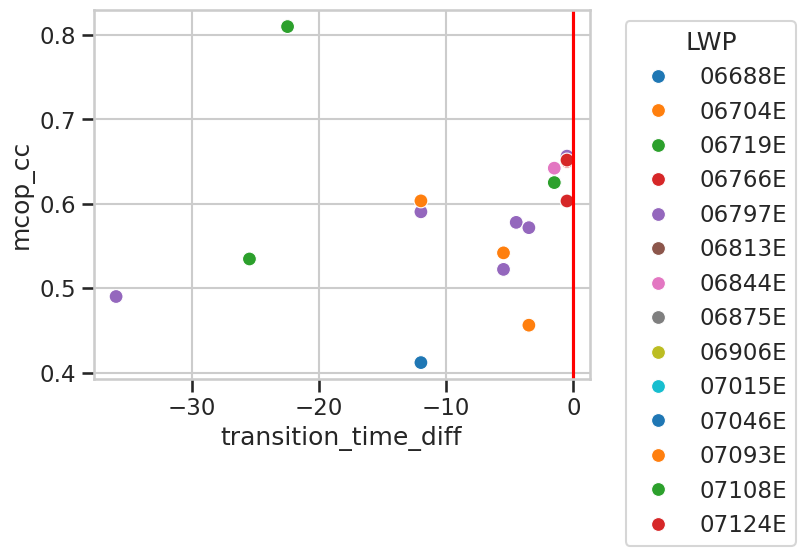

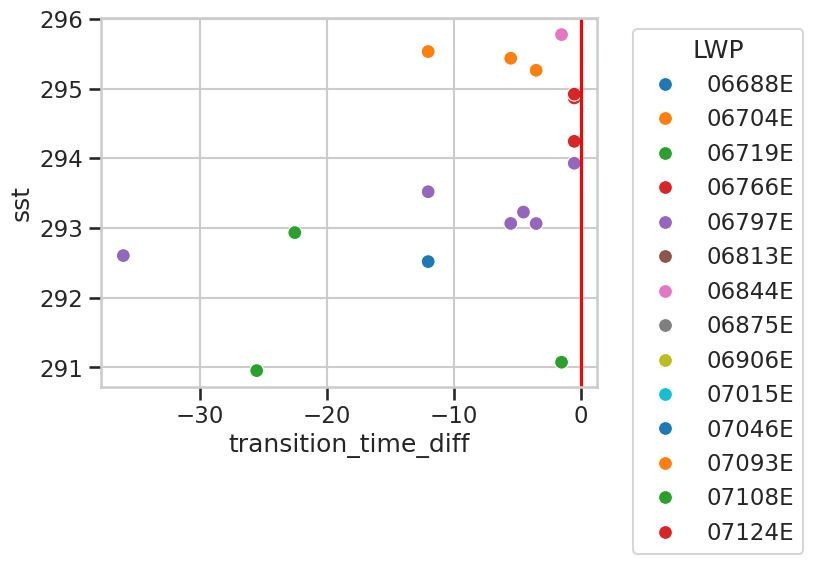

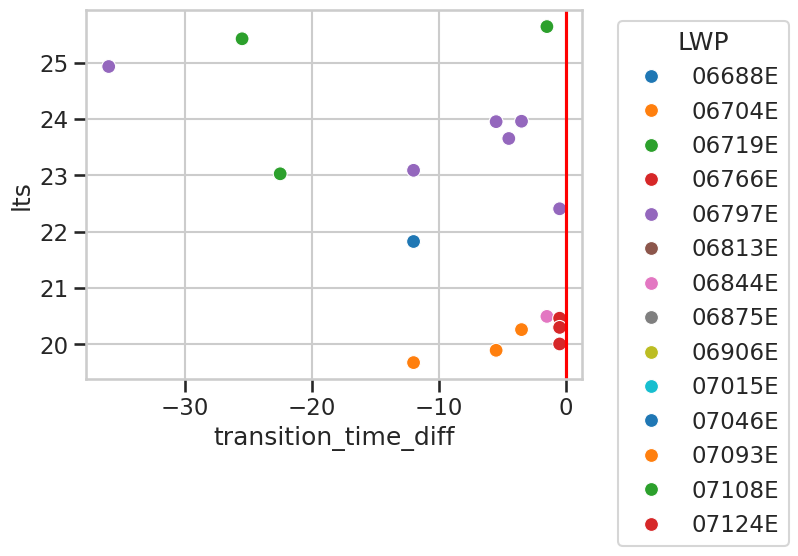

In [92]:
sns.set_context('talk', font_scale=1)
sns.set_style('whitegrid')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False
for var in ['rwp', 'lwp', 'cth_m','max_cth_m', 'cbh_m', 'H', 'cbh_minus_lcl', 'mcop_cc', 'sst', 'lts']:
    sns.scatterplot(data = bt_oc_forward_from_o, x='transition_time_diff', y=var, hue='orbit_startpoint', palette='tab10', legend=True, s=100)
    
    plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.axvline(0, color='red', linestyle='-')
    plt.show()

### CD transitions

In [25]:
bt_cd_forward_from_c = add_acmcap_info_to_bt(bt_cd_forward_from_c, acmcap, transition_from_msi_cats=[0,1])

bt_cd_back_from_d = add_acmcap_info_to_bt(bt_cd_back_from_d, acmcap, transition_from_msi_cats=[3,4])

2025-08-03T19:10:56.995927488
CATS_1 = [0, 1] match confirmed
2025-08-03T19:11:05.059994048
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-03T19:11:13.124058048
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-03T19:11:21.188121024
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:50:56.331499904
No CATS = [0, 1] match found
2025-08-04T19:51:04.395564992
No CATS = [0, 1] match found
2025-08-04T19:51:12.459630080
CATS_0 = [0, 1] match confirmed
2025-08-04T19:51:20.523695040
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:51:28.587759936
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:51:36.651825920
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:51:44.715890944
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:51:52.779956032
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-0

2025-08-04T19:51:52.779956032
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:52:00.844020928
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:52:08.908085952
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:52:16.972154496
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:52:25.036222976
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:52:33.100288448
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:52:41.164353984
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:52:49.228418944
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:52:57.292484032
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:53:05.356549120
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-04T19:53:21.484679552
CATS_0 = [0, 1] match confirme

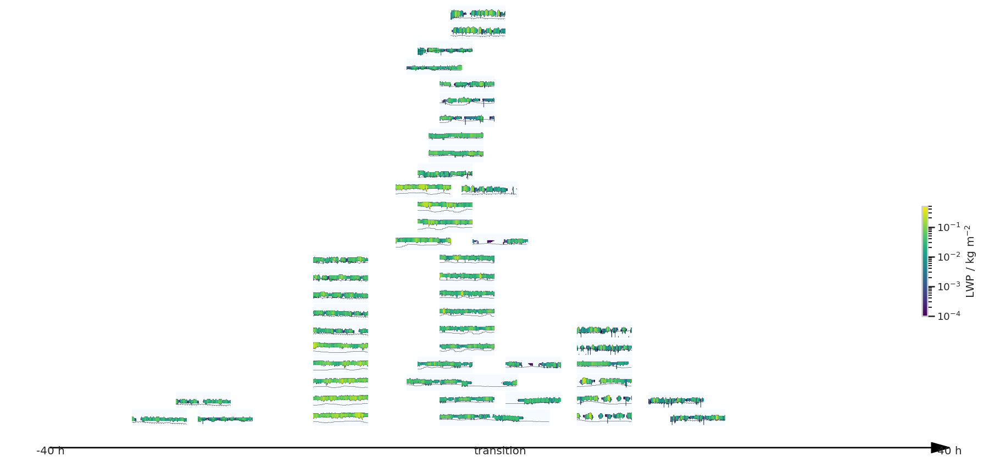

In [23]:
# create a big figure with many small subplots (like peek_at_acmcap) to compare the different trajectory sets
# the subplots are at x-positions determined by the transition_time_diff values, and y-positions determined s.t. plots dont overlap
hue_variable = 'lwp'  # can be 'rain_rate_cbh', 'lwp'

fig = plt.figure(figsize=(20, 10))
# Track occupied positions to avoid overlaps
occupied_positions = []  # List of (left, right, bottom, top) rectangles
subplot_width = 0.05
subplot_height = 0.03

#transition_times = bt_dataset.transition_time_diff.values
#valid_times = transition_times[~np.isnan(transition_times)]
#time_min, time_max = valid_times.min(), valid_times.max()
time_min, time_max = -40, 40

sns.set_context('talk', font_scale=0.8)

for bt_dataset, transition_from_msi_cats in [
    (bt_cd_forward_from_c.where(~np.isnan(bt_cd_forward_from_c.transition_time_diff), drop=True), [0, 1]),
    (bt_cd_back_from_d.where(~np.isnan(bt_cd_back_from_d.transition_time_diff), drop=True), [3,4])
    ]:


    for i, t_ in enumerate(bt_dataset.time_startpoint.values):
        print(t_)
        orbit = bt_dataset.sel(time_startpoint=t_).orbit_startpoint.values
        acmcap_orbit = acmcap[acmcap.orbit == orbit]
        acmcap_time_startpoint = acmcap_orbit[np.abs(pd.to_datetime(acmcap_orbit.time) - pd.to_datetime(t_)) < pd.Timedelta('0.1s')]
        # check
        scene_0_matches = False
        scene_1_matches = False
        if np.isin(np.unique(acmcap_time_startpoint.cats_0), transition_from_msi_cats):
            print(f'CATS_0 = {transition_from_msi_cats} match confirmed')
            scene_0_matches = True
            scene_id_0 = np.unique(acmcap_time_startpoint.scene_id_0)
        if np.isin(np.unique(acmcap_time_startpoint.cats_1), transition_from_msi_cats):
            print(f'CATS_1 = {transition_from_msi_cats} match confirmed')
            scene_1_matches = True
            scene_id_1 = np.unique(acmcap_time_startpoint.scene_id_1)

        time_to_trans = bt_dataset.sel(time_startpoint=t_).transition_time_diff.values
        if pd.isna(time_to_trans):
            continue

        if scene_0_matches and scene_1_matches:
            acmcap_orbit_0 = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0[0]]
            tmp_latmax, tmp_latmin = acmcap_orbit_0.latitude.max(), acmcap_orbit_0.latitude.min()
            acmcap_orbit_1 = acmcap_orbit[(acmcap_orbit.scene_id_1 == scene_id_1[0]) & ((acmcap_orbit.latitude > tmp_latmax) | (acmcap_orbit.latitude < tmp_latmin))]  # remove overlapping latitudes
            tmp_scene = pd.concat([acmcap_orbit_0, acmcap_orbit_1])
            tmp_scene = tmp_scene.sort_values(by='latitude')
            scene_id = f'{scene_id_0[0]} & {scene_id_1[0]}'
        elif scene_0_matches:
            tmp_scene = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0[0]]
            scene_id = f'{scene_id_0[0]}'
        elif scene_1_matches:
            tmp_scene = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1[0]]
            scene_id = f'{scene_id_1[0]}'
        else:
            continue  # Skip plotting if no matches

        def add_profile(profile_arr, cbh_m, cth_m):
            # between dfex.cbh_m and dfex.cth_m (both arrays of size 113), the profile_arr should be filled with 1
            for i in range(len(cth_m)):
                cbh = cbh_m.values[i]
                cth = cth_m.values[i]
                if np.isnan(cbh) or np.isnan(cth):
                    continue
                cbh_idx = int(cbh // 100)
                cth_idx = int(cth // 100)
                # Ensure indices are within bounds
                cbh_idx = max(0, min(cbh_idx, profile_arr.shape[1] - 1))
                cth_idx = max(0, min(cth_idx, profile_arr.shape[1] - 1))
                profile_arr[i, cbh_idx:cth_idx+1] += 1
            return profile_arr
        
        x_length = len(tmp_scene.latitude)
        profile_arr = xr.DataArray(np.zeros((x_length, 20)), dims=['latitude', 'height'], coords={'latitude': tmp_scene.latitude.values, 'height': np.arange(20)*100})
        profile_arr = add_profile(profile_arr, tmp_scene.cbh_m, tmp_scene.cth_m)


        # add axes to the big figure at the correct position
        # Calculate normalized position
        #norm_x = (time_to_trans - time_min) / (time_max - time_min)
        ## Position the subplot
        #left = 0.1 + norm_x * 0.8  # Use 80% of figure width
        #bottom = 0.1 + (i % 5) * 0.15  # Stack multiple rows if needed
        #width = 0.15
        #height = 0.05
        #ax = fig.add_axes([left, bottom, width, height])
        
        # Calculate normalized x position
        norm_x = (time_to_trans - time_min) / (time_max - time_min)
        left = 0.1 + norm_x * 0.8  # Use 80% of figure width
        right = left + subplot_width
        
        # Find available vertical position
        bottom = 0.1  # Start from bottom
        found_position = False
        
        while not found_position:
            top = bottom + subplot_height
            
            # Check if this position overlaps with any existing subplot
            overlaps = False
            for occupied in occupied_positions:
                occ_left, occ_right, occ_bottom, occ_top = occupied
                
                # Check for overlap
                if (left < occ_right and right > occ_left and 
                    bottom < occ_top and top > occ_bottom):
                    overlaps = True
                    break
            
            if not overlaps:
                found_position = True
            else:
                bottom += subplot_height + 0.002  # Move up with small gap
        
        # Record this position as occupied
        occupied_positions.append((left, right, bottom, top))
        
        # Create the subplot
        ax = fig.add_axes([left, bottom, subplot_width, subplot_height])
        
        im1 = ax.imshow(profile_arr.T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='Blues')
        if hue_variable == 'rain_rate_cbh':
            im2 = ax.imshow((profile_arr * tmp_scene.rain_rate_cbh.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='viridis', norm=LogNorm(1e-7, 1e-4))
            #plt.colorbar(im2, ax=ax, label='RR / kg m$^{-2}$ s$^{-1}$')
        elif hue_variable == 'lwp':
            im2 = ax.imshow((profile_arr * tmp_scene.lwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='viridis', norm=LogNorm(1e-4, 5e-1))
            plt.plot(tmp_scene.lcl.values, color='black', lw=0.3)
            #plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
        #ax.set_xticks(ticks=np.linspace(0, x_length, 3), labels=[f'{lat:.2f}' for lat in np.linspace(tmp_scene.latitude.values[0], tmp_scene.latitude.values[-1], 3)])
        #ax.set_title(f'{orbit}, $\Delta$t={time_to_trans}, Scene ID {scene_id}')
        ax.set_axis_off()  # Turn off axis for small plots

#max_y_position = np.max([occupied_positions[i][1] for i in range(len(occupied_positions))])
ax = fig.add_axes([0.9, 0.3, 0.04, 0.2])  # Position for colorbar
if hue_variable == 'rain_rate_cbh':
    plt.colorbar(im2, ax=ax, label='RR / kg m$^{-2}$ s$^{-1}$')
elif hue_variable == 'lwp':
    plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
ax.set_axis_off()

# plot one big time arrow at the bottom to indicate time axis
ax = fig.add_axes([0.1, 0.05, 0.9, 0.02])  # Position for time axis
ax.arrow(0, 0.5, 1, 0, head_width=0.03, head_length=0.02, length_includes_head=True, fc='black', ec='black')
ax.text(0, 0.48, f'{time_min} h', ha='center')
ax.text(1, 0.48, f'{time_max} h', ha='center')
ax.text(0.5, 0.48, f'transition', ha='center')
ax.set_axis_off()

2025-08-03T19:10:56.995927488
No CATS = [3, 4] match found
2025-08-03T19:11:05.059994048
No CATS = [3, 4] match found
2025-08-03T19:11:13.124058048
No CATS = [3, 4] match found
2025-08-03T19:11:21.188121024
No CATS = [3, 4] match found
2025-08-04T19:50:56.331499904
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed


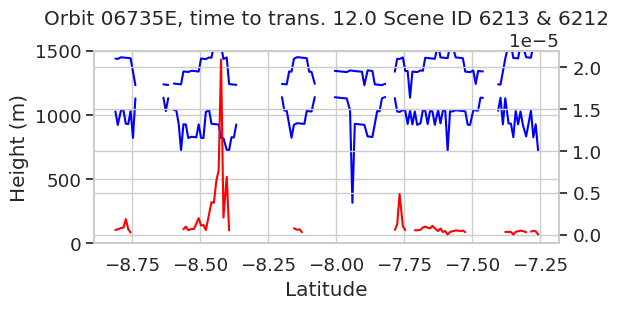

2025-08-04T19:51:04.395564992
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed


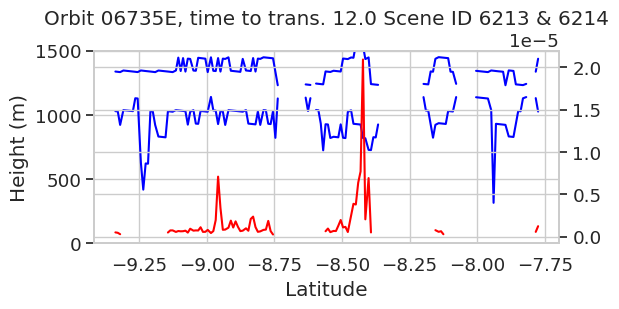

2025-08-04T19:51:12.459630080
CATS_1 = [3, 4] match confirmed


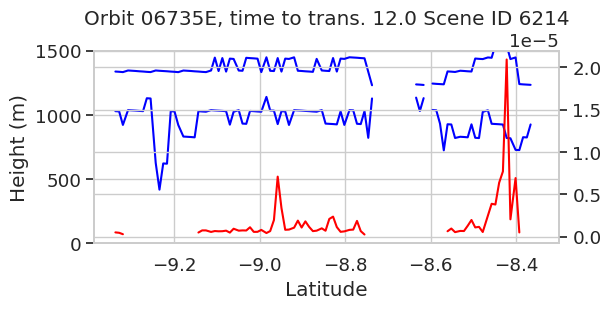

2025-08-04T19:51:20.523695040
No CATS = [3, 4] match found
2025-08-04T19:51:28.587759936
No CATS = [3, 4] match found
2025-08-04T19:51:36.651825920
No CATS = [3, 4] match found
2025-08-04T19:51:44.715890944
No CATS = [3, 4] match found
2025-08-04T19:51:52.779956032
No CATS = [3, 4] match found
2025-08-04T19:52:00.844020928
No CATS = [3, 4] match found
2025-08-04T19:52:08.908085952
No CATS = [3, 4] match found
2025-08-04T19:52:16.972154496
No CATS = [3, 4] match found
2025-08-04T19:52:25.036222976
No CATS = [3, 4] match found
2025-08-04T19:52:33.100288448
No CATS = [3, 4] match found
2025-08-04T19:52:41.164353984
No CATS = [3, 4] match found
2025-08-04T19:52:49.228418944
No CATS = [3, 4] match found
2025-08-04T19:52:57.292484032
No CATS = [3, 4] match found
2025-08-04T19:53:05.356549120
No CATS = [3, 4] match found
2025-08-04T19:53:13.420614016
No CATS = [3, 4] match found
2025-08-04T19:53:21.484679552
No CATS = [3, 4] match found
2025-08-04T19:53:29.548744512
No CATS = [3, 4] match fou

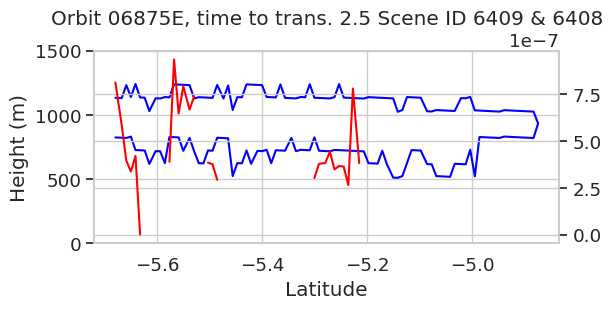

2025-08-13T19:46:35.314462016
CATS_0 = [3, 4] match confirmed


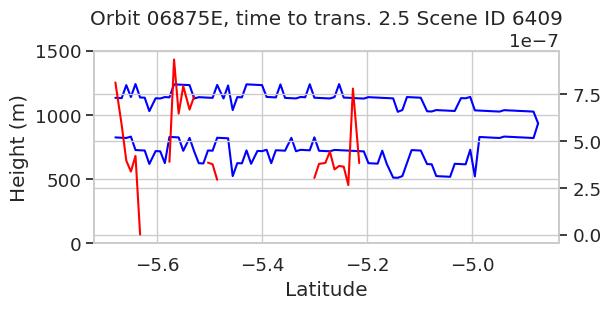

2025-08-13T19:46:43.378524928
No CATS = [3, 4] match found
2025-08-13T19:46:51.442588992
No CATS = [3, 4] match found
2025-08-13T19:46:59.506652544
CATS_0 = [3, 4] match confirmed
2025-08-13T19:47:07.570715968
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed
2025-08-13T19:47:15.634780032
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed
2025-08-13T19:47:23.698842944
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed
2025-08-13T19:47:31.762907008
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed
2025-08-13T19:47:39.826971008
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed


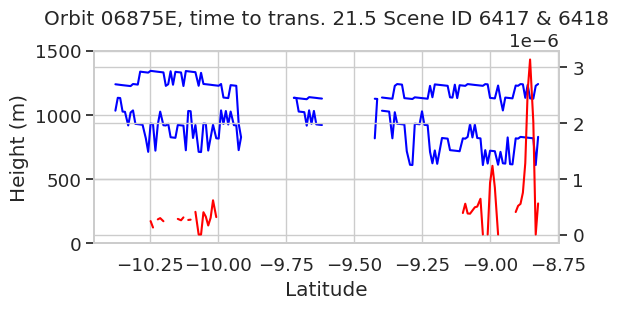

2025-08-13T19:47:47.891034112
CATS_1 = [3, 4] match confirmed


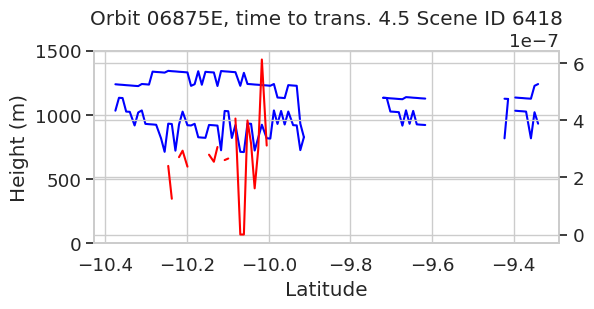

2025-08-17T19:25:07.155596928
No CATS = [3, 4] match found
2025-08-17T19:25:15.219660096
No CATS = [3, 4] match found
2025-08-17T19:25:23.283724096
No CATS = [3, 4] match found
2025-08-18T20:04:35.425642880
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed


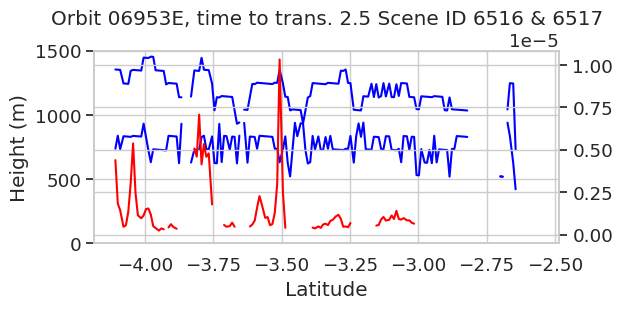

2025-08-18T20:04:43.489705984
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed


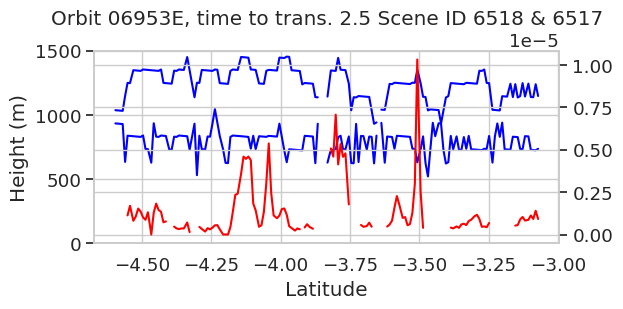

2025-08-18T20:04:51.553769856
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed


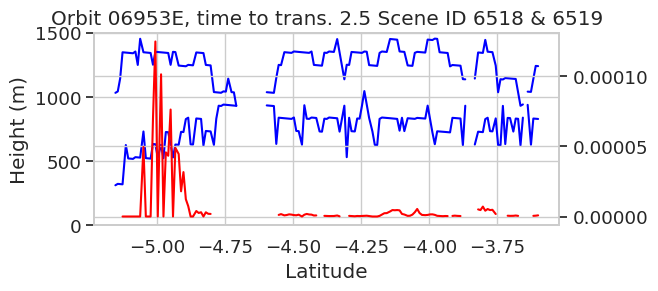

2025-08-20T19:54:01.236865920
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed
2025-08-20T19:54:09.300929920
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed
2025-08-20T19:54:17.364993024
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed
2025-08-20T19:54:25.429057024
CATS_0 = [3, 4] match confirmed
CATS_1 = [3, 4] match confirmed
2025-08-20T19:54:33.493120064
CATS_0 = [3, 4] match confirmed


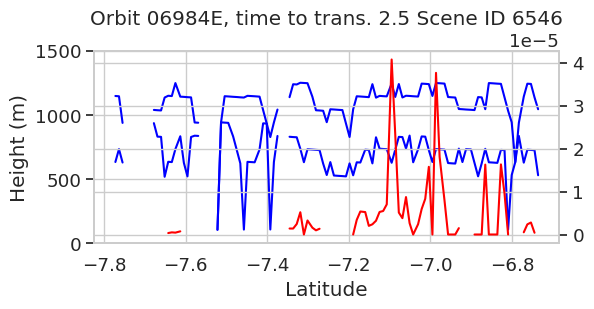

<xarray.Dataset> Size: 585kB
Dimensions:                 (time_startpoint: 84, timestep: 85)
Coordinates:
  * time_startpoint         (time_startpoint) datetime64[ns] 672B 2025-08-03T...
  * timestep                (timestep) int64 680B -42 -41 -40 -39 ... 40 41 42
Data variables: (12/28)
    lat_traj                (time_startpoint, timestep) float64 57kB nan ... nan
    lon_traj                (time_startpoint, timestep) float64 57kB nan ... nan
    plev_traj               (time_startpoint, timestep) float64 57kB nan ... nan
    datetime_traj           (time_startpoint, timestep) datetime64[ns] 57kB N...
    goes_lat_match          (time_startpoint, timestep) float64 57kB nan ... nan
    goes_lon_match          (time_startpoint, timestep) float64 57kB nan ... nan
    ...                      ...
    cbh_m                   (time_startpoint) float64 672B nan nan ... 676.4
    H                       (time_startpoint) float64 672B nan nan ... 413.6
    cbh_minus_lcl           (time_startpoint) float64 672B nan nan ... -42.91
    mcop_cc                 (time_startpoint) float64 672B nan nan ... 0.7253
    sst                     (time_startpoint) float64 672B nan nan ... 295.7
    lts                     (time_startpoint) float64 672B nan nan ... 19.69

In [21]:
# look at example profiles
tmp = bt_cd_back_from_d
add_acmcap_info_to_bt(tmp, acmcap, transition_from_msi_cats=[3,4], peek_at_acmcap_clouds=True)

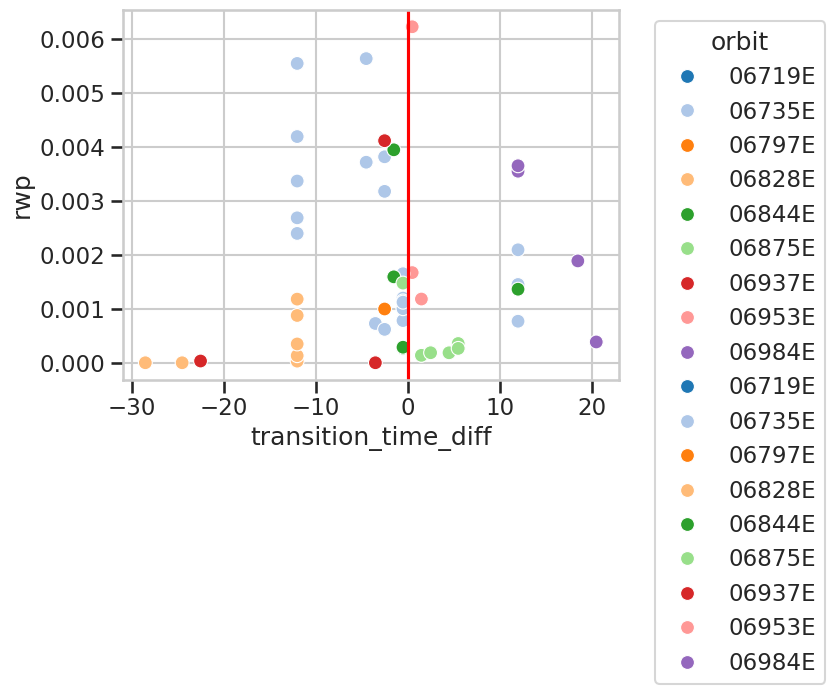

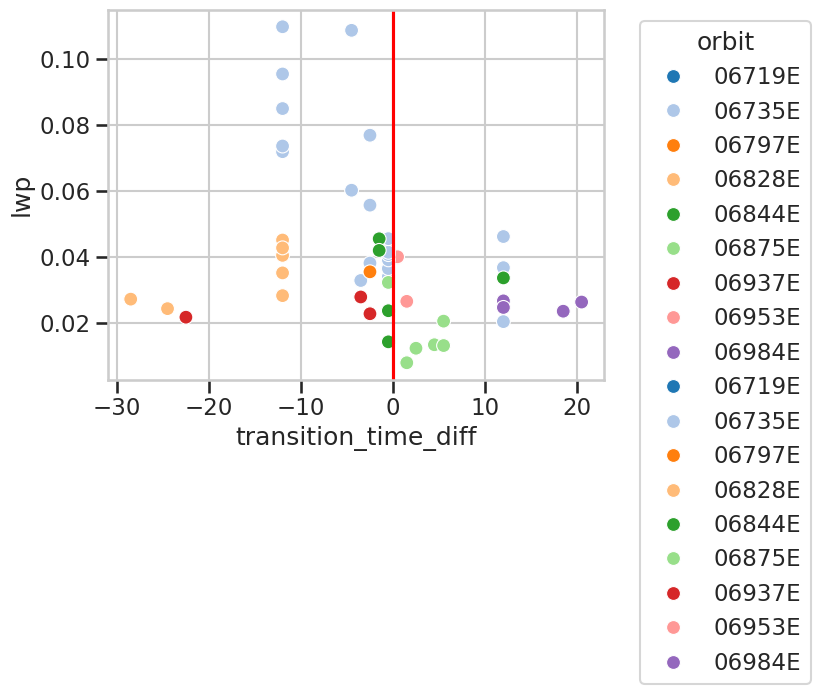

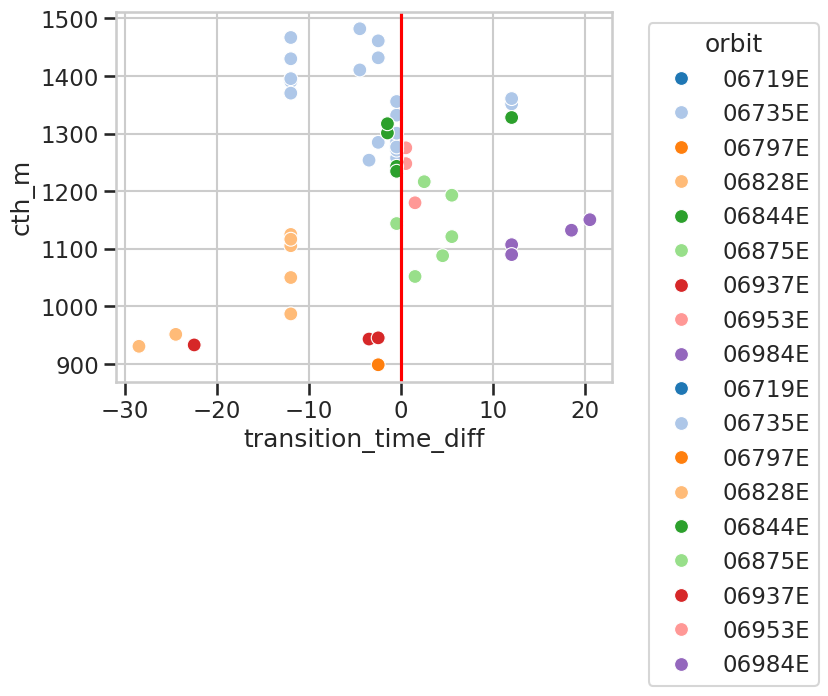

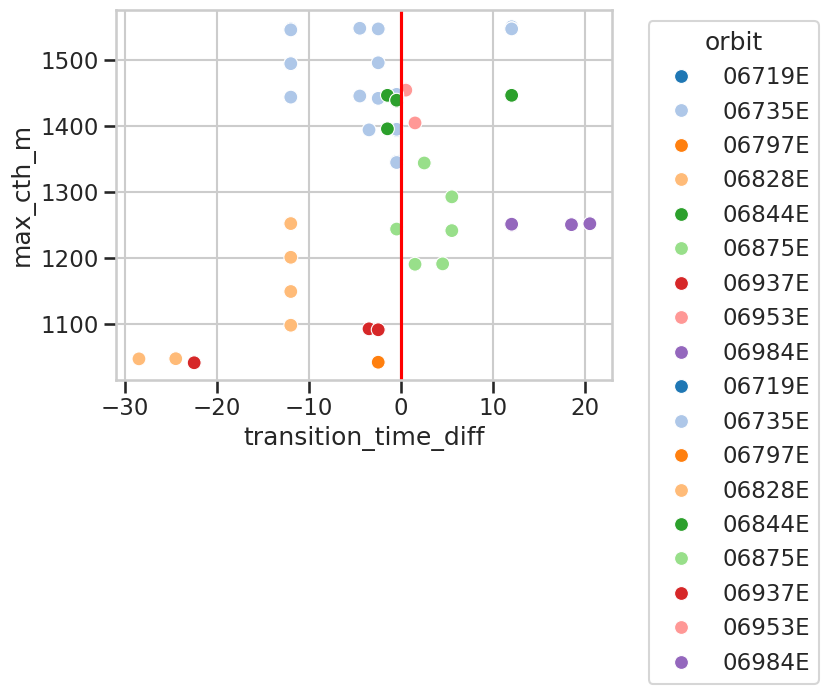

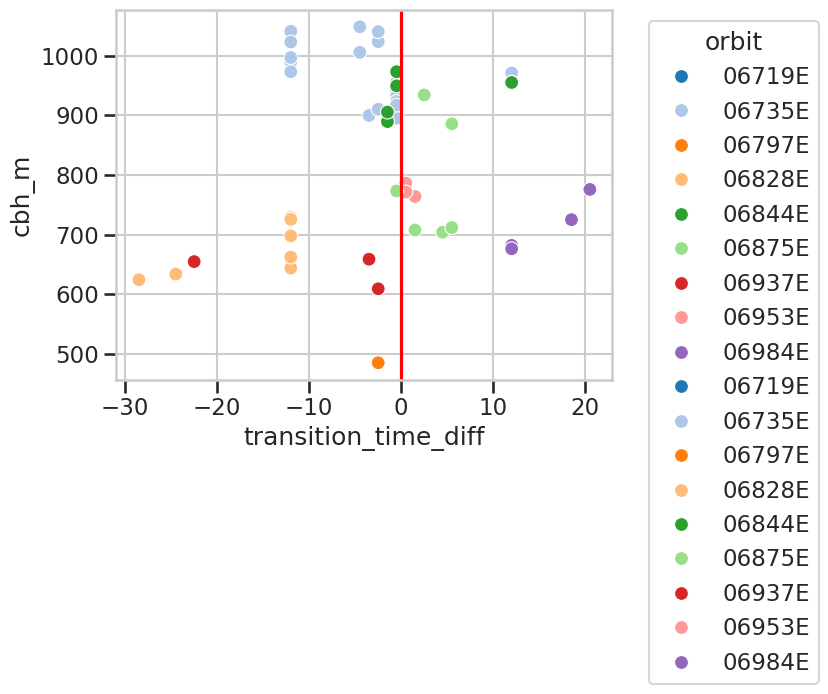

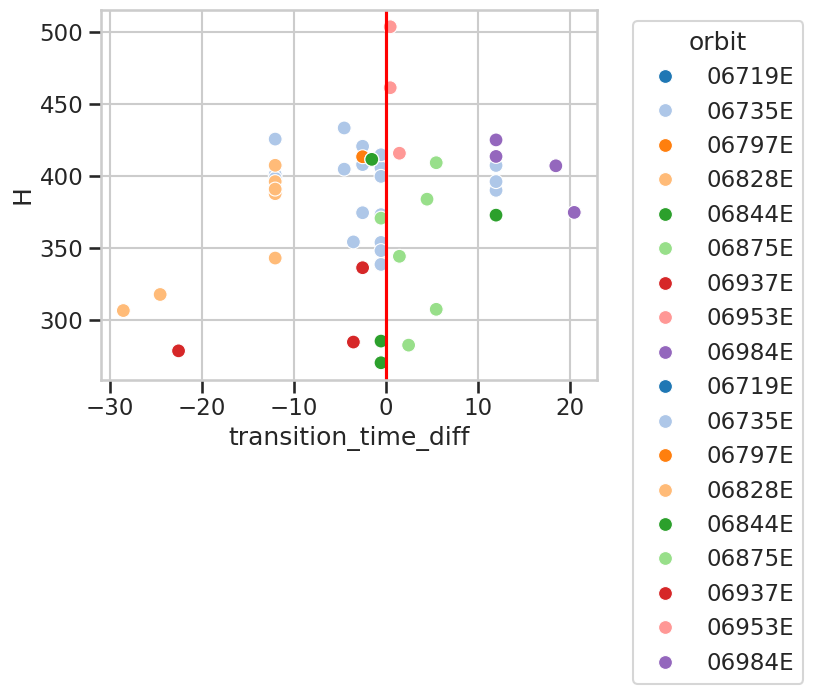

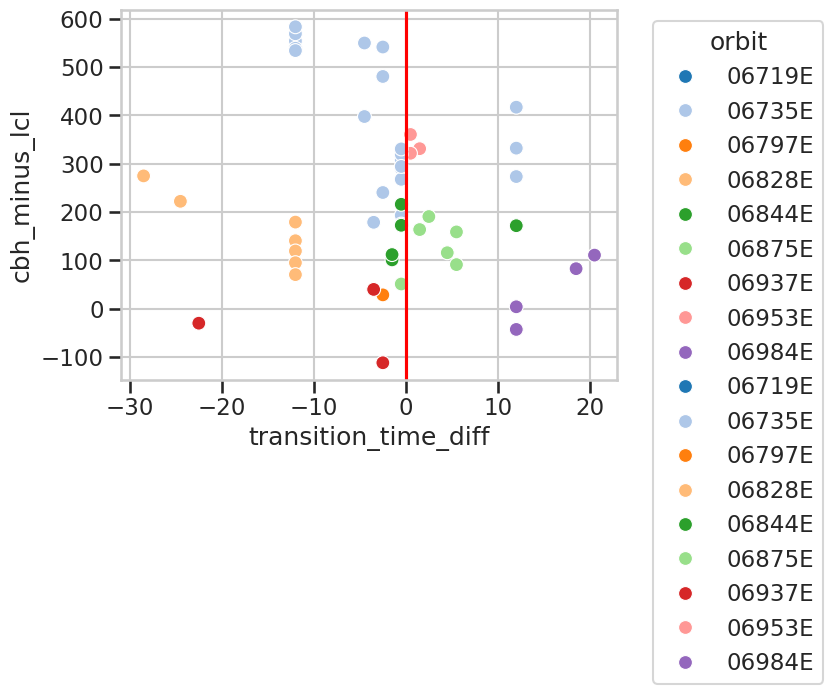

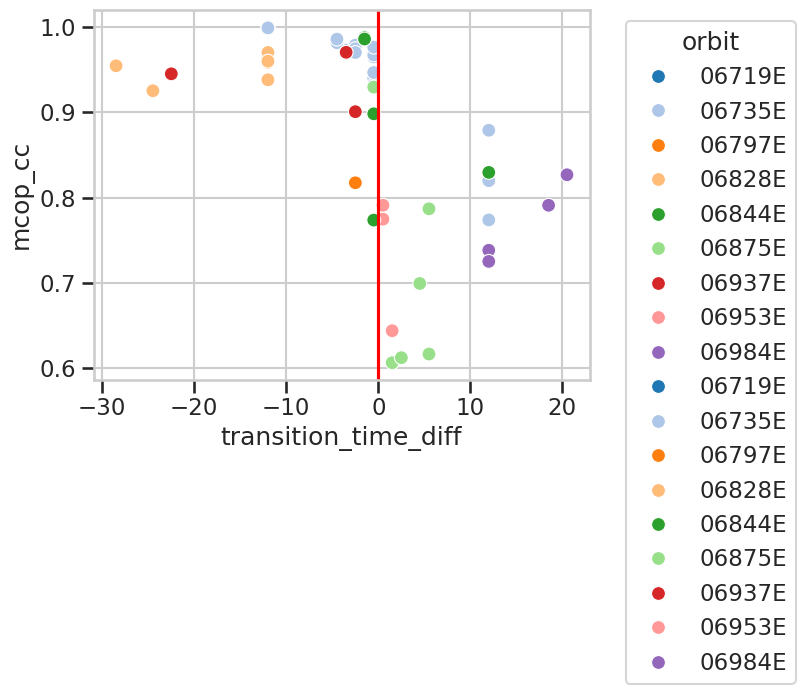

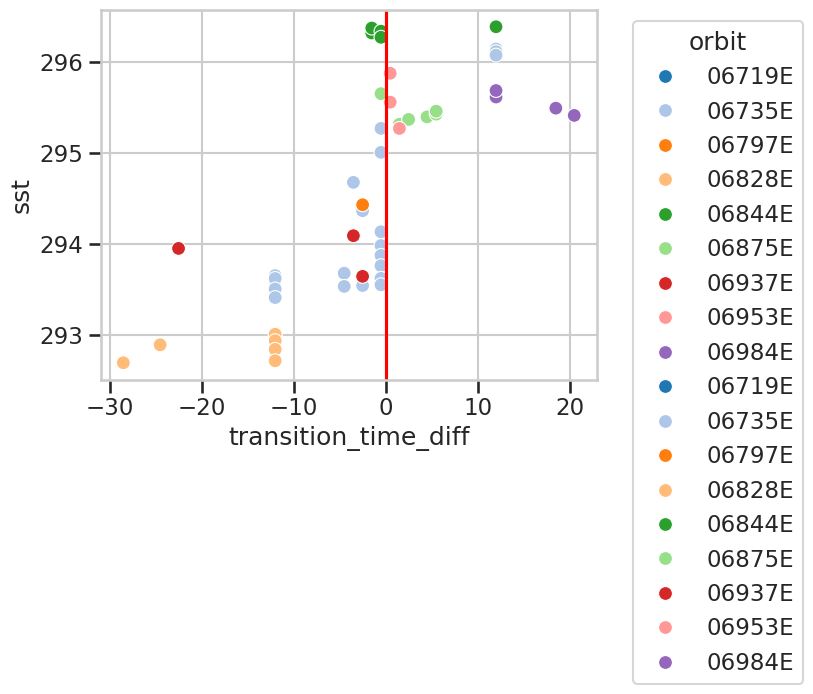

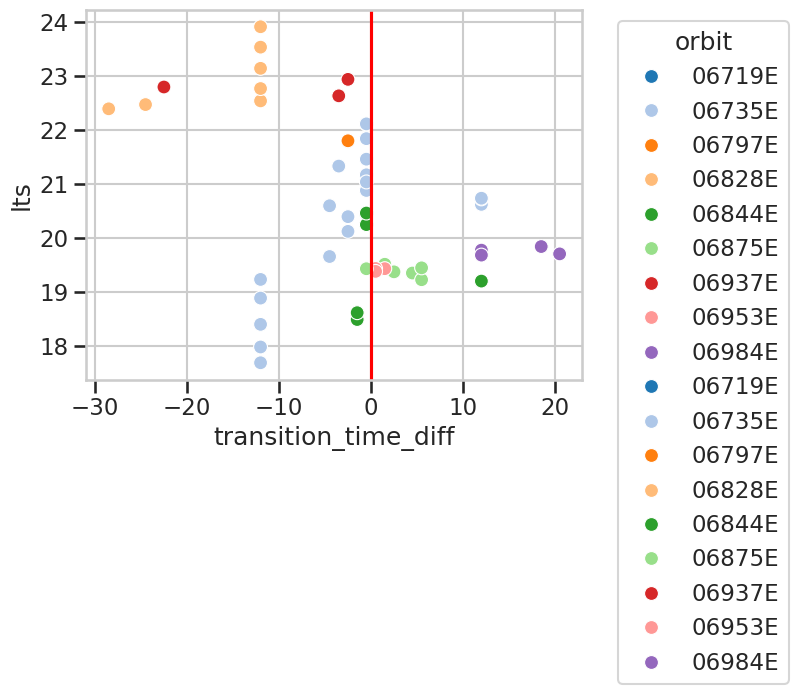

In [24]:
sns.set_context('talk', font_scale=1)
sns.set_style('whitegrid')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False
for var in ['rwp', 'lwp', 'cth_m','max_cth_m', 'cbh_m', 'H', 'cbh_minus_lcl', 'mcop_cc', 'sst', 'lts']:
    #sns.scatterplot(data = bt_cd_back_from_d, x='transition_time_diff', y=var, hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
    #sns.scatterplot(data = bt_cd_forward_from_c, x='transition_time_diff', y=var, hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
    #plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')

    sns.scatterplot(data = bt_cd_back_from_d, x='transition_time_diff', y=var, hue='orbit_startpoint', palette='tab20', legend=True, s=100)
    sns.scatterplot(data = bt_cd_forward_from_c, x='transition_time_diff', y=var, hue='orbit_startpoint', palette='tab20', legend=True, s=100)
    plt.legend(title='orbit', bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.axvline(0, color='red', linestyle='-')
    plt.show()